# Predviđanje PM2.5 i PM10 — Priprema podataka

## Tačka 2: Prikupljanje i priprema podataka

In [1]:
import pandas as pd
import openpyxl
import re
import unicodedata
import numpy as np
import sklearn
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 200)

Poznati "prljavi" sufiksi/aliasi otkriveni pregledom fajlova

In [2]:
GARBAGE_COLUMN_NAMES = {'dan', 'mesec', 'godina', 'datum', 'vreme', 'god', 'nan', 'none'}

STATION_ALIASES = {
    'beograd n beograd': 'beograd novi beograd',
    'vracar': 'beograd vracar',
    'zajacar': 'zajecar',
    'smederevo -radinac': 'smederevo radinac',
    'ns liman': 'novi sad liman',
    'smedervo centar': 'smederevo centar',
}

def is_garbage_column(name):
    """Prepoznaje kolone koje nisu prave stanice (ostaci lošeg parsiranja datuma)."""
    if name is None:
        return True
    n = str(name).strip().lower()
    return n in GARBAGE_COLUMN_NAMES or n.startswith('unnamed')

def normalize_station(name):
    """Svodi naziv stanice na standardni oblik radi poredjenja kroz godine."""
    if name is None:
        return None
    name = str(name).strip()
    # ukloni sve od 'AOP' nadalje (npr. 'Beočin Centar AOP PM10 μg.m-3')
    name = re.sub(r'\s*AOP\b.*$', '', name, flags=re.IGNORECASE)
    # ukloni sufiks tipa 'PM10 μg.m-3' / 'PM2.5' dodat na kraj
    name = re.sub(r'\s*PM\s?2[.,]?\s?5\b.*$', '', name, flags=re.IGNORECASE)
    name = re.sub(r'\s*PM\s?10\b.*$', '', name, flags=re.IGNORECASE)
    name = name.replace('_', ' ').replace('.', ' ').replace('"', '')
    name = re.sub(r'\s+', ' ', name)
    name_ascii = unicodedata.normalize('NFKD', name).encode('ascii', 'ignore').decode('ascii')
    result = name_ascii.strip().lower()
    return STATION_ALIASES.get(result, result)

In [3]:
# Test primeri - da vidimo da normalize_station() radi kako treba
test_nazivi = [
    "Beograd Vracar",
    "Vracar",
    "Beočin Centar AOP PM10 μg.m-3",
    "Kosjerić",
    "  Beograd Mostar     ",
    "dan",
]

for naziv in test_nazivi:
    print(f"{naziv!r:45s} -> {normalize_station(naziv)!r}")

print()
print("Da li je 'dan' prepoznat kao garbage kolona?", is_garbage_column("dan"))
print("Da li je 'Valjevo' prepoznat kao garbage kolona?", is_garbage_column("Valjevo"))

'Beograd Vracar'                              -> 'beograd vracar'
'Vracar'                                      -> 'beograd vracar'
'Beočin Centar AOP PM10 μg.m-3'               -> 'beocin centar'
'Kosjerić'                                    -> 'kosjeric'
'  Beograd Mostar     '                       -> 'beograd mostar'
'dan'                                         -> 'dan'

Da li je 'dan' prepoznat kao garbage kolona? True
Da li je 'Valjevo' prepoznat kao garbage kolona? False


In [4]:
def _is_date_header(val):
    """Da li kolona izgleda kao zaglavlje kolone sa datumom (npr. 'Datum', 'Vreme')."""
    if val is None:
        return False
    v = str(val).strip().lower()
    return v in ('datum', 'vreme')

def load_sheet_raw(filepath, sheet_name):
    """Ucitava sheet kao listu DataFrame-ova.
    Sređuje podatke 'zgnjecene' u jednu kolonu, razdvojene sa ';' (npr. 2016, 2018) i 
    vise odvojenih blokova tabela jedna pored druge u istom sheet-u (npr. 2021, 2022 PM10).
    """
    wb = openpyxl.load_workbook(filepath, read_only=True)
    ws = wb[sheet_name]
    rows = list(ws.iter_rows(values_only=True))
    header = rows[0]

    # Slučaj 1: jedna kolona koja sadrži ';' u header-u
    if len(header) == 1 and header[0] and ';' in str(header[0]):
        columns = str(header[0]).split(';')
        data = []
        for row in rows[1:]:
            if row[0] is None:
                continue
            parts = str(row[0]).split(';')
            parts += [None] * (len(columns) - len(parts))
            data.append(parts[:len(columns)])
        df = pd.DataFrame(data, columns=columns).rename(columns={columns[0]: 'Datum'})
        df = df.loc[:, df.columns.notna()]
        df = df.loc[:, [c for c in df.columns if str(c).strip() != '']]
        df = df.loc[:, ~df.columns.duplicated()]
        keep = ['Datum'] + [c for c in df.columns[1:] if not is_garbage_column(c)]
        return [df[keep]]

    # Slučaj 2: potencijalno više blokova - nađi sve pozicije kolona koje izgledaju kao datum
    date_col_positions = [i for i, h in enumerate(header) if _is_date_header(h)]
    if len(date_col_positions) == 0:
        date_col_positions = [0]

    blocks = []
    for idx, start in enumerate(date_col_positions):
        end = date_col_positions[idx + 1] if idx + 1 < len(date_col_positions) else len(header)
        block_header = list(header[start:end])
        block_rows = [row[start:end] for row in rows[1:]]
        block_df = pd.DataFrame(block_rows, columns=block_header)
        first_col = block_df.columns[0]
        block_df = block_df.rename(columns={first_col: 'Datum'})
        ostale = block_df.columns[1:]
        ostale_ok = [c for c in ostale if pd.notna(c) and str(c).strip() != '']
        block_df = block_df[['Datum'] + ostale_ok]
        block_df = block_df.loc[:, ~block_df.columns.duplicated()]
        if block_df.shape[1] < 2:
            continue
        keep = ['Datum'] + [c for c in block_df.columns[1:] if not is_garbage_column(c)]
        block_df = block_df[keep]
        if block_df.shape[1] < 2:
            continue
        blocks.append(block_df)

    return blocks

In [5]:
# Test 1: 2016 godina - PM2.5 je bio "zgnječen" u jednu kolonu (';'-razdvojen)
print("=== Test: 2016 PM2.5 (zgnjeceni format) ===")
blokovi = load_sheet_raw('2016.xlsx', '2016-pm2-5')
print(f"Broj blokova: {len(blokovi)}")
print(f"Kolone: {list(blokovi[0].columns)}")
print(blokovi[0].head(3))

print()

# Test 2: 2021 godina - PM10 ima dva odvojena bloka tabela u istom sheet-u
print("=== Test: 2021 PM10 (dupli blokovi) ===")
blokovi2 = load_sheet_raw('2021.xlsx', '2021-pm10')
print(f"Broj blokova: {len(blokovi2)}")
for i, b in enumerate(blokovi2):
    print(f"  Blok {i}: {b.shape[1]-1} stanica -> {list(b.columns[1:])}")

=== Test: 2016 PM2.5 (zgnjeceni format) ===
Broj blokova: 1
Kolone: ['Datum', 'Novi Sad_SPENS', 'Beograd_Stari grad', 'Beograd_N.Beograd']
      Datum Novi Sad_SPENS Beograd_Stari grad Beograd_N.Beograd
0  1.1.2016             50                 56                43
1  2.1.2016             51                                   43
2  3.1.2016             27                 35                28

=== Test: 2021 PM10 (dupli blokovi) ===
Broj blokova: 2
  Blok 0: 15 stanica -> ['Novi Sad Rumenačka AOP PM10 μg.m-3', 'Beočin Centar AOP PM10 μg.m-3', 'Beograd Stari grad AOP PM10 μg.m-3', 'Beograd Novi Beograd AOP PM10 μg.m-3', 'Beograd Mostar AOP PM10 μg.m-3', 'Beograd Vračar AOP PM10 μg.m-3', 'Smederevo Centar AOP PM10 μg.m-3', 'Obrenovac Centar AOP PM10 μg.m-3', 'Valjevo AOP PM10 μg.m-3', 'Kosjerić AOP PM10 μg.m-3', 'Popovac  AOP PM10 μg.m-3', 'Čačak  AOP PM10 μg.m-3', 'Niš O.š. Sveti Sava AOP PM10 μg.m-3', 'Niš IZJZ Niš AOP PM10 μg.m-3', 'Novi Pazar AOP PM10 μg.m-3']
  Blok 1: 10 stanica -> 

In [6]:
def find_sheet(wb, year, pollutant):
    """Pronadji ime sheet-a za dati zagadjivac, neosetljivo na velika/mala slova i separatore."""
    target = pollutant.lower().replace('.', '').replace('-', '').replace('_', '')
    for name in wb.sheetnames:
        cand = name.lower().replace('.', '').replace('-', '').replace('_', '')
        if cand == f'{year}{target}':
            return name
    return None

def load_pollutant_data(filepath, year, pollutant):
    """Ucitava PM10 ili PM2.5 podatke za datu godinu, vraca 'long' format:
    Datum, Stanica, Vrednost, Godina, Zagadjivac."""
    wb = openpyxl.load_workbook(filepath, read_only=True)
    sheet_name = find_sheet(wb, year, pollutant)
    if sheet_name is None:
        return None  # ne postoji za ovu godinu (npr. PM2.5 pre 2016)

    blocks = load_sheet_raw(filepath, sheet_name)
    long_frames = []

    for df in blocks:
        # Datum može biti u ISO ('2024-12-16'), evropskom ('01.01.2016') ili nativnom formatu
        iso_parsed = pd.to_datetime(df['Datum'], format='%Y-%m-%d', errors='coerce')
        eu_parsed = pd.to_datetime(df['Datum'], format='%d.%m.%Y', errors='coerce')
        generic_parsed = pd.to_datetime(df['Datum'], errors='coerce')
        df['Datum'] = iso_parsed.fillna(eu_parsed).fillna(generic_parsed)
        df = df.dropna(subset=['Datum'])

        station_cols = [c for c in df.columns if c != 'Datum']
        if not station_cols:
            continue
        for c in station_cols:
            df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '.'), errors='coerce')

        long_df = df.melt(id_vars='Datum', value_vars=station_cols,
                           var_name='Stanica_original', value_name='Vrednost')
        long_frames.append(long_df)

    if not long_frames:
        return None

    long_df = pd.concat(long_frames, ignore_index=True)
    long_df['Stanica'] = long_df['Stanica_original'].apply(normalize_station)
    long_df['Godina'] = year
    long_df['Zagadjivac'] = pollutant
    long_df = long_df.dropna(subset=['Vrednost'])

    # Ako više kolona mapira na istu (datum, stanica) - npr. duplirana kolona
    # u izvornom fajlu (otkriveno kod Beograd Vracar, 2020/2022) - uzimamo prosek
    long_df = long_df.groupby(['Datum', 'Stanica', 'Godina', 'Zagadjivac'], as_index=False).agg(
        Vrednost=('Vrednost', 'mean'),
        Stanica_original=('Stanica_original', 'first')
    )

    return long_df[['Datum', 'Stanica', 'Stanica_original', 'Vrednost', 'Godina', 'Zagadjivac']]

In [7]:
# Test na 2024 - godina za koju znamo da treba da ima 28 PM10 i 22 PM2.5 stanice
test_pm10 = load_pollutant_data('2024.xlsx', 2024, 'PM10')
test_pm25 = load_pollutant_data('2024.xlsx', 2024, 'PM2.5')

print(f"2024 PM10:  {len(test_pm10)} redova, {test_pm10['Stanica'].nunique()} stanica")
print(f"2024 PM2.5: {len(test_pm25)} redova, {test_pm25['Stanica'].nunique()} stanica")
print()
print(test_pm10.head())
print()

# Test da PM2.5 ne postoji za 2013 (treba da vrati None)
test_2013_pm25 = load_pollutant_data('2013.xlsx', 2013, 'PM2.5')
print("2013 PM2.5 (ocekujemo None jer PM2.5 pre 2016 ne postoji):", test_2013_pm25)

2024 PM10:  10051 redova, 28 stanica
2024 PM2.5: 8040 redova, 22 stanica

       Datum               Stanica           Stanica_original   Vrednost  Godina Zagadjivac
0 2024-01-01         beocin centar         Beočin Centar       21.115417    2024       PM10
1 2024-01-01        beograd mostar        Beograd Mostar       30.075000    2024       PM10
2 2024-01-01  beograd novi beograd  Beograd Novi Beograd       23.237917    2024       PM10
3 2024-01-01    beograd stari grad    Beograd Stari grad       22.689583    2024       PM10
4 2024-01-01        beograd vracar                     Vracar  24.120000    2024       PM10

2013 PM2.5 (ocekujemo None jer PM2.5 pre 2016 ne postoji): None


In [8]:
all_data = []
for year in range(2013, 2025):
    for pol in ['PM10', 'PM2.5']:
        res = load_pollutant_data(f'{year}.xlsx', year, pol)
        if res is not None:
            all_data.append(res)
        status = 'NE POSTOJI' if res is None else f'{len(res)} redova, {res["Stanica"].nunique()} stanica'
        print(f'{year} {pol:6s} -> {status}')

master = pd.concat(all_data, ignore_index=True)
print()
print(f'UKUPNO redova u spojenom datasetu: {len(master)}')

2013 PM10   -> 4937 redova, 15 stanica
2013 PM2.5  -> NE POSTOJI
2014 PM10   -> 3715 redova, 11 stanica
2014 PM2.5  -> NE POSTOJI
2015 PM10   -> 2273 redova, 7 stanica
2015 PM2.5  -> NE POSTOJI
2016 PM10   -> 1022 redova, 3 stanica
2016 PM2.5  -> 939 redova, 3 stanica
2017 PM10   -> 1635 redova, 5 stanica
2017 PM2.5  -> 308 redova, 1 stanica


C:\Users\Aleksandra\AppData\Local\Temp\ipykernel_9292\3547095078.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '.'), errors='coerce')


2018 PM10   -> 3272 redova, 10 stanica
2018 PM2.5  -> 973 redova, 3 stanica
2019 PM10   -> 6559 redova, 20 stanica
2019 PM2.5  -> 3950 redova, 12 stanica
2020 PM10   -> 7633 redova, 23 stanica
2020 PM2.5  -> 4258 redova, 13 stanica
2021 PM10   -> 7650 redova, 24 stanica
2021 PM2.5  -> 5288 redova, 16 stanica
2022 PM10   -> 22809 redova, 67 stanica
2022 PM2.5  -> 6826 redova, 19 stanica
2023 PM10   -> 7460 redova, 21 stanica
2023 PM2.5  -> 7697 redova, 22 stanica
2024 PM10   -> 10051 redova, 28 stanica
2024 PM2.5  -> 8040 redova, 22 stanica

UKUPNO redova u spojenom datasetu: 117295


### Ispravka ulaznih PM2.5 podataka (2019. i 2020.)

Provera originalnih Excel fajlova pokazala je dve greške u izvoru:

1. **Duplirane serije.** PM2.5 za *Obrenovac Centar* u 2019. i za *Popovac* u 2020. identičan je PM2.5 za *Kosjerić* (332 od 333, odnosno 323 od 325 zajedničkih dana). Zajednička serija prati PM10 Kosjerića (r ≈ 0,85), a ne PM10 Obrenovca ni Popovca, pa je to serija Kosjerića. Kopije se uklanjaju.
2. **Pomeraj za jedan dan (utvrđen statistički, vidi proveru ispod).** U fajlu za 2020. PM2.5 od 1. marta do kraja godine kasni jedan dan u odnosu na PM10: korelacija sa PM10 od prethodnog dana iznosi 0,91, a sa PM10 istog dana 0,72 (u januaru i februaru je 0,96 za isti dan). Ostale godine nemaju pomeraj (2019: 0,94, 2021: 0,89 za isti dan). Vrednost sa datumom *t* se premešta na datum *t − 1*; 29. 2. 2020. se izbacuje (preklapa se sa pomerenim danom).


**Provera prema izveštajima SEPA.** Godišnji proseci ispravljenih podataka upoređeni su sa godišnjim izveštajima Agencije za zaštitu životne sredine ([2019](https://sepa.gov.rs/wp-content/uploads/2024/10/Vazduh2019.pdf), [2020](https://sepa.gov.rs/wp-content/uploads/2024/10/Vazduh2020.pdf)). Za većinu stanica se slažu u okviru 1–3 µg/m³:

| Stanica | Godina | PM2.5 izveštaj | PM2.5 ovde | PM10 izveštaj | PM10 ovde |
|---|---|---|---|---|---|
| Kosjerić | 2019 | 30 | 29,3 | 49 | 48,9 |
| Kosjerić | 2020 | 38 | 39,0 | 56 | 55,7 |
| Valjevo | 2019 | 42 | 41,7 | 60 | 60,1 |
| Niš IZJZ | 2020 | 40 | 40,0 | 47 | 46,9 |
| Novi Pazar | 2020 | 41 | 40,3 | 52 | 51,8 |

Ovim je potvrđeno da PM2.5 serija pripisana Kosjeriću zaista pripada toj stanici (a kopije na drugim stanicama su uklonjene). Veće odstupanje postoji samo na pojedinim stanicama sa manje validnih dana (npr. PM10 Niš O.Š. Sveti Sava 2020: 49 u izveštaju, 39,6 ovde). **Pomeraj od jednog dana ovom proverom nije moguće potvrditi** jer ne menja godišnji prosek; za njega su dokaz korelacije navedene gore. Dnevne vrednosti za 2019. i 2020. nisu nađene u obliku pogodnom za poređenje.

#### Provera pomeraja PM2.5 u 2020. godini (pre ispravke)

U Excel fajlovima za 2020. nije pronađena konkretna greška u datumima: listovi za PM10 i PM2.5 imaju po 366 uzastopnih datuma, bez rupa i duplikata (prvi deo ćelije ispod). Pomeraj zato nije mogao biti potvrđen direktno u fajlu, već je zaključak donet iz samih podataka:

1. Upoređivan je PM2.5 na dan *t* sa PM10 na dan *t+k* (drugi deo ćelije ispod). Do kraja februara 2020. PM2.5 se najbolje slaže sa PM10 istog dana (0,96), zatim od 1. marta PM2.5 se slaže sa PM10 od prethodnog dana (0,91 prema 0,72). U 2019. i 2021. pomeraja nema.
2. Kao nezavisnu proveru iskorišćene su vremenske prilike (Open-Meteo/ERA5, ćelija posle učitavanja meteoroloških fajlova): posle 1. marta 2020. PM2.5 bolje prati vetar i padavine od prethodnog dana, dok PM10 (kontrola) i dalje prati vreme istog dana.

Pošto se uzrok ne vidi u samom fajlu, ispravka se smatra veoma verovatnom, ali ne i potpuno dokazanom.

In [9]:
# PROVERA POMERAJA PM2.5 U 2020. (izvršava se PRE ispravke)
# 1) Da li su datumi u učitanim tabelama uredni? (po jedan red za svaki dan, bez rupa i duplikata)
for pol in ['PM10', 'PM2.5']:
    dani = master[(master['Godina'] == 2020) & (master['Zagadjivac'] == pol)]['Datum'].drop_duplicates().sort_values()
    print(f"{pol} 2020: {len(dani)} različitih datuma, od {dani.min().date()} do {dani.max().date()}, "
          f"razmaci između datuma su uvek 1 dan: {bool((dani.diff().dropna() == pd.Timedelta(days=1)).all())}")

# 2) Korelacija PM2.5 na dan t sa PM10 na dan t+k (ista stanica; k = -1 znači PM10 od prethodnog dana)
#    Duplirane serije (kopije Kosjerića) su isključene.
duplirani = (master['Zagadjivac'] == 'PM2.5') & (((master['Godina'] == 2019) & (master['Stanica'] == 'obrenovac centar')) |
                                                  ((master['Godina'] == 2020) & (master['Stanica'] == 'popovac')))
tab_pomeraj = master[~duplirani].pivot_table(index=['Stanica', 'Datum'], columns='Zagadjivac', values='Vrednost')

def korelacija_pomeraja(maska_dana, k):
    pm25 = tab_pomeraj['PM2.5'].dropna().reset_index(name='PM25')
    pm25 = pm25[maska_dana(pm25['Datum'])]
    pm10 = tab_pomeraj['PM10'].dropna().reset_index(name='PM10')
    pm10['Datum'] = pm10['Datum'] - pd.Timedelta(days=k)           # na dan t stoji PM10(t+k)
    spojeno = pm25.merge(pm10, on=['Stanica', 'Datum'])
    return spojeno['PM25'].corr(spojeno['PM10']), len(spojeno)

periodi = {
    '2020, 1.1.-28.2.':  lambda x: (x >= '2020-01-01') & (x <= '2020-02-28'),
    '2020, 1.3.-31.12.': lambda x: (x >= '2020-03-01') & (x <= '2020-12-31'),
    '2019, cela godina': lambda x: x.dt.year == 2019,
    '2021, cela godina': lambda x: x.dt.year == 2021,
}
redovi = []
for naziv, maska in periodi.items():
    red = {'Period': naziv}
    for k, oznaka in [(-1, 'PM10 dan ranije (k=-1)'), (0, 'isti dan (k=0)'), (1, 'sledeći dan (k=+1)')]:
        red[oznaka] = round(korelacija_pomeraja(maska, k)[0], 2)
    red['broj parova (k=0)'] = korelacija_pomeraja(maska, 0)[1]
    redovi.append(red)
print()
print('Korelacija PM2.5(t) sa PM10(t+k), zajedno za sve stanice:')
pd.DataFrame(redovi).set_index('Period')

PM10 2020: 366 različitih datuma, od 2020-01-01 do 2020-12-31, razmaci između datuma su uvek 1 dan: True
PM2.5 2020: 366 različitih datuma, od 2020-01-01 do 2020-12-31, razmaci između datuma su uvek 1 dan: True

Korelacija PM2.5(t) sa PM10(t+k), zajedno za sve stanice:


,PM10 dan ranije (k=-1),isti dan (k=0),sledeći dan (k=+1),broj parova (k=0)
Period,,,,
"2020, 1.1.-28.2.",0.68,0.96,0.71,472
"2020, 1.3.-31.12.",0.91,0.72,0.57,2719
"2019, cela godina",0.76,0.94,0.76,2635
"2021, cela godina",0.69,0.89,0.71,5158


In [10]:
# ISPRAVKA ULAZNIH PM2.5 PODATAKA (2019. i 2020.), stavlja se odmah posle učitavanja master tabele
pm25 = master['Zagadjivac'] == 'PM2.5'
# 1) Duplirane serije: PM2.5 Obrenovac (2019) i Popovac (2020) su kopija Kosjerica -> uklanjamo
dupl = pm25 & (((master['Godina'] == 2019) & (master['Stanica'] == 'obrenovac centar')) |
               ((master['Godina'] == 2020) & (master['Stanica'] == 'popovac')))
master = master[~dupl].copy()
# 2) Pomeraj za jedan dan u 2020. (od 1. marta): vrednost sa datumom t zapravo pripada danu t-1
pm25 = master['Zagadjivac'] == 'PM2.5'
dan29 = pm25 & (master['Datum'] == '2020-02-29')            # preklapa se sa pomerenim danima -> izbacujemo
master = master[~dan29].copy()
pm25 = master['Zagadjivac'] == 'PM2.5'
pomeren = pm25 & (master['Datum'] >= '2020-03-01') & (master['Datum'] <= '2020-12-31')
master.loc[pomeren, 'Datum'] = master.loc[pomeren, 'Datum'] - pd.Timedelta(days=1)
print('Uklonjeno duplikata:', int(dupl.sum()), '| uklonjen 29.2.2020:', int(dan29.sum()), '| pomereno redova:', int(pomeren.sum()))


Uklonjeno duplikata: 659 | uklonjen 29.2.2020: 10 | pomereno redova: 3338


In [11]:
master.to_csv('master_long.csv', index=False)
print("Sacuvano:", len(master), "redova")
master.head(10)

Sacuvano: 116626 redova


,Datum,Stanica,Stanica_original,Vrednost,Godina,Zagadjivac
0,2013-01-01,beograd mostar,Beograd_Mostar,105.38,2013,PM10
1,2013-01-01,beograd novi beograd,Beograd_N.Beograd,85.37,2013,PM10
2,2013-01-01,beograd stari grad,Beograd_Stari grad,30.55,2013,PM10
3,2013-01-01,kosjeric,Kosjeric,53.15,2013,PM10
4,2013-01-01,nis izjz nis,Nis_IZJZ Nis,113.17,2013,PM10
5,2013-01-01,novi sad spens,Novi Sad_SPENS,80.90,2013,PM10
6,2013-01-01,smederevo centar,Smederevo_Centar,130.20,2013,PM10
7,2013-01-02,beograd mostar,Beograd_Mostar,128.23,2013,PM10
8,2013-01-02,beograd novi beograd,Beograd_N.Beograd,105.15,2013,PM10
9,2013-01-02,beograd stari grad,Beograd_Stari grad,41.18,2013,PM10


### Provera učitavanja 2013–2024

In [12]:
red = []
for godina in range(2013, 2025):
    wb = openpyxl.load_workbook(f'{godina}.xlsx', read_only=True)
    for pol in ['PM10', 'PM2.5']:
        sheet = find_sheet(wb, godina, pol)
        if sheet is None:
            red.append({'Godina': godina, 'Zagadjivac': pol, 'Sheet': None, 'Stanica_u_fajlu': 0, 'Ucitano': 0})
            continue
        zaglavlje = next(wb[sheet].iter_rows(values_only=True))
        if len(zaglavlje) == 1 and zaglavlje[0] and ';' in str(zaglavlje[0]):
            nazivi = str(zaglavlje[0]).split(';')[1:]
        else:
            nazivi = list(zaglavlje[1:])
        nazivi = [n for n in nazivi if n is not None and str(n).strip() != ''
                  and not is_garbage_column(n) and str(n).strip().lower() not in ('vreme', 'datum')]
        u_fajlu = len({normalize_station(n) for n in nazivi})
        ucitano = master[(master['Godina'] == godina) & (master['Zagadjivac'] == pol)]['Stanica'].nunique()
        red.append({'Godina': godina, 'Zagadjivac': pol, 'Sheet': sheet, 'Stanica_u_fajlu': u_fajlu, 'Ucitano': ucitano})

pd.DataFrame(red)

,Godina,Zagadjivac,Sheet,Stanica_u_fajlu,Ucitano
0,2013,PM10,2013-pm10,15,15
1,2013,PM2.5,None,0,0
2,2014,PM10,2014-pm10,11,11
3,2014,PM2.5,None,0,0
4,2015,PM10,2015-pm10,7,7
5,2015,PM2.5,None,0,0
6,2016,PM10,2016-pm10,3,3
7,2016,PM2.5,2016-pm2-5,3,3
8,2017,PM10,2017-pm10,5,5
9,2017,PM2.5,2017-pm2-5,1,1


In [13]:
# Koja stanica iz 2021 PM10 fajla nije stigla u master i zašto?
godina, pol = 2021, 'PM10'
wb = openpyxl.load_workbook(f'{godina}.xlsx', read_only=True)
blokovi = load_sheet_raw(f'{godina}.xlsx', find_sheet(wb, godina, pol))

ucitane = set(master[(master['Godina'] == godina) & (master['Zagadjivac'] == pol)]['Stanica'])
for b in blokovi:
    for kol in b.columns[1:]:
        if normalize_station(kol) not in ucitane:
            sirove = b[kol]
            brojevi = pd.to_numeric(sirove.astype(str).str.replace(',', '.'), errors='coerce')
            print(f'Kolona {kol!r} -> normalizovano {normalize_station(kol)!r}')
            print('  ispravnih brojeva:', brojevi.notna().sum(), 'od', len(sirove))
            print('  primeri sirovih vrednosti:', list(sirove.dropna().unique()[:5]))

Kolona 'Čačak  AOP PM10 μg.m-3' -> normalizovano 'cacak'
  ispravnih brojeva: 0 od 365
  primeri sirovih vrednosti: []


In [14]:
coverage = {}
for pol in ['PM10', 'PM2.5']:
    sub = master[master['Zagadjivac']==pol]
    piv = sub.groupby(['Stanica','Godina']).size().unstack(fill_value=0)
    piv['broj_godina'] = (piv > 0).sum(axis=1)
    coverage[pol] = piv.sort_values('broj_godina', ascending=False)
    print(f'=== {pol}: top 15 stanica po broju godina prisustva ===')
    print(coverage[pol][['broj_godina']].head(15))
    print()

=== PM10: top 15 stanica po broju godina prisustva ===
Godina                broj_godina
Stanica                          
valjevo                        11
uzice                          11
beograd vracar                 10
beograd mostar                  9
beograd novi beograd            9
beograd stari grad              9
nis izjz nis                    9
kragujevac                      9
kosjeric                        9
beocin centar                   8
smederevo centar                8
popovac                         7
obrenovac centar                7
kamenicki vis                   6
nis o s sveti sava              6

=== PM2.5: top 15 stanica po broju godina prisustva ===
Godina                broj_godina
Stanica                          
beograd stari grad              7
smederevo centar                7
kosjeric                        7
valjevo                         6
beograd mostar                  6
beograd novi beograd            6
bor gradski park                6
nis 

In [15]:
pm10_kandidati = set(coverage['PM10'][coverage['PM10']['broj_godina']>=5].index)
pm25_kandidati = set(coverage['PM2.5'][coverage['PM2.5']['broj_godina']>=5].index)

izabrane_stanice = sorted(pm10_kandidati & pm25_kandidati)

print(f'Broj izabranih stanica: {len(izabrane_stanice)}')
for s in izabrane_stanice:
    g10 = coverage['PM10'].loc[s, 'broj_godina']
    g25 = coverage['PM2.5'].loc[s, 'broj_godina']
    print(f'  {s:25s} PM10: {g10} god.   PM2.5: {g25} god.')

Broj izabranih stanica: 13
  beograd mostar            PM10: 9 god.   PM2.5: 6 god.
  beograd novi beograd      PM10: 9 god.   PM2.5: 6 god.
  beograd stari grad        PM10: 9 god.   PM2.5: 7 god.
  beograd vracar            PM10: 10 god.   PM2.5: 5 god.
  kosjeric                  PM10: 9 god.   PM2.5: 7 god.
  nis izjz nis              PM10: 9 god.   PM2.5: 5 god.
  nis o s sveti sava        PM10: 6 god.   PM2.5: 6 god.
  novi pazar                PM10: 5 god.   PM2.5: 5 god.
  novi sad rumenacka        PM10: 5 god.   PM2.5: 5 god.
  popovac                   PM10: 7 god.   PM2.5: 5 god.
  smederevo centar          PM10: 8 god.   PM2.5: 7 god.
  uzice                     PM10: 11 god.   PM2.5: 5 god.
  valjevo                   PM10: 11 god.   PM2.5: 6 god.


In [16]:
def load_meteo_file(filepath, stanica):
    """Ucitava Open-Meteo CSV fajl. Robusno hendluje:
    - promenljiv redosled kolona (mapira po nazivu, ne po poziciji)
    - slucajno ostavljen 'Hourly' blok pre pravog dnevnog bloka (npr. Novi Sad Rumenacka)
    """
    with open(filepath, encoding='utf-8') as f:
        lines = f.readlines()

    # pronađemo liniju gde počinje dnevni blok 
    start = next(i for i, l in enumerate(lines) if l.startswith('time,') and 'sum' in l or l.startswith('time,') and '_mean' in l)
    # tražimo header koji ima bar 5 zareza (6+ kolona = dnevni blok)
    start = next(i for i, l in enumerate(lines) if l.startswith('time,') and l.count(',') >= 5)

    from io import StringIO
    df = pd.read_csv(StringIO(''.join(lines[start:])))

    # mapiranje po sadržaju naziva kolone
    mapping = {}
    for col in df.columns:
        cl = col.lower()
        if 'temperature' in cl: mapping[col] = 'Temperatura'
        elif 'precipitation' in cl: mapping[col] = 'Padavine'
        elif 'wind_speed' in cl: mapping[col] = 'Vetar_brzina'
        elif 'wind_direction' in cl: mapping[col] = 'Vetar_pravac'
        elif 'humidity' in cl: mapping[col] = 'Vlaznost'
        elif 'pressure' in cl: mapping[col] = 'Pritisak'
        elif col == 'time': mapping[col] = 'Datum'

    df = df.rename(columns=mapping)
    df['Datum'] = pd.to_datetime(df['Datum']).dt.strftime('%Y-%m-%d')
    df['Stanica'] = stanica
    return df[['Datum','Stanica','Temperatura','Padavine','Vetar_brzina','Vetar_pravac','Vlaznost','Pritisak']]

In [17]:
fajl_stanica = {
    'Popovac.csv': 'popovac',
    'NoviPazar.csv': 'novi pazar',
    'NisOSSvetiSava.csv': 'nis o s sveti sava',
    'ObrenovacCentar.csv': 'obrenovac centar',
    'SmederevoCentar.csv': 'smederevo centar',
    'NisIZJZ.csv': 'nis izjz nis',
    'BeogradStariGrad.csv': 'beograd stari grad',
    'NoviBeograd.csv': 'beograd novi beograd',
    'Kosjeric.csv': 'kosjeric',
    'BeogradVracar.csv': 'beograd vracar',
    'BeogradMostar.csv': 'beograd mostar',
    'Uzice.csv': 'uzice',
    'Valjevo-open-meteo.csv': 'valjevo',
    'NoviSadRumenacka.csv': 'novi sad rumenacka',
}

svi_meteo = []
for fajl, stanica in fajl_stanica.items():
    df = load_meteo_file(fajl, stanica)
    svi_meteo.append(df)
    print(f'{stanica:25s} -> {len(df)} redova')

meteo = pd.concat(svi_meteo, ignore_index=True)
meteo.to_csv('meteo_spojeno.csv', index=False)
print()
print('UKUPNO:', len(meteo), 'redova,', meteo['Stanica'].nunique(), 'stanica')
meteo.head()

popovac                   -> 4383 redova
novi pazar                -> 4383 redova
nis o s sveti sava        -> 4383 redova
obrenovac centar          -> 4383 redova
smederevo centar          -> 4383 redova
nis izjz nis              -> 4383 redova
beograd stari grad        -> 4383 redova
beograd novi beograd      -> 4383 redova
kosjeric                  -> 4383 redova
beograd vracar            -> 4383 redova
beograd mostar            -> 4383 redova
uzice                     -> 4383 redova
valjevo                   -> 4383 redova
novi sad rumenacka        -> 4383 redova

UKUPNO: 61362 redova, 14 stanica


,Datum,Stanica,Temperatura,Padavine,Vetar_brzina,Vetar_pravac,Vlaznost,Pritisak
0,2013-01-01,popovac,-0.2,0.0,11.2,118,83,989.3
1,2013-01-02,popovac,1.5,0.0,10.2,128,84,991.0
2,2013-01-03,popovac,0.8,0.0,6.6,309,89,1000.8
3,2013-01-04,popovac,4.0,2.6,21.4,296,88,994.1
4,2013-01-05,popovac,4.5,15.6,19.7,309,97,984.3


In [18]:
# NEZAVISNA PROVERA POMERAJA: PM i vremenske prilike (Open-Meteo/ERA5, izvor nezavisan od SEPA)
# Ako je PM2.5 od 1. 3. 2020. pomeren za jedan dan, posle tog datuma bi trebalo da bolje prati vetar i padavine od PRETHODNOG dana,
# dok PM10 (kontrola) i PM2.5 do kraja februara prate vreme istog dana. Korelacije su negativne, pa je jača veza = vrednost bliža -1.
redovi = []
for kolona, naziv_prom in [('Vetar_brzina', 'brzina vetra'), ('Padavine', 'padavine')]:
    for period, (od, do) in {'1.1.-28.2.2020': ('2020-01-01', '2020-02-28'), '1.3.-31.12.2020': ('2020-03-01', '2020-12-31')}.items():
        for pol in ['PM10', 'PM2.5']:
            red = {'Promenljiva': naziv_prom, 'Period': period, 'Zagađivač': pol}
            for k, oznaka in [(-1, 'vreme dan ranije (k=-1)'), (0, 'isti dan (k=0)')]:
                vreme = meteo[['Stanica', 'Datum', kolona]].copy()
                vreme['Datum'] = pd.to_datetime(vreme['Datum']).astype('datetime64[ns]') - pd.Timedelta(days=k)   # na dan t stoji vreme(t+k)
                x = tab_pomeraj[pol].dropna().reset_index()
                x['Datum'] = x['Datum'].astype('datetime64[ns]')
                x = x[(x['Datum'] >= od) & (x['Datum'] <= do)].merge(vreme, on=['Stanica', 'Datum'])
                red[oznaka] = round(x[pol].corr(x[kolona]), 2)
            redovi.append(red)
pd.DataFrame(redovi).set_index(['Promenljiva', 'Period', 'Zagađivač'])

vreme dan ranije (k=-1)  isti dan (k=0)
Promenljiva  Period          Zagađivač                                         
brzina vetra 1.1.-28.2.2020  PM10                         -0.43           -0.46
                             PM2.5                        -0.48           -0.51
             1.3.-31.12.2020 PM10                         -0.17           -0.20
                             PM2.5                        -0.30           -0.23
padavine     1.1.-28.2.2020  PM10                         -0.22           -0.28
                             PM2.5                        -0.22           -0.27
             1.3.-31.12.2020 PM10                         -0.14           -0.17
                             PM2.5                        -0.14           -0.08

In [19]:
import requests, time, os

# Koordinate stanica već postoje u prvom redu svakog Open-Meteo CSV fajla (latitude, longitude)
def koordinate_iz_fajla(putanja):
    zaglavlje = pd.read_csv(putanja, nrows=1)
    return float(zaglavlje['latitude'].iloc[0]), float(zaglavlje['longitude'].iloc[0])

def preuzmi_blh(stanica, lat, lon):
    """Satna visina graničnog sloja (ERA5) za 2013-2024, po godinu dana, pa dnevni prosek i dnevni maksimum."""
    delovi = []
    for godina in range(2013, 2025):
        parametri = {'latitude': lat, 'longitude': lon, 'start_date': f'{godina}-01-01', 'end_date': f'{godina}-12-31',
                     'hourly': 'boundary_layer_height', 'models': 'era5', 'timezone': 'Europe/Belgrade'}
        for pokusaj in range(5):
            r = requests.get('https://archive-api.open-meteo.com/v1/archive', params=parametri, timeout=60)
            if r.status_code == 200:
                break
            print(f'  {stanica} {godina}: HTTP {r.status_code}, {r.text[:150]} (pokušaj {pokusaj + 1}/5, čekam 60 s)')
            time.sleep(60)
        else:
            raise RuntimeError(f'Preuzimanje nije uspelo za {stanica} {godina}')
        h = r.json()['hourly']
        delovi.append(pd.DataFrame({'vreme': pd.to_datetime(h['time']), 'blh': h['boundary_layer_height']}))
        time.sleep(1)
    sati = pd.concat(delovi, ignore_index=True)
    sati['Datum'] = sati['vreme'].dt.normalize()
    dnevno = sati.groupby('Datum')['blh'].agg(BLH_prosek='mean', BLH_max='max').reset_index()
    dnevno['Stanica'] = stanica
    return dnevno

svi_blh = []
for fajl, stanica in fajl_stanica.items():
    kes = f'blh_{stanica.replace(" ", "_")}.csv'          # ako je stanica već preuzeta, ne preuzimamo je ponovo
    if os.path.exists(kes):
        dnevno = pd.read_csv(kes, parse_dates=['Datum'])
    else:
        lat, lon = koordinate_iz_fajla(fajl)
        dnevno = preuzmi_blh(stanica, lat, lon)
        dnevno.to_csv(kes, index=False)
    svi_blh.append(dnevno)
    print(f'{stanica:25s} -> {len(dnevno)} dana, prosek BLH = {dnevno["BLH_prosek"].mean():.0f} m')

blh_dnevno = pd.concat(svi_blh, ignore_index=True)
blh_dnevno.to_csv('blh_dnevno.csv', index=False)
print('\nUKUPNO:', len(blh_dnevno), 'redova, nedostajućih:', blh_dnevno[['BLH_prosek', 'BLH_max']].isna().sum().to_dict())
blh_dnevno.head()

C:\Users\Aleksandra\AppData\Roaming\Python\Python38\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


popovac                   -> 4383 dana, prosek BLH = 441 m
novi pazar                -> 4383 dana, prosek BLH = 465 m
nis o s sveti sava        -> 4383 dana, prosek BLH = 469 m
obrenovac centar          -> 4383 dana, prosek BLH = 499 m
smederevo centar          -> 4383 dana, prosek BLH = 497 m
nis izjz nis              -> 4383 dana, prosek BLH = 469 m
beograd stari grad        -> 4383 dana, prosek BLH = 495 m
beograd novi beograd      -> 4383 dana, prosek BLH = 495 m
kosjeric                  -> 4383 dana, prosek BLH = 440 m
beograd vracar            -> 4383 dana, prosek BLH = 495 m
beograd mostar            -> 4383 dana, prosek BLH = 495 m
uzice                     -> 4383 dana, prosek BLH = 430 m
valjevo                   -> 4383 dana, prosek BLH = 453 m
novi sad rumenacka        -> 4383 dana, prosek BLH = 487 m

UKUPNO: 61362 redova, nedostajućih: {'BLH_prosek': 2534, 'BLH_max': 2534}


,Datum,BLH_prosek,BLH_max,Stanica
0,2013-01-01,133.541667,370.0,popovac
1,2013-01-02,71.666667,245.0,popovac
2,2013-01-03,134.375000,530.0,popovac
3,2013-01-04,666.875000,1345.0,popovac
4,2013-01-05,649.375000,835.0,popovac


In [20]:
nedostaje = blh_dnevno[blh_dnevno['BLH_prosek'].isna()]
print('Nedostajućih dana po stanici (jedinstvene vrednosti):', nedostaje.groupby('Stanica').size().unique())
print('Prvi i poslednji dan:', nedostaje['Datum'].min().date(), nedostaje['Datum'].max().date())
print('\nPo mesecima (jedna stanica):')
print(nedostaje[nedostaje['Stanica'] == 'popovac'].groupby(nedostaje['Datum'].dt.to_period('M')).size())

Nedostajućih dana po stanici (jedinstvene vrednosti): [181]
Prvi i poslednji dan: 2024-01-02 2024-06-30

Po mesecima (jedna stanica):
Datum
2024-01    30
2024-02    29
2024-03    31
2024-04    30
2024-05    31
2024-06    30
Freq: M, dtype: int64


In [21]:
# Dijagnostika: zašto BLH nedostaje 2. 1. - 30. 6. 2024? Pitamo API za 2024. (jedna stanica) sa ERA5 i sa podrazumevanim modelom
fajl_mostar = [f for f, s in fajl_stanica.items() if s == 'beograd mostar'][0]
lat, lon = koordinate_iz_fajla(fajl_mostar)

def blh_sati(model=None):
    p = {'latitude': lat, 'longitude': lon, 'start_date': '2024-01-01', 'end_date': '2024-12-31',
         'hourly': 'boundary_layer_height', 'timezone': 'Europe/Belgrade'}
    if model:
        p['models'] = model
    r = requests.get('https://archive-api.open-meteo.com/v1/archive', params=p, timeout=60)
    print('HTTP', r.status_code)
    h = r.json()['hourly']
    return pd.DataFrame({'vreme': pd.to_datetime(h['time']), 'blh': h['boundary_layer_height']})

for naziv, model in [('ERA5', 'era5'), ('podrazumevani model', None)]:
    s = blh_sati(model)
    print(naziv, '- prazni sati po mesecima u 2024:')
    print(s['blh'].isna().groupby(s['vreme'].dt.month).sum().to_string())
    print()

HTTP 200
ERA5 - prazni sati po mesecima u 2024:
vreme
1     743
2     696
3     744
4     720
5     744
6     720
7       1
8       0
9       0
10      0
11      0
12      0

HTTP 200
podrazumevani model - prazni sati po mesecima u 2024:
vreme
1     743
2     696
3     744
4     720
5     744
6     720
7       1
8       0
9       0
10      0
11      0
12      0



**Napomena o nedostajućem BLH (2. 1. – 30. 6. 2024.).** Dijagnostika je pokazala da Open-Meteo vraća prazne vrednosti visine graničnog sloja za ovaj period, i za ERA5 i za podrazumevani model (HTTP 200, ali bez vrednosti), tako da je nedostatak u izvoru, a ne u preuzimanju. Ovi dani nisu dopunjavani. BLH nije korišćen kao atribut u glavnim modelima, a u ablacionoj analizi su korišćeni samo test dani koji imaju BLH.

In [22]:
# Učitavamo PM10/PM2.5 podatke filtrirane na izabranih stanica
pm_filtrirano = master[master['Stanica'].isin(izabrane_stanice)].copy()
pm_filtrirano['Datum'] = pd.to_datetime(pm_filtrirano['Datum']).dt.strftime('%Y-%m-%d')

# Spajamo sa meteo podacima po (Datum, Stanica)
finalni_skup = pm_filtrirano.merge(meteo, on=['Datum','Stanica'], how='left')

print('PM redova pre spajanja:', len(pm_filtrirano))
print('Redova nakon spajanja:', len(finalni_skup))
print()
print('Da li ima redova BEZ meteo podataka (ocekujemo 0):', finalni_skup['Temperatura'].isna().sum())
print()

# Čuvamo samo kolone koje su nam potrebne
finalni_skup = finalni_skup[['Datum','Stanica','Zagadjivac','Vrednost','Godina',
                               'Temperatura','Padavine','Vetar_brzina','Vetar_pravac',
                               'Vlaznost','Pritisak']]
finalni_skup.to_csv('finalni_skup_za_modelovanje.csv', index=False)
print('Sacuvano:', len(finalni_skup), 'redova u finalni_skup_za_modelovanje.csv')
finalni_skup.head(10)

PM redova pre spajanja: 62956
Redova nakon spajanja: 62956

Da li ima redova BEZ meteo podataka (ocekujemo 0): 0

Sacuvano: 62956 redova u finalni_skup_za_modelovanje.csv


,Datum,Stanica,Zagadjivac,Vrednost,Godina,Temperatura,Padavine,Vetar_brzina,Vetar_pravac,Vlaznost,Pritisak
0,2013-01-01,beograd mostar,PM10,105.38,2013,0.6,0.0,15.0,141,83,1009.9
1,2013-01-01,beograd novi beograd,PM10,85.37,2013,0.6,0.0,15.0,141,83,1010.9
2,2013-01-01,beograd stari grad,PM10,30.55,2013,0.5,0.0,15.0,141,83,1007.6
3,2013-01-01,kosjeric,PM10,53.15,2013,-0.9,0.0,7.7,205,79,968.1
4,2013-01-01,nis izjz nis,PM10,113.17,2013,1.3,0.0,8.1,137,79,997.1
5,2013-01-01,smederevo centar,PM10,130.20,2013,0.2,0.0,15.3,146,82,1010.7
6,2013-01-02,beograd mostar,PM10,128.23,2013,1.2,0.0,9.7,148,84,1012.1
7,2013-01-02,beograd novi beograd,PM10,105.15,2013,1.0,0.0,9.7,148,84,1013.1
8,2013-01-02,beograd stari grad,PM10,41.18,2013,1.1,0.0,9.7,148,84,1009.8
9,2013-01-02,kosjeric,PM10,84.38,2013,-0.4,0.0,7.9,230,80,970.6


## Eksplorativna analiza podataka (EDA)

### Raspodele koncentracija PM10 i PM2.5

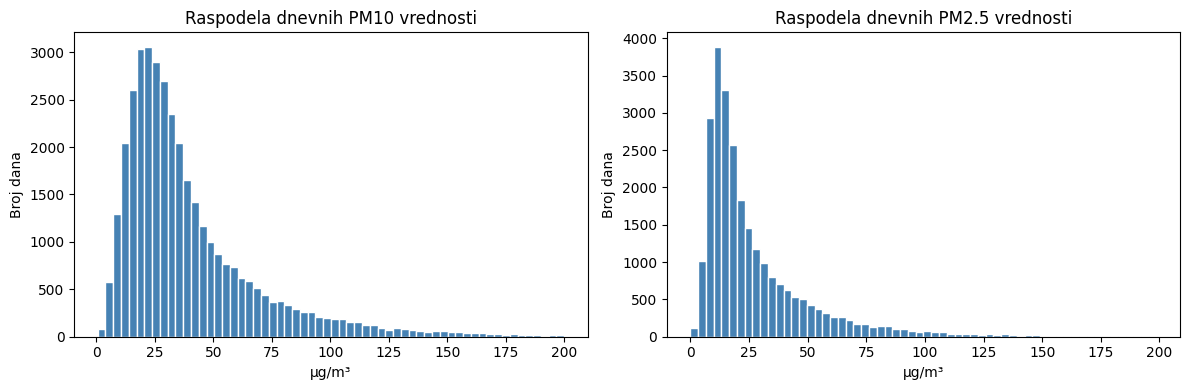

Osnovna statistika:
              count       mean        std   min    25%        50%    75%    max
Zagadjivac                                                                     
PM10        36905.0  40.895300  33.954106  0.68  20.16  30.779167  49.71  806.4
PM2.5       26051.0  27.509861  24.442580  0.00  12.00  18.700000  34.20  246.0


In [23]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, pol in zip(axes, ['PM10', 'PM2.5']):
    vrednosti = finalni_skup[finalni_skup['Zagadjivac']==pol]['Vrednost']
    ax.hist(vrednosti[vrednosti < 200], bins=60, color='steelblue', edgecolor='white')
    ax.set_title(f'Raspodela dnevnih {pol} vrednosti')
    ax.set_xlabel('µg/m³')
    ax.set_ylabel('Broj dana')
plt.tight_layout()
plt.savefig('raspodela_koncentracija.png', dpi=100)
plt.show()

print("Osnovna statistika:")
print(finalni_skup.groupby('Zagadjivac')['Vrednost'].describe())

### Sezonalnost

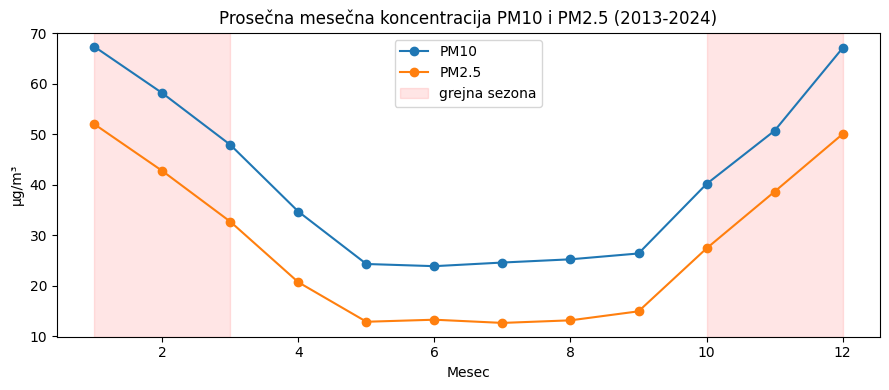

Zagadjivac,PM10,PM2.5
Mesec,,
1,67.367902,52.011322
2,58.157613,42.737390
3,47.908761,32.685192
4,34.679597,20.680839
5,24.303599,12.860326
6,23.873158,13.264187
7,24.593005,12.630317
8,25.231932,13.140935
9,26.389820,14.926313


In [24]:
finalni_skup['Datum_dt'] = pd.to_datetime(finalni_skup['Datum'])
finalni_skup['Mesec'] = finalni_skup['Datum_dt'].dt.month

mesecni_prosek = finalni_skup.groupby(['Zagadjivac', 'Mesec'])['Vrednost'].mean().unstack(level=0)

fig, ax = plt.subplots(figsize=(9, 4))
mesecni_prosek.plot(ax=ax, marker='o')
ax.set_title('Prosečna mesečna koncentracija PM10 i PM2.5 (2013-2024)')
ax.set_xlabel('Mesec')
ax.set_ylabel('µg/m³')
ax.axvspan(10, 12, alpha=0.1, color='red', label='grejna sezona')
ax.axvspan(1, 3, alpha=0.1, color='red')
ax.legend()
plt.tight_layout()
plt.savefig('sezonalnost.png', dpi=100)
plt.show()

mesecni_prosek

### Korelacije sa meteorološkim promenljivama

Zagadjivac    PM10  PM2.5  Temperatura  Padavine  Vetar_brzina  Vetar_pravac  Vlaznost  Pritisak
Zagadjivac                                                                                      
PM10          1.00   0.90        -0.39     -0.16         -0.23         -0.07      0.11     -0.09
PM2.5         0.90   1.00        -0.53     -0.11         -0.27         -0.04      0.26     -0.08
Temperatura  -0.39  -0.53         1.00     -0.04         -0.06         -0.04     -0.49     -0.05
Padavine     -0.16  -0.11        -0.04      1.00          0.20          0.09      0.40     -0.15
Vetar_brzina -0.23  -0.27        -0.06      0.20          1.00          0.08     -0.10      0.13
Vetar_pravac -0.07  -0.04        -0.04      0.09          0.08          1.00      0.06     -0.01
Vlaznost      0.11   0.26        -0.49      0.40         -0.10          0.06      1.00     -0.07
Pritisak     -0.09  -0.08        -0.05     -0.15          0.13         -0.01     -0.07      1.00


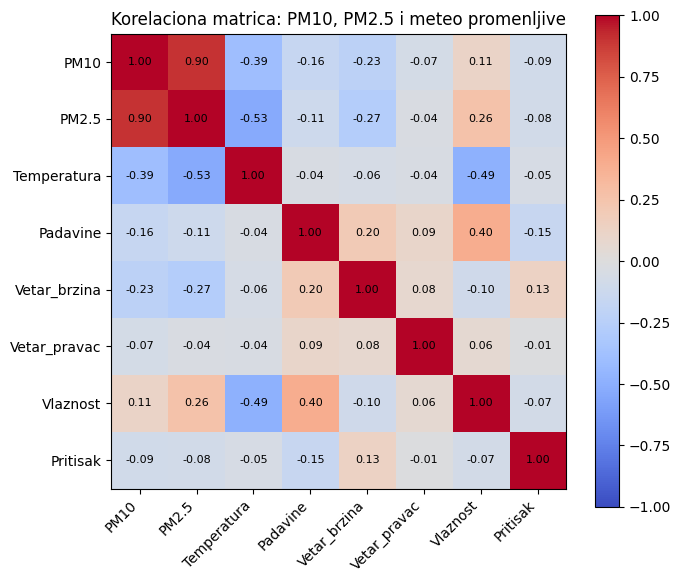

In [25]:
# Prebacujemo u "širok" format - jedan red po (datum, stanica), PM10 i PM2.5 kao odvojene kolone
pivot_pm = finalni_skup.pivot_table(
    index=['Datum','Stanica','Temperatura','Padavine','Vetar_brzina','Vetar_pravac','Vlaznost','Pritisak'],
    columns='Zagadjivac', values='Vrednost'
).reset_index()

kolone_za_korelaciju = ['PM10','PM2.5','Temperatura','Padavine','Vetar_brzina','Vetar_pravac','Vlaznost','Pritisak']
korelacije = pivot_pm[kolone_za_korelaciju].corr()

print(korelacije.round(2))

fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(korelacije, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(kolone_za_korelaciju)))
ax.set_yticks(range(len(kolone_za_korelaciju)))
ax.set_xticklabels(kolone_za_korelaciju, rotation=45, ha='right')
ax.set_yticklabels(kolone_za_korelaciju)
for i in range(len(kolone_za_korelaciju)):
    for j in range(len(kolone_za_korelaciju)):
        ax.text(j, i, f'{korelacije.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im)
plt.title('Korelaciona matrica: PM10, PM2.5 i meteo promenljive')
plt.tight_layout()
plt.savefig('korelacije.png', dpi=100)
plt.show()

## Analiza i tretman nedostajućih podataka

Trenutno tabela sadrži samo dane kada je bilo merenje. Da bismo videli gde su nedostajući podaci,
prvo pravimo pun kalendar (svaki dan, za svaku stanicu) i poredimo sa onim što stvarno imamo.

In [ ]:
# KONTROLA KVALITETA PM PODATAKA (pre analize nedostajućih dana i popunjavanja)
print('PRE kontrole: maksimum PM10 =', finalni_skup[finalni_skup['Zagadjivac']=='PM10']['Vrednost'].max().round(1),
      ' maksimum PM2.5 =', finalni_skup[finalni_skup['Zagadjivac']=='PM2.5']['Vrednost'].max().round(1))

# Obe vrednosti jednog dana i stanice stavljamo jednu pored druge
pm_par = finalni_skup.pivot_table(index=['Stanica', 'Datum'], columns='Zagadjivac', values='Vrednost').reset_index()
pm_par['Datum_dt'] = pd.to_datetime(pm_par['Datum'])
pm_par = pm_par.sort_values(['Stanica', 'Datum_dt']).reset_index(drop=True)

sumnjivo = []   # lista (Stanica, Datum, Zagadjivac, Razlog)

# 1) PM2.5 > PM10 na istoj stanici istog dana (fizički nemoguće): ne znamo koja je vrednost pogrešna, pa uklanjamo obe
maska = pm_par['PM2.5'] > pm_par['PM10']
for _, r in pm_par[maska].iterrows():
    sumnjivo += [(r['Stanica'], r['Datum'], 'PM10', 'PM2.5 > PM10'), (r['Stanica'], r['Datum'], 'PM2.5', 'PM2.5 > PM10')]

# 2) PM2.5 je tačno 0 (neispravan senzor)
for _, r in pm_par[pm_par['PM2.5'] == 0].iterrows():
    sumnjivo.append((r['Stanica'], r['Datum'], 'PM2.5', 'PM2.5 = 0'))

# 3) Izolovani skokovi: vrednost > 150 i više od 4 puta veća od JUČERAŠNJE i SUTRAŠNJE (npr. 806 µg/m³)
for stanica, g in pm_par.groupby('Stanica'):
    g = g.set_index('Datum_dt').asfreq('D')
    for pol in ['PM10', 'PM2.5']:
        v = g[pol]
        skok = (v > 150) & (v > 4 * v.shift(1)) & (v > 4 * v.shift(-1))
        for dan in v.index[skok]:
            sumnjivo.append((stanica, dan.strftime('%Y-%m-%d'), pol, 'izolovan skok'))

tabela_sumnjivih = pd.DataFrame(sumnjivo, columns=['Stanica', 'Datum', 'Zagadjivac', 'Razlog']).drop_duplicates(['Stanica', 'Datum', 'Zagadjivac'])
print('\nSumnjivih vrednosti po razlogu i zagađivaču:')
print(tabela_sumnjivih.groupby(['Razlog', 'Zagadjivac']).size())
print('\nIzolovani skokovi:')
print(tabela_sumnjivih[tabela_sumnjivih['Razlog'] == 'izolovan skok'].to_string(index=False))

# Sumnjive vrednosti tretiramo kao NEDOSTAJUĆE: brišemo te redove, pa ih dalja obrada (rupe, popunjavanje unapred) vidi kao praznine
broj_pre = len(finalni_skup)
finalni_skup = finalni_skup.merge(tabela_sumnjivih[['Stanica', 'Datum', 'Zagadjivac']].assign(sumnjivo=True),
                                  on=['Stanica', 'Datum', 'Zagadjivac'], how='left')
finalni_skup = finalni_skup[finalni_skup['sumnjivo'].isna()].drop(columns='sumnjivo').reset_index(drop=True)
print(f'\nRedova pre: {broj_pre}, posle: {len(finalni_skup)} (uklonjeno {broj_pre - len(finalni_skup)})')
print('POSLE kontrole: maksimum PM10 =', finalni_skup[finalni_skup['Zagadjivac']=='PM10']['Vrednost'].max().round(1),
      ' maksimum PM2.5 =', finalni_skup[finalni_skup['Zagadjivac']=='PM2.5']['Vrednost'].max().round(1))

PRE kontrole: maksimum PM10 = 806.4  maksimum PM2.5 = 246.0

Sumnjivih vrednosti po razlogu i zagađivaču:
Razlog         Zagadjivac
PM2.5 = 0      PM2.5           5
PM2.5 > PM10   PM10          564
               PM2.5         564
izolovan skok  PM10            4
dtype: int64

Izolovani skokovi:
       Stanica      Datum Zagadjivac        Razlog
beograd vracar 2017-12-28       PM10 izolovan skok
      kosjeric 2019-08-27       PM10 izolovan skok
       valjevo 2014-10-19       PM10 izolovan skok
       valjevo 2017-11-22       PM10 izolovan skok

Redova pre: 62956, posle: 61819 (uklonjeno 1137)
POSLE kontrole: maksimum PM10 = 552.4  maksimum PM2.5 = 246.0


In [27]:
# Za svaku stanicu i zagađivača računamo koliko dana nedostaje unutar perioda merenja (od prvog do poslednjeg dana sa podatkom)
rezultati_nedostajucih = []

for stanica in izabrane_stanice:
    for pol in ['PM10', 'PM2.5']:
        sub = finalni_skup[(finalni_skup['Stanica']==stanica) & (finalni_skup['Zagadjivac']==pol)]
        if len(sub) == 0:
            continue
        prvi_dan = pd.to_datetime(sub['Datum']).min()
        zadnji_dan = pd.to_datetime(sub['Datum']).max()
        # pun kalendar od prvog do poslednjeg dana kad je stanica bila aktivna
        pun_kalendar = pd.date_range(prvi_dan, zadnji_dan, freq='D')
        broj_moguce = len(pun_kalendar)
        broj_stvarno = len(sub)
        broj_nedostaje = broj_moguce - broj_stvarno
        procenat_nedostaje = 100 * broj_nedostaje / broj_moguce

        rezultati_nedostajucih.append({
            'Stanica': stanica, 'Zagadjivac': pol,
            'Prvi_dan': prvi_dan.date(), 'Zadnji_dan': zadnji_dan.date(),
            'Moguce_dana': broj_moguce, 'Nedostaje_dana': broj_nedostaje,
            'Procenat_nedostaje': round(procenat_nedostaje, 1)
        })

tabela_nedostajucih = pd.DataFrame(rezultati_nedostajucih).sort_values('Procenat_nedostaje', ascending=False)
tabela_nedostajucih

,Stanica,Zagadjivac,Prvi_dan,Zadnji_dan,Moguce_dana,Nedostaje_dana,Procenat_nedostaje
18,popovac,PM10,2013-01-11,2024-12-31,4373,2017,46.1
3,beograd novi beograd,PM2.5,2016-01-01,2024-12-31,3288,1337,40.7
20,smederevo centar,PM10,2013-01-01,2024-12-31,4383,1739,39.7
11,nis izjz nis,PM2.5,2017-01-01,2024-12-31,2922,1160,39.7
8,kosjeric,PM10,2013-01-01,2024-12-19,4371,1431,32.7
4,beograd stari grad,PM10,2013-01-01,2024-12-31,4383,1349,30.8
5,beograd stari grad,PM2.5,2016-01-04,2024-12-31,3285,984,30.0
10,nis izjz nis,PM10,2013-01-01,2024-12-31,4383,1316,30.0
2,beograd novi beograd,PM10,2013-01-01,2024-12-31,4383,1310,29.9
0,beograd mostar,PM10,2013-01-01,2024-12-31,4383,1304,29.8


In [28]:
# Za jednu stanicu i zagađivača nalazimo "rupe" (nizove uzastopnih dana bez podatka) i merimo koliko svaka traje, da odlučimo koje rupe vredi popunjavati
def analiziraj_duzinu_prekida(stanica, pol):
    sub = finalni_skup[(finalni_skup['Stanica']==stanica) & (finalni_skup['Zagadjivac']==pol)].copy()
    if len(sub) == 0:
        return None
    sub['Datum_dt'] = pd.to_datetime(sub['Datum'])
    prvi, zadnji = sub['Datum_dt'].min(), sub['Datum_dt'].max()
    pun_kalendar = pd.DataFrame({'Datum_dt': pd.date_range(prvi, zadnji, freq='D')})
    spojeno = pun_kalendar.merge(sub[['Datum_dt','Vrednost']], on='Datum_dt', how='left')

    # označimo grupe uzastopnih nedostajućih dana
    spojeno['nedostaje'] = spojeno['Vrednost'].isna()
    spojeno['grupa'] = (spojeno['nedostaje'] != spojeno['nedostaje'].shift()).cumsum()
    prekidi = spojeno[spojeno['nedostaje']].groupby('grupa').size()

    return prekidi

# Primer na najgorem slučaju - Popovac PM10
prekidi = analiziraj_duzinu_prekida('popovac', 'PM10')
print("Popovac PM10 - distribucija duzina prekida:")
print(f"Broj odvojenih 'rupa': {len(prekidi)}")
print(f"Najkraca rupa: {prekidi.min()} dana, Najduza rupa: {prekidi.max()} dana")
print(f"Medijana duzine rupe: {prekidi.median()} dana")
print()
print("Raspodela (rupe u danima i koliko ih ima):")
print(prekidi.value_counts().sort_index().head(20))

Popovac PM10 - distribucija duzina prekida:
Broj odvojenih 'rupa': 30
Najkraca rupa: 1 dana, Najduza rupa: 1832 dana
Medijana duzine rupe: 2.0 dana

Raspodela (rupe u danima i koliko ih ima):
1       11
2        6
3        3
4        1
5        1
6        1
8        1
9        1
10       2
50       1
51       1
1832     1
Name: count, dtype: int64


In [29]:
PRAG_KRATKE_RUPE = 7  # dana - do ovoliko dana popunjavamo unapred; preko toga, isključujemo period.

def popuni_i_ocisti(stanica, pol, prag=PRAG_KRATKE_RUPE):
    sub = finalni_skup[(finalni_skup['Stanica']==stanica) & (finalni_skup['Zagadjivac']==pol)].copy()
    if len(sub) == 0:
        return None
    sub['Datum_dt'] = pd.to_datetime(sub['Datum'])
    prvi, zadnji = sub['Datum_dt'].min(), sub['Datum_dt'].max()
    pun_kalendar = pd.DataFrame({'Datum_dt': pd.date_range(prvi, zadnji, freq='D')})
    spojeno = pun_kalendar.merge(sub[['Datum_dt','Vrednost']], on='Datum_dt', how='left')

    spojeno['nedostaje'] = spojeno['Vrednost'].isna()
    spojeno['grupa'] = (spojeno['nedostaje'] != spojeno['nedostaje'].shift()).cumsum()
    duzina_grupe = spojeno.groupby('grupa')['nedostaje'].transform('size')

    # popunjavamo samo unapred (poslednja poznata vrednost, najviše 'prag' dana): ne koristimo buduće vrednosti
    # (redovi iz dugih rupa se posle uklanjaju, pa se ne popunjavaju)
    spojeno['Vrednost_popunjeno'] = spojeno['Vrednost'].ffill(limit=prag)
    spojeno['bila_duga_rupa'] = spojeno['nedostaje'] & (duzina_grupe > prag)
    spojeno['Izmereno'] = ~spojeno['nedostaje']
    # isključujemo redove koji su bili deo nedostajućih podataka (ne popunjavamo ih)
    finalno = spojeno[~spojeno['bila_duga_rupa']].copy()
    finalno['Stanica'] = stanica
    finalno['Zagadjivac'] = pol
    return finalno[['Datum_dt','Stanica','Zagadjivac','Vrednost_popunjeno','Izmereno']]

# Test na Popovcu
test = popuni_i_ocisti('popovac', 'PM10')
print(f"Redova posle ciscenja: {len(test)} (od originalnih {len(finalni_skup[(finalni_skup['Stanica']=='popovac') & (finalni_skup['Zagadjivac']=='PM10')])} + popunjenih kratkih rupa (unapred))")
test.head()

Redova posle ciscenja: 2403 (od originalnih 2356 + popunjenih kratkih rupa (unapred))


,Datum_dt,Stanica,Zagadjivac,Vrednost_popunjeno,Izmereno
0,2013-01-11,popovac,PM10,40.66,True
1,2013-01-12,popovac,PM10,23.61,True
2,2013-01-13,popovac,PM10,40.47,True
3,2013-01-14,popovac,PM10,50.54,True
4,2013-01-15,popovac,PM10,31.01,True


In [30]:
svi_ocisceni = []
for stanica in izabrane_stanice:
    for pol in ['PM10', 'PM2.5']:
        rezultat = popuni_i_ocisti(stanica, pol)
        if rezultat is not None:
            svi_ocisceni.append(rezultat)

pm_ocisceno = pd.concat(svi_ocisceni, ignore_index=True)
pm_ocisceno['Datum'] = pd.to_datetime(pm_ocisceno['Datum_dt'])
pm_ocisceno['Godina'] = pm_ocisceno['Datum'].dt.year
pm_ocisceno = pm_ocisceno.rename(columns={'Vrednost_popunjeno': 'Vrednost'})
pm_ocisceno = pm_ocisceno[['Datum','Stanica','Zagadjivac','Vrednost','Godina','Izmereno']]

print(f"Redova PRE ciscenja (finalni_skup): {len(finalni_skup)}")
print(f"Redova POSLE ciscenja (ukljucujuci popunjene): {len(pm_ocisceno)}")
print(f"Razlika (negativna zato što su dodati popunjeni dani kratkih rupa): {len(finalni_skup) - len(pm_ocisceno)}")

# Ponovo spajamo sa meteo podacima (oba Datum-a su sada pravi datumi)
meteo['Datum'] = pd.to_datetime(meteo['Datum'])
finalni_skup_ocisceno = pm_ocisceno.merge(meteo, on=['Datum','Stanica'], how='left')
print()
print("Redova bez meteo podataka (ocekujemo 0):", finalni_skup_ocisceno['Temperatura'].isna().sum())

finalni_skup_ocisceno.to_csv('finalni_skup_ocisceno.csv', index=False)
print()
print("Sacuvano:", len(finalni_skup_ocisceno), "redova u finalni_skup_ocisceno.csv")
finalni_skup_ocisceno['Izmereno'].value_counts()

Redova PRE ciscenja (finalni_skup): 61819
Redova POSLE ciscenja (ukljucujuci popunjene): 63560
Razlika (negativna zato što su dodati popunjeni dani kratkih rupa): -1741

Redova bez meteo podataka (ocekujemo 0): 0

Sacuvano: 63560 redova u finalni_skup_ocisceno.csv


Izmereno
True     61819
False     1741
Name: count, dtype: int64

## Tačka 3: Inženjering atributa

In [31]:
finalni_skup_ocisceno = pd.read_csv('finalni_skup_ocisceno.csv')
finalni_skup_ocisceno['Datum'] = pd.to_datetime(finalni_skup_ocisceno['Datum'])
print(finalni_skup_ocisceno.shape)
finalni_skup_ocisceno.head()

(63560, 12)


,Datum,Stanica,Zagadjivac,Vrednost,Godina,Izmereno,Temperatura,Padavine,Vetar_brzina,Vetar_pravac,Vlaznost,Pritisak
0,2013-01-01,beograd mostar,PM10,105.38,2013,True,0.6,0.0,15.0,141,83,1009.9
1,2013-01-02,beograd mostar,PM10,128.23,2013,True,1.2,0.0,9.7,148,84,1012.1
2,2013-01-03,beograd mostar,PM10,88.48,2013,True,1.9,0.0,8.4,249,91,1022.4
3,2013-01-04,beograd mostar,PM10,49.19,2013,True,6.6,0.2,25.0,288,79,1015.7
4,2013-01-05,beograd mostar,PM10,18.08,2013,True,6.4,9.3,23.7,308,88,1005.9


In [32]:
# Pravimo "široku" tabelu (PM10 i PM2.5 u istom redu), dopunjujemo je do punog dnevnog kalendara po stanici i spajamo sa meteo podacima
pm_sirok = finalni_skup_ocisceno.pivot_table(
    index=['Stanica','Datum'], columns='Zagadjivac', values='Vrednost').reset_index()
pm_sirok.columns.name = None

# zastavica: da li je vrednost stvarno izmerena (True) ili popunjena unapred (False)
izm = finalni_skup_ocisceno.pivot_table(
    index=['Stanica','Datum'], columns='Zagadjivac', values='Izmereno', aggfunc='min').reset_index()
izm.columns.name = None
izm = izm.rename(columns={'PM10':'PM10_izmereno', 'PM2.5':'PM2.5_izmereno'})
pm_sirok = pm_sirok.merge(izm, on=['Stanica','Datum'])

pm_sirok = (pm_sirok.groupby('Stanica', group_keys=False)
            .apply(lambda g: g.set_index('Datum').asfreq('D').assign(Stanica=g.name))
            .reset_index())

# dani koje smo dodali kalendarom nisu izmereni
for c in ['PM10_izmereno', 'PM2.5_izmereno']:
    pm_sirok[c] = pm_sirok[c].fillna(False).astype(bool)

meteo['Datum'] = pd.to_datetime(meteo['Datum'])
sirok_format = pm_sirok.merge(meteo, on=['Datum','Stanica'], how='left')
sirok_format = sirok_format.sort_values(['Stanica','Datum']).reset_index(drop=True)

razlike = sirok_format.groupby('Stanica')['Datum'].diff().dt.days.dropna()
print('Oblik:', sirok_format.shape)
print('Najveći razmak (mora biti 1):', razlike.max())
print('PM10 izmereno:', sirok_format['PM10_izmereno'].sum(), '| PM10 ukupno:', sirok_format['PM10'].notna().sum())

Oblik: (49832, 12)
Najveći razmak (mora biti 1): 1.0
PM10 izmereno: 36337 | PM10 ukupno: 37257


In [33]:
# Kalendarski atributi: mesec, dan u nedelji, grejna sezona i ciklično kodiranje meseca (sin/cos)
sirok_format['Datum'] = pd.to_datetime(sirok_format['Datum'])
sirok_format['Mesec'] = sirok_format['Datum'].dt.month
sirok_format['Dan_u_nedelji'] = sirok_format['Datum'].dt.dayofweek  # 0=ponedeljak, 6=nedelja
sirok_format['Grejna_sezona'] = sirok_format['Mesec'].isin([10,11,12,1,2,3]).astype(int)

# Ciklično kodiranje meseca (sin/cos) - da model "razume" da je decembar blizu januara
sirok_format['Mesec_sin'] = np.sin(2 * np.pi * sirok_format['Mesec'] / 12)
sirok_format['Mesec_cos'] = np.cos(2 * np.pi * sirok_format['Mesec'] / 12)

sirok_format[['Datum','Mesec','Dan_u_nedelji','Grejna_sezona','Mesec_sin','Mesec_cos']].head(10)

,Datum,Mesec,Dan_u_nedelji,Grejna_sezona,Mesec_sin,Mesec_cos
0,2013-01-01,1,1,1,0.5,0.866025
1,2013-01-02,1,2,1,0.5,0.866025
2,2013-01-03,1,3,1,0.5,0.866025
3,2013-01-04,1,4,1,0.5,0.866025
4,2013-01-05,1,5,1,0.5,0.866025
5,2013-01-06,1,6,1,0.5,0.866025
6,2013-01-07,1,0,1,0.5,0.866025
7,2013-01-08,1,1,1,0.5,0.866025
8,2013-01-09,1,2,1,0.5,0.866025
9,2013-01-10,1,3,1,0.5,0.866025


In [34]:
# Lagovi PM (1, 3 i 7 dana unazad) i klizni proseci (3 i 7 dana, uključujući danas), posebno za svaku stanicu
sirok_format = sirok_format.sort_values(['Stanica','Datum']).reset_index(drop=True)
g = sirok_format.groupby('Stanica')

# lagovi: shift(k) sada znači "pre k dana", jer je kalendar pun
for lag in [1, 3, 7]:
    sirok_format[f'PM10_lag{lag}']  = g['PM10'].shift(lag)
    sirok_format[f'PM2.5_lag{lag}'] = g['PM2.5'].shift(lag)

# pokretni proseci poslednja 3 i 7 dana, uključujući danas (nema više shift(1))
for p in ['PM10', 'PM2.5']:
    for n in [3, 7]:
        sirok_format[f'{p}_rolling{n}'] = g[p].transform(lambda x: x.rolling(n).mean())

sirok_format[['Stanica','Datum','PM10','PM10_lag1','PM10_lag3','PM10_lag7','PM10_rolling3','PM10_rolling7']].head(12)

,Stanica,Datum,PM10,PM10_lag1,PM10_lag3,PM10_lag7,PM10_rolling3,PM10_rolling7
0,beograd mostar,2013-01-01,105.38,NaN,NaN,NaN,NaN,NaN
1,beograd mostar,2013-01-02,128.23,105.38,NaN,NaN,NaN,NaN
2,beograd mostar,2013-01-03,88.48,128.23,NaN,NaN,107.363333,NaN
3,beograd mostar,2013-01-04,49.19,88.48,105.38,NaN,88.633333,NaN
4,beograd mostar,2013-01-05,18.08,49.19,128.23,NaN,51.916667,NaN
5,beograd mostar,2013-01-06,29.18,18.08,88.48,NaN,32.150000,NaN
6,beograd mostar,2013-01-07,15.44,29.18,49.19,NaN,20.900000,61.997143
7,beograd mostar,2013-01-08,47.00,15.44,18.08,105.38,30.540000,53.657143
8,beograd mostar,2013-01-09,88.50,47.00,29.18,128.23,50.313333,47.981429
9,beograd mostar,2013-01-10,127.94,88.50,15.44,88.48,87.813333,53.618571


In [35]:
g = sirok_format.groupby('Stanica')
for kolona in ['Temperatura','Vetar_brzina','Vlaznost','Pritisak']:
    sirok_format[f'{kolona}_lag1'] = g[kolona].shift(1)

sirok_format[['Stanica','Datum','Temperatura','Temperatura_lag1','PM2.5','PM2.5_lag1','PM2.5_rolling3']].head(10)

,Stanica,Datum,Temperatura,Temperatura_lag1,PM2.5,PM2.5_lag1,PM2.5_rolling3
0,beograd mostar,2013-01-01,0.6,NaN,NaN,NaN,NaN
1,beograd mostar,2013-01-02,1.2,0.6,NaN,NaN,NaN
2,beograd mostar,2013-01-03,1.9,1.2,NaN,NaN,NaN
3,beograd mostar,2013-01-04,6.6,1.9,NaN,NaN,NaN
4,beograd mostar,2013-01-05,6.4,6.6,NaN,NaN,NaN
5,beograd mostar,2013-01-06,2.1,6.4,NaN,NaN,NaN
6,beograd mostar,2013-01-07,0.2,2.1,NaN,NaN,NaN
7,beograd mostar,2013-01-08,-2.3,0.2,NaN,NaN,NaN
8,beograd mostar,2013-01-09,-1.2,-2.3,NaN,NaN,NaN
9,beograd mostar,2013-01-10,1.0,-1.2,NaN,NaN,NaN


In [36]:
# Spajamo dnevni BLH (prosek i maksimum) po stanici i datumu; proveravamo da broj redova ostane isti i gde BLH nedostaje (2024)
blh_dnevno = pd.read_csv('blh_dnevno.csv', parse_dates=['Datum'])
sirok_format['Datum'] = pd.to_datetime(sirok_format['Datum'])

broj_pre = len(sirok_format)
sirok_format = sirok_format.merge(blh_dnevno, on=['Stanica', 'Datum'], how='left')
print('Redova pre i posle spajanja:', broj_pre, len(sirok_format), '(mora biti isto)')

print('\nUdeo dana bez BLH po godinama:')
print(sirok_format.groupby(sirok_format['Datum'].dt.year)['BLH_prosek'].apply(lambda s: s.isna().mean()).round(2))

Redova pre i posle spajanja: 49832 49832 (mora biti isto)

Udeo dana bez BLH po godinama:
Datum
2013    0.00
2014    0.00
2015    0.00
2016    0.00
2017    0.00
2018    0.00
2019    0.00
2020    0.00
2021    0.00
2022    0.00
2023    0.00
2024    0.49
Name: BLH_prosek, dtype: float64


In [37]:
# ciljevi za 1, 3 i 7 dana unapred (cilj_h1 je vrednost PM10 od sledećeg dana, cilj_h3 od trećeg dana, isto važi i za 7)
# cilj uzimamo samo iz STVARNO izmerenih vrednosti (popunjeni dani nikad nisu cilj)
sirok_format['PM10_mereno'] = sirok_format['PM10'].where(sirok_format['PM10_izmereno'])
g = sirok_format.groupby('Stanica')   # ponovo, jer smo dodali kolonu

for h in [1, 3, 7]:
    sirok_format[f'cilj_h{h}'] = g['PM10_mereno'].shift(-h)
    # ciljni dan je izmeren ako cilj postoji (NaN znači da nije izmeren)
    sirok_format[f'cilj_h{h}_izmereno'] = sirok_format[f'cilj_h{h}'].notna()

print('Test period (od 2023), ciljni dani koji nisu izmereni:')
for h in [1, 3, 7]:
    t = sirok_format[(sirok_format['Datum'] >= '2023-01-01') & sirok_format[f'cilj_h{h}'].notna()]
    print(f'  h={h}: {(~t[f"cilj_h{h}_izmereno"]).sum()} od {len(t)}')

sirok_format[sirok_format['Stanica']=='beograd mostar'][['Datum','PM10','cilj_h1','cilj_h1_izmereno','cilj_h7']].head(5)

Test period (od 2023), ciljni dani koji nisu izmereni:
  h=1: 0 od 9204
  h=3: 0 od 9178
  h=7: 0 od 9126


,Datum,PM10,cilj_h1,cilj_h1_izmereno,cilj_h7
0,2013-01-01,105.38,128.23,True,47.00
1,2013-01-02,128.23,88.48,True,88.50
2,2013-01-03,88.48,49.19,True,127.94
3,2013-01-04,49.19,18.08,True,81.34
4,2013-01-05,18.08,29.18,True,47.01


In [38]:
# Ciljevi se prave sa shift(-h), pa red iz poslednjih dana jednog perioda može imati cilj u sledećem periodu.
# Takvim redovima cilj postavljamo na NaN (trening cilj ne sme biti u validaciji, a validacioni cilj ne sme biti u testu)
GRANICE = np.array(['2022-01-01', '2023-01-01'], dtype='datetime64[ns]')   # početak validacije i početak testa

def prekini_curenje(kolone_ciljeva):
    for h in [1, 3, 7]:
        period_reda = np.searchsorted(GRANICE, sirok_format['Datum'].values, side='right')
        period_cilja = np.searchsorted(GRANICE, (sirok_format['Datum'] + pd.Timedelta(days=h)).values, side='right')
        prelazi = period_reda != period_cilja
        for kolona in kolone_ciljeva(h):
            sirok_format.loc[prelazi, kolona] = np.nan
        sirok_format.loc[prelazi, f'{kolone_ciljeva(h)[0]}_izmereno'] = False

prekini_curenje(lambda h: [f'cilj_h{h}'])

for h in [1, 3, 7]:
    d = sirok_format.dropna(subset=[f'cilj_h{h}'])
    print(f'h={h}: kraj cilja treninga =', (d[d['Datum'] < '2022-01-01']['Datum'].max() + pd.Timedelta(days=h)).date(),
          '| kraj cilja validacije =', (d[d['Datum'] < '2023-01-01']['Datum'].max() + pd.Timedelta(days=h)).date())

h=1: kraj cilja treninga = 2021-12-31 | kraj cilja validacije = 2022-12-31
h=3: kraj cilja treninga = 2021-12-31 | kraj cilja validacije = 2022-12-31
h=7: kraj cilja treninga = 2021-12-31 | kraj cilja validacije = 2022-12-31


### Analiza značajnosti atributa

In [39]:
atributi_za_analizu = ['PM10','PM2.5','PM10_lag1','PM10_lag3','PM10_lag7','PM10_rolling3','PM10_rolling7',
                       'Temperatura','Temperatura_lag1','Vetar_brzina','Vlaznost','Pritisak',
                       'Mesec_sin','Mesec_cos','Grejna_sezona']

# analiza samo na TRENING skupu (do kraja 2021), da validacija i test ostanu "nevidljivi"
trening_analiza = sirok_format[sirok_format['Datum'] < '2022-01-01']

korelacije_cilj = trening_analiza[['cilj_h1'] + atributi_za_analizu].corr()['cilj_h1'].drop('cilj_h1')
korelacije_cilj = korelacije_cilj.sort_values(key=abs, ascending=False)

print("Korelacija svakog atributa sa PM10 SUTRA (cilj_h1), samo trening skup:")
print(korelacije_cilj.round(3))

Korelacija svakog atributa sa PM10 SUTRA (cilj_h1), samo trening skup:
PM10                0.785
PM10_rolling3       0.731
PM2.5               0.730
PM10_rolling7       0.710
PM10_lag1           0.637
PM10_lag3           0.544
PM10_lag7           0.522
Temperatura_lag1   -0.469
Temperatura        -0.449
Mesec_cos           0.437
Grejna_sezona       0.433
Vetar_brzina       -0.208
Mesec_sin           0.194
Vlaznost            0.158
Pritisak           -0.052
Name: cilj_h1, dtype: float64


In [40]:
# Random Forest procenjuje koji atributi najviše doprinose predviđanju PM10 sutra (samo na trening skupu, da test ostane nevidljiv)
from sklearn.ensemble import RandomForestRegressor

podaci_za_fi = trening_analiza.dropna(subset=['cilj_h1'] + atributi_za_analizu)
print('Redova za analizu (samo trening):', len(podaci_za_fi))

X = podaci_za_fi[atributi_za_analizu]
y = podaci_za_fi['cilj_h1']

rf = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
rf.fit(X, y)

feature_importance = pd.Series(rf.feature_importances_, index=atributi_za_analizu).sort_values(ascending=False)
print("Feature importance (Random Forest) za PM10 sutra, samo trening skup:")
print(feature_importance.round(3))

Redova za analizu (samo trening): 11110
Feature importance (Random Forest) za PM10 sutra, samo trening skup:
PM10                0.744
Temperatura         0.055
Vetar_brzina        0.032
PM2.5               0.026
PM10_lag7           0.026
PM10_rolling7       0.026
PM10_rolling3       0.017
PM10_lag3           0.016
Temperatura_lag1    0.015
PM10_lag1           0.013
Pritisak            0.013
Vlaznost            0.013
Mesec_cos           0.002
Mesec_sin           0.002
Grejna_sezona       0.000
dtype: float64


## Tačka 4A: Modeli za PM 10 

Hronološka podela podataka:
- Trening: do kraja 2021.
- Validacija: 2022.
- Test: 2023-2024.

In [41]:
# Pravimo skup za modelovanje (samo redovi sa kompletnim PM10 atributima) i delimo ga hronološki: trening do 2021, validacija 2022, test 2023–2024
# Uklanjamo redove gde nemamo PM10_lag7 (najduži lag) - potreban nam je kompletan set atributa
sirok_format['Vetar_sin'] = np.sin(np.deg2rad(sirok_format['Vetar_pravac']))
sirok_format['Vetar_cos'] = np.cos(np.deg2rad(sirok_format['Vetar_pravac']))
podaci_model = sirok_format.dropna(subset=['PM10','PM10_lag1','PM10_lag3','PM10_lag7',
                                             'PM10_rolling3','PM10_rolling7']).copy()

trening = podaci_model[podaci_model['Datum'] < '2022-01-01']
validacija = podaci_model[(podaci_model['Datum'] >= '2022-01-01') & (podaci_model['Datum'] < '2023-01-01')]
test = podaci_model[podaci_model['Datum'] >= '2023-01-01']

print(f'Trening:    {len(trening)} redova  ({trening["Datum"].min()} - {trening["Datum"].max()})')
print(f'Validacija: {len(validacija)} redova  ({validacija["Datum"].min()} - {validacija["Datum"].max()})')
print(f'Test:       {len(test)} redova  ({test["Datum"].min()} - {test["Datum"].max()})')

Trening:    22901 redova  (2013-01-08 00:00:00 - 2021-12-31 00:00:00)
Validacija: 4338 redova  (2022-01-01 00:00:00 - 2022-12-31 00:00:00)
Test:       9319 redova  (2023-01-01 00:00:00 - 2024-12-31 00:00:00)


### Baseline model 1: Naivna prognoza

In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluiraj(y_true, y_pred, naziv):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f'{naziv:30s}  MAE={mae:6.2f}   RMSE={rmse:6.2f}   R2={r2:.3f}')
    return {'model': naziv, 'MAE': mae, 'RMSE': rmse, 'R2': r2}

rezultati = []

# Naivna prognoza: PM10 za h dana unapred = današnji PM10
# Greška se računa samo na danima čija je ciljna vrednost STVARNO izmerena
for h in [1, 3, 7]:
    test_h = test.dropna(subset=[f'cilj_h{h}'])
    test_h = test_h[test_h[f'cilj_h{h}_izmereno']]
    rez = evaluiraj(test_h[f'cilj_h{h}'], test_h['PM10'], f'Naivna (horizont={h} dan)')
    rez['horizont'] = h
    rezultati.append(rez)

Naivna (horizont=1 dan)         MAE= 11.41   RMSE= 18.62   R2=0.537
Naivna (horizont=3 dan)         MAE= 17.37   RMSE= 27.07   R2=0.009
Naivna (horizont=7 dan)         MAE= 17.86   RMSE= 27.19   R2=-0.008


### Baseline model 2: Sezonski naivni model

In [43]:
# Sezonski naivni: prognoza za ciljni dan (t+h) = PM10 istog dana pre 365 dana = PM10(t+h-365)
# Shift računamo na sirok_format (pun kalendar), NE na podaci_model (izbacili smo redove)
for h in [1, 3, 7]:
    sirok_format[f'PM10_sez_h{h}'] = sirok_format.groupby('Stanica')['PM10'].shift(365 - h)
    podaci_model[f'PM10_sez_h{h}'] = sirok_format.loc[podaci_model.index, f'PM10_sez_h{h}']

test = podaci_model[podaci_model['Datum'] >= '2023-01-01']

for h in [1, 3, 7]:
    t = test.dropna(subset=[f'cilj_h{h}', f'PM10_sez_h{h}'])
    t = t[t[f'cilj_h{h}_izmereno']]      # samo izmereni ciljni dani
    rez = evaluiraj(t[f'cilj_h{h}'], t[f'PM10_sez_h{h}'], f'Sezonski naivni (horizont={h} dan)')
    rez['horizont'] = h
    rezultati.append(rez)

Sezonski naivni (horizont=1 dan)  MAE= 20.29   RMSE= 29.78   R2=-0.158
Sezonski naivni (horizont=3 dan)  MAE= 20.27   RMSE= 29.77   R2=-0.169
Sezonski naivni (horizont=7 dan)  MAE= 20.22   RMSE= 29.75   R2=-0.176


### Baseline model 3: ARIMA (klasičan statistički model)

Treniran na jednoj reprezentativnoj stanici (Beograd Mostar), pošto je ARIMA
univarijatni model - ne kombinuje podatke iz više stanica poput ML modela.

In [44]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
warnings.filterwarnings('ignore')

stanica_arima = 'beograd mostar'
# pun kalendar iz sirok_format; rupe ostaju NaN (SARIMAX ih rešava sam, bez veštačkog popunjavanja)
serija = sirok_format[sirok_format['Stanica']==stanica_arima].set_index('Datum')['PM10'].asfreq('D')
izmereno_serija = sirok_format[sirok_format['Stanica']==stanica_arima].set_index('Datum')['PM10_izmereno'].asfreq('D')
izmereno_test = izmereno_serija[izmereno_serija.index >= '2023-01-01']
serija_trening = serija[serija.index < '2022-01-01']
serija_test = serija[serija.index >= '2023-01-01']

model = SARIMAX(serija_trening, order=(1,1,1), enforce_stationarity=False, enforce_invertibility=False)
rez_sarima = model.fit(disp=False)
print(rez_sarima.summary())

                               SARIMAX Results                                
Dep. Variable:                   PM10   No. Observations:                 3287
Model:               SARIMAX(1, 1, 1)   Log Likelihood               -8393.674
Date:                Tue, 17 Nov 2026   AIC                          16793.349
Time:                        14:47:40   BIC                          16811.639
Sample:                    01-01-2013   HQIC                         16799.898
                         - 12-31-2021                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5877      0.014     42.664      0.000       0.561       0.615
ma.L1         -1.0576      0.007   -154.703      0.000      -1.071      -1.044
sigma2       162.9289      3.012     54.092      0.0

In [45]:
# Prvo "nahranimo" model celom 2022. godinom (validacioni period)
serija_validacija = serija[(serija.index >= '2022-01-01') & (serija.index < '2023-01-01')].asfreq('D')
trenutni_model_pocetni = rez_sarima.append(serija_validacija, refit=False)

print("Model sad 'zna' podatke do:", trenutni_model_pocetni.data.dates[-1])

Model sad 'zna' podatke do: 2022-12-31 00:00:00


#### Walk-forward evaluacija ARIMA modela (horizonti 1, 3, 7 dana)

In [46]:
#Svakog dana test perioda model vidi stvarnu vrednost, prognozira narednih 7 dana, pa poredimo prognoze za 1, 3 i 7 dana sa stvarnim izmerenim vrednostima
horizonti = [1, 3, 7]
predikcije = {h: [] for h in horizonti}
stvarne_vrednosti = {h: [] for h in horizonti}
izmerene = {h: [] for h in horizonti}

trenutni_model = trenutni_model_pocetni
max_h = max(horizonti)

for i in range(len(serija_test) - max_h):
    # model "vidi" danas (dan i), pa prognozira narednih 7 dana
    trenutni_model = trenutni_model.append(serija_test.iloc[[i]], refit=False)
    prognoza = trenutni_model.get_forecast(steps=max_h).predicted_mean
    for h in horizonti:
        predikcije[h].append(prognoza.iloc[h-1])
        stvarne_vrednosti[h].append(serija_test.iloc[i+h])
        izmerene[h].append(izmereno_test.iloc[i+h])

print("Završeno! Evaluacija po horizontu (samo izmereni dani):")
for h in horizonti:
    y = np.array(stvarne_vrednosti[h]); p = np.array(predikcije[h])
    ok = ~np.isnan(y) & np.array(izmerene[h], dtype=bool)
    rez = evaluiraj(y[ok], p[ok], f'ARIMA(1,1,1) (horizont={h} dan)')
    rez['horizont'] = h
    rezultati.append(rez)

Završeno! Evaluacija po horizontu (samo izmereni dani):
ARIMA(1,1,1) (horizont=1 dan)   MAE=  8.18   RMSE= 12.46   R2=0.653
ARIMA(1,1,1) (horizont=3 dan)   MAE= 12.02   RMSE= 17.67   R2=0.293
ARIMA(1,1,1) (horizont=7 dan)   MAE= 13.33   RMSE= 19.01   R2=0.226


ADF test: p = 0.0009  -> stacionarna (d=0)
   p  q      AIC
0  3  1  16807.2
1  2  2  16808.3
2  2  3  16809.7
3  3  3  16811.7
4  1  3  16820.4

Izabran red po AIC: ARIMA(3,0,1)

Ljung-Box p-vrednosti (lag 7 i 14):
  ARIMA(1,1,1): [0.0001 0.001 ]
  ARIMA(3,0,1): [0.0322 0.1312]


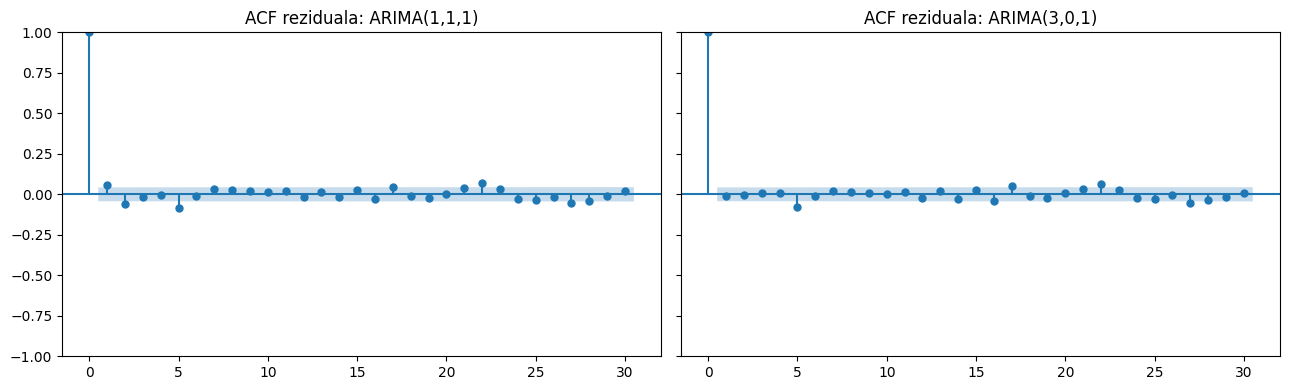

In [47]:
# Izbor reda ARIMA modela: ADF test stacionarnosti, pretraga (p,q) po AIC kriterijumu, Ljung-Box test i ACF reziduala (poređenje sa ARIMA(1,1,1))
import itertools
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

# 1) Da li je serija stacionarna? (ADF test; p < 0.05 znači da JESTE, pa diferenciranje d=1 ne treba)
adf_p = adfuller(serija_trening.dropna())[1]
print(f'ADF test: p = {adf_p:.4f}  ->', 'stacionarna (d=0)' if adf_p < 0.05 else 'nije stacionarna (d=1)')

# 2) Biramo red (p, q) po AIC kriterijumu (manji AIC = bolji model), sa konstantom jer je d=0
rezultati_aic = []
for p, q in itertools.product(range(0, 4), range(0, 4)):
    model_aic = SARIMAX(serija_trening, order=(p, 0, q), trend='c').fit(disp=False)
    rezultati_aic.append({'p': p, 'q': q, 'AIC': model_aic.aic})
tabela_aic = pd.DataFrame(rezultati_aic).sort_values('AIC').reset_index(drop=True)
print(tabela_aic.head(5).round(1))

najbolji_p, najbolji_q = int(tabela_aic.loc[0, 'p']), int(tabela_aic.loc[0, 'q'])
print(f'\nIzabran red po AIC: ARIMA({najbolji_p},0,{najbolji_q})')

rez_arima_aic = SARIMAX(serija_trening, order=(najbolji_p, 0, najbolji_q), trend='c').fit(disp=False)

# 3) Ljung-Box test reziduala: p > 0.05 znači da u reziduima NEMA autokorelacije (model je adekvatan)
rezidui_stari = rez_sarima.resid.iloc[2:].dropna()
rezidui_novi = rez_arima_aic.resid.iloc[1:].dropna()
print('\nLjung-Box p-vrednosti (lag 7 i 14):')
print('  ARIMA(1,1,1):', acorr_ljungbox(rezidui_stari, lags=[7, 14])['lb_pvalue'].round(4).values)
print(f'  ARIMA({najbolji_p},0,{najbolji_q}):', acorr_ljungbox(rezidui_novi, lags=[7, 14])['lb_pvalue'].round(4).values)

# 4) ACF reziduala
fig, ose = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
plot_acf(rezidui_stari, lags=30, ax=ose[0], title='ACF reziduala: ARIMA(1,1,1)')
plot_acf(rezidui_novi, lags=30, ax=ose[1], title=f'ACF reziduala: ARIMA({najbolji_p},0,{najbolji_q})')
plt.tight_layout()
plt.savefig('acf_reziduala.png', dpi=150)
plt.show()

In [48]:
# ARIMA(3,0,1) i ARIMAX(3,0,1) (ARIMA + meteo kao egzogene promenljive) sa walk-forward evaluacijom za PM10, Beograd Mostar
# Obezbeđujemo sin/cos pravca vetra (ako ih ranije ćelije nisu napravile)
sirok_format['Vetar_sin'] = np.sin(np.deg2rad(sirok_format['Vetar_pravac']))
sirok_format['Vetar_cos'] = np.cos(np.deg2rad(sirok_format['Vetar_pravac']))
# ARIMA(3,0,1) i ARIMAX(3,0,1) sa meteo promenljivama (PM10, Beograd Mostar)
METEO_ARIMAX = ['Temperatura', 'Vetar_brzina', 'Vlaznost', 'Pritisak', 'Vetar_sin', 'Vetar_cos']

mostar = sirok_format[sirok_format['Stanica']==stanica_arima].set_index('Datum')
serija = mostar['PM10'].asfreq('D')
izmereno_ser = mostar['PM10_izmereno'].asfreq('D')

serija_trening = serija[serija.index < '2022-01-01']
serija_val = serija[(serija.index >= '2022-01-01') & (serija.index < '2023-01-01')]
serija_test = serija[serija.index >= '2023-01-01']
izmereno_test = izmereno_ser[izmereno_ser.index >= '2023-01-01']

# Meteo promenljive standardizujemo prema trening skupu (srednja vrednost i std iz treninga)
X = mostar[METEO_ARIMAX].asfreq('D')
mu = X[X.index < '2022-01-01'].mean()
sd = X[X.index < '2022-01-01'].std()
# z-skor standardizacija: (vrednost − prosek) / std
Xs = (X - mu) / sd
X_trening, X_val, X_test = Xs.loc[serija_trening.index], Xs.loc[serija_val.index], Xs.loc[serija_test.index]

# Walk-forward evaluacija: svakog dana test perioda model dobija stvarnu vrednost i prognozira narednih 7 dana (horizont 1, 3, 7)
# egzogene=False -> ARIMA, egzogene=True -> ARIMAX (dodaju se meteo promenljive: temperatura, vetar, vlažnost, pritisak)
# NAPOMENA: ARIMAX koristi STVARNE izmerene meteo vrednosti za budućih h dana (exog=X_test.iloc[i+1:i+1+max_h]).
# U praksi bi tu bile prognoze vremena, pa je ARIMAX evaluiran uz poznato buduće vreme i optimističan je;
# njegovi rezultati nisu direktno uporedivi sa modelima koji koriste samo informacije do danas.

def walk_forward(model_fit, egzogene=False, horizonti=(1, 3, 7)):
    max_h = max(horizonti)
    if egzogene:
        trenutni = model_fit.append(serija_val, exog=X_val, refit=False)
    else:
        trenutni = model_fit.append(serija_val, refit=False)
    pred = {h: [] for h in horizonti}; stv = {h: [] for h in horizonti}; izm = {h: [] for h in horizonti}
    for i in range(len(serija_test) - max_h):
        if egzogene:
            trenutni = trenutni.append(serija_test.iloc[[i]], exog=X_test.iloc[[i]], refit=False)
            prog = trenutni.get_forecast(steps=max_h, exog=X_test.iloc[i+1:i+1+max_h]).predicted_mean
        else:
            trenutni = trenutni.append(serija_test.iloc[[i]], refit=False)
            prog = trenutni.get_forecast(steps=max_h).predicted_mean
        for h in horizonti:
            pred[h].append(prog.iloc[h-1]); stv[h].append(serija_test.iloc[i+h]); izm[h].append(izmereno_test.iloc[i+h])
    return pred, stv, izm

def oceni_arima(pred, stv, izm, naziv, zagadjivac='PM10'):
    for h in (1, 3, 7):
        y = np.array(stv[h]); p = np.array(pred[h])
        ok = ~np.isnan(y) & np.array(izm[h], dtype=bool)      # samo izmereni dani
        rez = evaluiraj(y[ok], p[ok], f'{naziv} (horizont={h} dan)')
        rez['horizont'] = h; rez['zagadjivac'] = zagadjivac
        rezultati.append(rez)

# 1) ARIMA(3,0,1) sa konstantom (red izabran po AIC)
model_301 = SARIMAX(serija_trening, order=(3, 0, 1), trend='c').fit(disp=False)
p, s, i = walk_forward(model_301)
arima_wf = (p, s, i) 
oceni_arima(p, s, i, 'ARIMA(3,0,1)')

# 2) ARIMAX(3,0,1): isti model + meteo kao egzogene promenljive
model_x = SARIMAX(serija_trening, exog=X_trening, order=(3, 0, 1), trend='c').fit(disp=False)
print('\nKoeficijenti egzogenih promenljivih:')
print(model_x.params[METEO_ARIMAX].round(2))
p, s, i = walk_forward(model_x, egzogene=True)
arimax_wf = (p, s, i)    
oceni_arima(p, s, i, 'ARIMAX(3,0,1) + meteo')

ARIMA(3,0,1) (horizont=1 dan)   MAE=  8.17   RMSE= 12.27   R2=0.663
ARIMA(3,0,1) (horizont=3 dan)   MAE= 12.07   RMSE= 17.45   R2=0.310
ARIMA(3,0,1) (horizont=7 dan)   MAE= 13.28   RMSE= 18.76   R2=0.246

Koeficijenti egzogenih promenljivih:
Temperatura    -8.35
Vetar_brzina   -4.12
Vlaznost       -0.40
Pritisak        1.04
Vetar_sin       1.06
Vetar_cos      -2.48
dtype: float64
ARIMAX(3,0,1) + meteo (horizont=1 dan)  MAE=  8.26   RMSE= 11.80   R2=0.689
ARIMAX(3,0,1) + meteo (horizont=3 dan)  MAE= 11.36   RMSE= 16.28   R2=0.400
ARIMAX(3,0,1) + meteo (horizont=7 dan)  MAE= 12.57   RMSE= 17.71   R2=0.328


**Napomena o ARIMAX modelu.** ARIMAX je evaluiran uz poznate (stvarne) meteorološke vrednosti za buduće dane, što u stvarnom predviđanju nije dostupno (tada bi se koristile prognoze vremena). Zbog toga su njegovi rezultati optimistični i nisu direktno uporedivi sa ostalim modelima.

### Ansambl metoda: XGBoost

Za razliku od ARIMA (jedna stanica), XGBoost trenira na podacima SVIH izabranih stanica odjednom.
Za svaki horizont (1, 3, 7 dana) pravimo poseban "cilj" (target) - vrednost PM10 tacno
toliko dana unapred - i treniramo poseban model za taj horizont.

In [49]:
# Ciljevi (cilj_h1, cilj_h3, cilj_h7) su već napravljeni na punom kalendaru (sirok_format)
# Atributi: sve što je poznato DO I UKLJUČUJUĆI danas
atributi_model = ['PM10','PM2.5',
                  'PM10_lag1','PM10_lag3','PM10_lag7','PM10_rolling3','PM10_rolling7',
                  'Temperatura','Temperatura_lag1','Vetar_brzina','Vlaznost','Pritisak',
                  'Mesec_sin','Mesec_cos','Grejna_sezona','Dan_u_nedelji','Vetar_sin','Vetar_cos']

print("Provera - primer za jednu stanicu:")
podaci_model[podaci_model['Stanica']=='beograd mostar'][['Datum','PM10','cilj_h1','cilj_h7']].head(10)

Provera - primer za jednu stanicu:


,Datum,PM10,cilj_h1,cilj_h7
7,2013-01-08,47.00,88.50,38.96
8,2013-01-09,88.50,127.94,54.00
9,2013-01-10,127.94,81.34,50.23
10,2013-01-11,81.34,47.01,30.44
11,2013-01-12,47.01,61.08,59.37
12,2013-01-13,61.08,38.05,55.51
13,2013-01-14,38.05,38.96,42.32
14,2013-01-15,38.96,54.00,34.82
15,2013-01-16,54.00,50.23,60.15
16,2013-01-17,50.23,30.44,49.13


In [50]:
# XGBoost za PM10: poseban model za svaki horizont (1, 3 i 7 dana), trening do 2021, test od 2023 (samo izmereni ciljni dani)
from xgboost import XGBRegressor

modeli_xgb = {}

for h in [1, 3, 7]:
    podskup = podaci_model.dropna(subset=[f'cilj_h{h}'])

    trening_h = podskup[podskup['Datum'] < '2022-01-01']
    test_h = podskup[podskup['Datum'] >= '2023-01-01']
    test_h = test_h[test_h[f'cilj_h{h}_izmereno']]      # greška samo na izmerenim danima

    model_xgb = XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42)
    model_xgb.fit(trening_h[atributi_model], trening_h[f'cilj_h{h}'])
    modeli_xgb[h] = model_xgb

    y_pred = model_xgb.predict(test_h[atributi_model])
    rez = evaluiraj(test_h[f'cilj_h{h}'], y_pred, f'XGBoost (horizont={h} dan)')
    rez['horizont'] = h
    rezultati.append(rez)

XGBoost (horizont=1 dan)        MAE= 10.18   RMSE= 16.07   R2=0.655
XGBoost (horizont=3 dan)        MAE= 13.96   RMSE= 21.02   R2=0.402
XGBoost (horizont=7 dan)        MAE= 14.77   RMSE= 21.69   R2=0.359


In [51]:
print("XGBoost - evaluacija SAMO na Beograd Mostar (fer poređenje sa ARIMA, samo izmereni dani):")
for h in [1, 3, 7]:
    podskup = podaci_model.dropna(subset=[f'cilj_h{h}'])
    test_h = podskup[(podskup['Datum'] >= '2023-01-01') & (podskup['Stanica']=='beograd mostar')]
    test_h = test_h[test_h[f'cilj_h{h}_izmereno']]
    y_pred = modeli_xgb[h].predict(test_h[atributi_model])
    evaluiraj(test_h[f'cilj_h{h}'], y_pred, f'XGBoost-samo-Mostar (horizont={h})')

XGBoost - evaluacija SAMO na Beograd Mostar (fer poređenje sa ARIMA, samo izmereni dani):
XGBoost-samo-Mostar (horizont=1)  MAE=  8.23   RMSE= 12.38   R2=0.676
XGBoost-samo-Mostar (horizont=3)  MAE= 12.05   RMSE= 17.58   R2=0.340
XGBoost-samo-Mostar (horizont=7)  MAE= 12.77   RMSE= 18.23   R2=0.288


In [52]:
#%pip install optuna

In [53]:
import optuna
print('Optuna:', optuna.__version__)

Optuna: 4.5.0


In [54]:
# Optuna: automatska pretraga hiperparametara XGBoost-a (25 pokušaja), trening na trening skupu, ocena na validaciji 2022; zatim ocena na testu
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def podesi_xgboost(trening_df, validacija_df, atributi, kolona_cilj, n_trials=25):
    """Traži najbolje hiperparametre XGBoost-a: trenira na TRENINGU, ocenjuje na VALIDACIJI (2022)."""
    tr = trening_df.dropna(subset=[kolona_cilj])
    va = validacija_df.dropna(subset=[kolona_cilj])
    va = va[va[kolona_cilj + '_izmereno']]            # validaciona greška samo na izmerenim danima

    def funkcija_cilja(trial):
        parametri = dict(
            max_depth=trial.suggest_int('max_depth', 3, 8),
            learning_rate=trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
            subsample=trial.suggest_float('subsample', 0.6, 1.0),
            colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
            min_child_weight=trial.suggest_int('min_child_weight', 1, 10),
            reg_lambda=trial.suggest_float('reg_lambda', 0.1, 10, log=True))
        model = XGBRegressor(n_estimators=1000, early_stopping_rounds=30, random_state=42, **parametri)
        model.fit(tr[atributi], tr[kolona_cilj], eval_set=[(va[atributi], va[kolona_cilj])], verbose=False)
        trial.set_user_attr('n_stabala', model.best_iteration + 1)
        return mean_absolute_error(va[kolona_cilj], model.predict(va[atributi]))

    studija = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
    studija.optimize(funkcija_cilja, n_trials=n_trials)
    najbolji = dict(studija.best_params)
    najbolji['n_estimators'] = studija.best_trial.user_attrs['n_stabala']
    return najbolji, studija.best_value

modeli_xgb_podeseni = {}
parametri_xgb = {}
for h in [1, 3, 7]:
    kolona = f'cilj_h{h}'
    najbolji, val_mae = podesi_xgboost(trening, validacija, atributi_model, kolona)
    parametri_xgb[('PM10', h)] = najbolji
    print(f'PM10 h={h}: najbolja validaciona MAE = {val_mae:.2f}, parametri = { {k: round(v, 3) for k, v in najbolji.items()} }')

    tr = trening.dropna(subset=[kolona])
    model = XGBRegressor(random_state=42, **najbolji).fit(tr[atributi_model], tr[kolona])
    modeli_xgb_podeseni[('PM10', h)] = model

    te = podaci_model[podaci_model['Datum'] >= '2023-01-01'].dropna(subset=[kolona])
    te = te[te[kolona + '_izmereno']]
    rez = evaluiraj(te[kolona], model.predict(te[atributi_model]), f'XGBoost podešen (horizont={h} dan)')
    rez['horizont'] = h
    rez['zagadjivac'] = 'PM10'
    rezultati.append(rez)

PM10 h=1: najbolja validaciona MAE = 10.55, parametri = {'max_depth': 4, 'learning_rate': 0.064, 'subsample': 0.938, 'colsample_bytree': 0.814, 'min_child_weight': 6, 'reg_lambda': 8.68, 'n_estimators': 249}
XGBoost podešen (horizont=1 dan)  MAE= 10.19   RMSE= 16.10   R2=0.654
PM10 h=3: najbolja validaciona MAE = 13.62, parametri = {'max_depth': 4, 'learning_rate': 0.039, 'subsample': 0.9, 'colsample_bytree': 0.785, 'min_child_weight': 2, 'reg_lambda': 0.288, 'n_estimators': 206}
XGBoost podešen (horizont=3 dan)  MAE= 13.91   RMSE= 20.80   R2=0.415
PM10 h=7: najbolja validaciona MAE = 14.15, parametri = {'max_depth': 4, 'learning_rate': 0.037, 'subsample': 0.729, 'colsample_bytree': 0.727, 'min_child_weight': 5, 'reg_lambda': 0.294, 'n_estimators': 135}
XGBoost podešen (horizont=7 dan)  MAE= 14.84   RMSE= 21.48   R2=0.371


In [55]:
# Poređenje XGBoost sa početnim parametrima i XGBoost podešenog Optunom (PM10, test skup)
tab = pd.DataFrame(rezultati)
tab['zagadjivac'] = tab['zagadjivac'].fillna('PM10')

x = tab[(tab['zagadjivac'] == 'PM10') & tab['model'].str.match(r'XGBoost( podešen)? \(')].copy()
x['varijanta'] = np.where(x['model'].str.contains('podešen'), 'Optuna', 'Početni')

print(x.pivot_table(index='horizont', columns='varijanta', values=['MAE', 'RMSE', 'R2']).round(3))

              MAE             R2            RMSE        
varijanta  Optuna Početni Optuna Početni  Optuna Početni
horizont                                                
1          10.185  10.185  0.654   0.655  16.098  16.070
3          13.908  13.960  0.415   0.402  20.804  21.021
7          14.844  14.773  0.371   0.359  21.477  21.690


### Duboko učenje: LSTM

LSTM koristi PRAVU sekvencu (poslednjih 7 dana zaredom) kao ulaz, za razliku od
XGBoost-a koji koristi izdvojene lag/rolling atribute.

In [56]:
# Priprema sekvenci za LSTM: PM10 iz poslednjih 7 dana (seq_lag0 = danas ... seq_lag6) po stanici, podela na trening i test
import tensorflow as tf
tf.random.set_seed(42)   # da rezultati budu ponovljivi

DUZINA_SEKVENCE = 7
g = sirok_format.groupby('Stanica')

# seq_lag0 = danas, seq_lag1 = juče, ... seq_lag6 = pre 6 dana
# računamo na sirok_format (pun kalendar), pa prepisujemo u podaci_model
for lag in range(0, DUZINA_SEKVENCE):
    sirok_format[f'seq_lag{lag}'] = g['PM10'].shift(lag)
    podaci_model[f'seq_lag{lag}'] = sirok_format.loc[podaci_model.index, f'seq_lag{lag}']

seq_kolone = [f'seq_lag{lag}' for lag in range(0, DUZINA_SEKVENCE)]

podaci_lstm = podaci_model.dropna(subset=['cilj_h1','cilj_h3','cilj_h7'] + seq_kolone)

trening_lstm = podaci_lstm[podaci_lstm['Datum'] < '2022-01-01']
test_lstm = podaci_lstm[podaci_lstm['Datum'] >= '2023-01-01']

print(f'Trening: {len(trening_lstm)} redova, Test: {len(test_lstm)} redova')
print('Primer sekvence (prvi red treninga, od DANAS ka najstarijem):')
print(trening_lstm[seq_kolone].iloc[0].values)

Trening: 20667 redova, Test: 8837 redova
Primer sekvence (prvi red treninga, od DANAS ka najstarijem):
[ 47.    15.44  29.18  18.08  49.19  88.48 128.23]


In [57]:
try:
    import tensorflow as tf
    print("TensorFlow je instaliran, verzija:", tf.__version__)
except ImportError:
    print("TensorFlow NIJE instaliran - potrebna instalacija")

TensorFlow je instaliran, verzija: 2.13.0


In [58]:
from sklearn.preprocessing import StandardScaler

# Okrećemo redosled sekvence: od najstarije ka najnovijoj zato što LSTM očekuje hronološke podatke
seq_kolone_hronoloski = seq_kolone[::-1]  # seq_lag6, ..., seq_lag0

# Standardizacija (LSTM radi bolje sa skaliranim podacima)
scaler = StandardScaler()
scaler.fit(trening_lstm[seq_kolone_hronoloski])

def pripremi_3d(df, kolona_cilj):
    X = scaler.transform(df[seq_kolone_hronoloski])
    X_3d = X.reshape(X.shape[0], DUZINA_SEKVENCE, 1)  # (uzorci, vreme, 1 atribut=PM10)
    y = df[kolona_cilj].values
    return X_3d, y

X_trening_h1, y_trening_h1 = pripremi_3d(trening_lstm, 'cilj_h1')
X_test_h1, y_test_h1 = pripremi_3d(test_lstm, 'cilj_h1')

validacija_lstm = podaci_lstm[(podaci_lstm['Datum'] >= '2022-01-01') & (podaci_lstm['Datum'] < '2023-01-01')]
X_val_h1, y_val_h1 = pripremi_3d(validacija_lstm, 'cilj_h1')

print("Oblik trening podataka:", X_trening_h1.shape)
print("Oblik test podataka:", X_test_h1.shape)

Oblik trening podataka: (20667, 7, 1)
Oblik test podataka: (8837, 7, 1)


In [59]:
# LSTM model (LSTM 32 "memorijske jedinice" -> Dense skriveni sloj od 16 neurona -> Dense 1 izlazni sloj): trening 20 epoha uz praćenje greške na validaciji, horizont 1 dan
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

def napravi_lstm_model():
    tf.random.set_seed(42)          # isti početni uslovi za svaki model
    model = Sequential([
        LSTM(32, input_shape=(DUZINA_SEKVENCE, 1)),
        Dense(16, activation='relu'),    # relu propušta pozitivne vrednosti, negativne pretvara u 0
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')  # optimizer='adam'- algoritam koji ažurira težine da greška opada, loss='mse' - funkcija koju mreža minimizuje
    return model

model_lstm_h1 = napravi_lstm_model()
istorija = model_lstm_h1.fit(
    X_trening_h1, y_trening_h1,
    epochs=20, batch_size=64,
    validation_data=(X_val_h1, y_val_h1),
    verbose=1
)

Epoch 1/20
323/323 [==============================] - 5s 9ms/step - loss: 1972.3064 - val_loss: 559.4692
Epoch 2/20
323/323 [==============================] - 2s 8ms/step - loss: 809.5900 - val_loss: 359.8141
Epoch 3/20
323/323 [==============================] - 2s 8ms/step - loss: 574.2913 - val_loss: 312.5936
Epoch 4/20
323/323 [==============================] - 3s 8ms/step - loss: 502.6217 - val_loss: 312.8865
Epoch 5/20
323/323 [==============================] - 2s 8ms/step - loss: 484.6160 - val_loss: 316.1230
Epoch 6/20
323/323 [==============================] - 2s 7ms/step - loss: 474.3343 - val_loss: 312.6847
Epoch 7/20
323/323 [==============================] - 2s 8ms/step - loss: 468.3133 - val_loss: 310.5037
Epoch 8/20
323/323 [==============================] - 2s 7ms/step - loss: 464.0836 - val_loss: 315.8377
Epoch 9/20
323/323 [==============================] - 2s 7ms/step - loss: 461.1609 - val_loss: 312.0727
Epoch 10/20
323/323 [==============================] - 2s 7ms/s

In [60]:
# Evaluacija LSTM (horizont 1 dan) na test skupu, samo na izmerenim ciljnim danima
y_pred_lstm_h1 = model_lstm_h1.predict(X_test_h1).flatten()
izm = test_lstm['cilj_h1_izmereno'].values          # samo izmereni ciljni dani
rez = evaluiraj(y_test_h1[izm], y_pred_lstm_h1[izm], 'LSTM (horizont=1 dan)')
rez['horizont'] = 1
rezultati.append(rez)

277/277 [==============================] - 1s 3ms/step
LSTM (horizont=1 dan)           MAE= 10.69   RMSE= 16.69   R2=0.614


In [61]:
# LSTM za horizonte 3 i 7 dana: za svaki horizont novi model, trening 20 epoha, evaluacija na izmerenim danima test skupa
for h in [3, 7]:
    X_tr, y_tr = pripremi_3d(trening_lstm, f'cilj_h{h}')
    X_v, y_v = pripremi_3d(validacija_lstm, f'cilj_h{h}')
    X_te, y_te = pripremi_3d(test_lstm, f'cilj_h{h}')

    model_h = napravi_lstm_model()
    model_h.fit(X_tr, y_tr, epochs=20, batch_size=64, validation_data=(X_v, y_v), verbose=0)

    y_pred = model_h.predict(X_te).flatten()
    izm = test_lstm[f'cilj_h{h}_izmereno'].values   # samo izmereni ciljni dani
    rez = evaluiraj(y_te[izm], y_pred[izm], f'LSTM (horizont={h} dan)')
    rez['horizont'] = h
    rez['zagadjivac'] = 'PM10'
    rezultati.append(rez)

print("Zavrseno!")

277/277 [==============================] - 1s 3ms/step
LSTM (horizont=3 dan)           MAE= 14.45   RMSE= 21.47   R2=0.356
277/277 [==============================] - 1s 3ms/step
LSTM (horizont=7 dan)           MAE= 15.04   RMSE= 22.24   R2=0.328
Zavrseno!


### Early stopping

In [62]:
# LSTM sa early stopping-om: trening staje kad se val_loss ne popravlja 5 epoha, a vraćaju se težine iz najbolje epohe
from tensorflow.keras.callbacks import EarlyStopping
tf.random.set_seed(42)

validacija_lstm = podaci_lstm[(podaci_lstm['Datum'] >= '2022-01-01') & (podaci_lstm['Datum'] < '2023-01-01')]

def treniraj_lstm_early_stopping(X_tr, y_tr, X_val, y_val):
    model = napravi_lstm_model()
    es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    istorija = model.fit(X_tr, y_tr, epochs=100, batch_size=64,
                         validation_data=(X_val, y_val), callbacks=[es], verbose=0)
    najbolja_epoha = int(np.argmin(istorija.history['val_loss']) + 1)
    return model, najbolja_epoha, len(istorija.history['loss'])

modeli_lstm_es = {} 
for h in [1, 3, 7]:
    X_tr, y_tr = pripremi_3d(trening_lstm, f'cilj_h{h}')
    X_val, y_val = pripremi_3d(validacija_lstm, f'cilj_h{h}')
    X_te, y_te = pripremi_3d(test_lstm, f'cilj_h{h}')

    model_h, najbolja_epoha, ukupno_epoha = treniraj_lstm_early_stopping(X_tr, y_tr, X_val, y_val)
    modeli_lstm_es[h] = model_h 
    print(f'PM10 h={h}: najbolja epoha {najbolja_epoha}, ukupno trenirano {ukupno_epoha} epoha')

    y_pred = model_h.predict(X_te, verbose=0).flatten()
    izm = test_lstm[f'cilj_h{h}_izmereno'].values
    rez = evaluiraj(y_te[izm], y_pred[izm], f'LSTM early stopping (horizont={h} dan)')
    rez['horizont'] = h
    rez['zagadjivac'] = 'PM10'
    rezultati.append(rez)

PM10 h=1: najbolja epoha 10, ukupno trenirano 15 epoha
LSTM early stopping (horizont=1 dan)  MAE= 10.89   RMSE= 16.70   R2=0.614
PM10 h=3: najbolja epoha 5, ukupno trenirano 10 epoha
LSTM early stopping (horizont=3 dan)  MAE= 14.27   RMSE= 21.22   R2=0.371
PM10 h=7: najbolja epoha 5, ukupno trenirano 10 epoha
LSTM early stopping (horizont=7 dan)  MAE= 15.21   RMSE= 22.09   R2=0.337


### Poređenje modela na istim test datumima (Beograd Mostar)
Svi modeli su ocenjeni na istih 697 ciljnih dana (samo izmereni dani), posebno za svaki horizont.

In [63]:
# Fer poređenje na stanici Beograd Mostar: svi modeli na istim ciljnim datumima (samo izmereni dani), posebno za svaki horizont
mostar_pm = podaci_model[podaci_model['Stanica'] == 'beograd mostar'].set_index('Datum')
mostar_lstm = test_lstm[test_lstm['Stanica'] == 'beograd mostar']
MODELI_MOSTAR = ['Naivna', 'ARIMA(3,0,1)', 'ARIMAX(3,0,1) + meteo*', 'XGBoost', 'XGBoost podešen', 'LSTM (early stopping)']
tabela_mostar = []

for h in [1, 3, 7]:
    # ARIMA i ARIMAX: predviđanja su poređana po ciljnom datumu (dan i + h)
    n = len(arima_wf[0][h])
    pr = pd.DataFrame({'ARIMA(3,0,1)': arima_wf[0][h],
                       'ARIMAX(3,0,1) + meteo*': arimax_wf[0][h]},
                      index=serija_test.index[h:h + n])

    # naivna i XGBoost: red je indeksiran po danu predviđanja, pa ga pomeramo na ciljni datum (+h dana)
    x = mostar_pm[mostar_pm.index >= '2023-01-01'].dropna(subset=[f'cilj_h{h}']).copy()
    x.index = x.index + pd.Timedelta(days=h)
    pr['stvarno'] = x[f'cilj_h{h}']
    pr['Naivna'] = x['PM10']
    pr['XGBoost'] = pd.Series(modeli_xgb[h].predict(x[atributi_model]), index=x.index)
    pr['XGBoost podešen'] = pd.Series(modeli_xgb_podeseni[('PM10', h)].predict(x[atributi_model]), index=x.index)

    # LSTM: isto pomeranje na ciljni datum
    X_m, _ = pripremi_3d(mostar_lstm, f'cilj_h{h}')
    lstm_pred = modeli_lstm_es[h].predict(X_m, verbose=0).flatten()
    pr['LSTM (early stopping)'] = pd.Series(lstm_pred, index=mostar_lstm['Datum'] + pd.Timedelta(days=h))

    # samo dani koje imaju svi modeli i gde je cilj stvarno izmeren
    pr = pr.dropna()
    print(f'h={h}: broj zajedničkih test dana = {len(pr)}')
    for model in MODELI_MOSTAR:
        tabela_mostar.append({'horizont': h, 'model': model,
                              'MAE': mean_absolute_error(pr['stvarno'], pr[model]),
                              'RMSE': np.sqrt(mean_squared_error(pr['stvarno'], pr[model])),
                              'R2': r2_score(pr['stvarno'], pr[model]),
                              'broj_dana': len(pr)})

tabela_mostar = pd.DataFrame(tabela_mostar)
display(tabela_mostar.pivot(index='model', columns='horizont', values=['MAE', 'R2']).reindex(MODELI_MOSTAR).round(3))
print('* ARIMAX je evaluiran uz stvarne (poznate) meteorološke vrednosti za buduće dane, pa nije direktno uporediv sa ostalim modelima.')
tabela_mostar.to_csv('rezultati_mostar.csv', index=False)

h=1: broj zajedničkih test dana = 697
h=3: broj zajedničkih test dana = 697
h=7: broj zajedničkih test dana = 697


MAE                     R2              
horizont                    1       3       7      1      3      7
model                                                             
Naivna                  8.522  14.105  14.891  0.613 -0.041 -0.096
ARIMA(3,0,1)            8.241  12.117  13.306  0.661  0.307  0.243
ARIMAX(3,0,1) + meteo*  8.266  11.397  12.587  0.689  0.399  0.327
XGBoost                 8.192  11.924  12.744  0.664  0.325  0.291
XGBoost podešen         8.094  11.826  13.113  0.673  0.332  0.298
LSTM (early stopping)   8.794  12.283  13.699  0.656  0.299  0.214

* ARIMAX je evaluiran uz stvarne (poznate) meteorološke vrednosti za buduće dane, pa nije direktno uporediv sa ostalim modelima.


### LSTM sa meteo i sezonskim kanalima

In [64]:
# LSTM sa više kanala: za svaki od 7 dana ulaz je PM10 + meteo + kalendar (11 kanala); isti trening sa early stopping-om i evaluacija na izmerenim danima
from tensorflow.keras.callbacks import EarlyStopping

KALENDAR = ['Mesec_sin', 'Mesec_cos', 'Grejna_sezona', 'Dan_u_nedelji']
METEO = ['Temperatura', 'Vetar_brzina', 'Vlaznost', 'Pritisak', 'Vetar_sin', 'Vetar_cos']

def napravi_kanale(kanali, duzina=DUZINA_SEKVENCE):
    """Za svaki red pravi niz (duzina dana x broj kanala), od najstarijeg ka današnjem danu.
    Računa se na sirok_format (pun kalendar), pa shift(k) stvarno znači 'pre k dana'."""
    g = sirok_format.groupby('Stanica')
    return np.stack([np.stack([g[k].shift(lag).values for lag in range(duzina - 1, -1, -1)], axis=1)
                     for k in kanali], axis=2)

def napravi_lstm_kanali(n_kanala):
    tf.random.set_seed(42)
    model = Sequential([
        LSTM(32, input_shape=(DUZINA_SEKVENCE, n_kanala)),
        Dense(16, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

def treniraj_lstm_kanali(kanali, podaci, kolona_cilja, zagadjivac, oznaka):
    X = napravi_kanale(kanali)
    bez_nan = ~np.isnan(X).any(axis=(1, 2))
    d = podaci.dropna(subset=[kolona_cilja.format(h=h) for h in [1, 3, 7]])
    d = d[bez_nan[d.index.values]]

    tr = d[d['Datum'] < '2022-01-01']
    va = d[(d['Datum'] >= '2022-01-01') & (d['Datum'] < '2023-01-01')]
    te = d[d['Datum'] >= '2023-01-01']

    skaler = StandardScaler().fit(X[tr.index.values].reshape(-1, len(kanali)))   # fit samo na treningu
    def pripremi(df):
        Xd = skaler.transform(X[df.index.values].reshape(-1, len(kanali)))
        return Xd.reshape(len(df), DUZINA_SEKVENCE, len(kanali))

    print(f'{zagadjivac}: kanala={len(kanali)}, trening={len(tr)}, validacija={len(va)}, test={len(te)}')
    for h in [1, 3, 7]:
        c = kolona_cilja.format(h=h)
        model = napravi_lstm_kanali(len(kanali))
        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
        istorija = model.fit(pripremi(tr), tr[c].values, epochs=100, batch_size=64,
                             validation_data=(pripremi(va), va[c].values), callbacks=[es], verbose=0)
        najbolja = int(np.argmin(istorija.history['val_loss']) + 1)
        print(f'  h={h}: najbolja epoha {najbolja}, ukupno {len(istorija.history["loss"])}')

        y_pred = model.predict(pripremi(te), verbose=0).flatten()
        izm = te[c + '_izmereno'].values
        rez = evaluiraj(te[c].values[izm], y_pred[izm], f'{oznaka} (horizont={h} dan)')
        rez['horizont'] = h
        rez['zagadjivac'] = zagadjivac
        rezultati.append(rez)

kanali_pm10 = ['PM10'] + METEO + KALENDAR
treniraj_lstm_kanali(kanali_pm10, podaci_model, 'cilj_h{h}', 'PM10', 'LSTM sa meteo kanalima')

PM10: kanala=11, trening=20667, validacija=4098, test=8837
  h=1: najbolja epoha 7, ukupno 12
LSTM sa meteo kanalima (horizont=1 dan)  MAE= 10.13   RMSE= 15.77   R2=0.655
  h=3: najbolja epoha 7, ukupno 12
LSTM sa meteo kanalima (horizont=3 dan)  MAE= 13.54   RMSE= 20.68   R2=0.403
  h=7: najbolja epoha 4, ukupno 9
LSTM sa meteo kanalima (horizont=7 dan)  MAE= 15.11   RMSE= 22.10   R2=0.337


In [65]:
# Poređenje svih modela za PM10 (MAE i R² po horizontu), na test skupu
tab = pd.DataFrame(rezultati)
tab['zagadjivac'] = tab['zagadjivac'].fillna('PM10')
tab['Model'] = tab['model'].str.replace(r' \(horizont=\d+ dan\)', '', regex=True)
pm10 = tab[tab['zagadjivac'] == 'PM10']
redosled = list(dict.fromkeys(pm10['Model']))        # redosled kojim su modeli dodavani

print('MAE (manje je bolje):')
print(pm10.pivot_table(index='Model', columns='horizont', values='MAE').reindex(redosled).round(2))
print('\nR² (veće je bolje):')
print(pm10.pivot_table(index='Model', columns='horizont', values='R2').reindex(redosled).round(3))

MAE (manje je bolje):
horizont                    1      3      7
Model                                      
Naivna                  11.41  17.37  17.86
Sezonski naivni         20.29  20.27  20.22
ARIMA(1,1,1)             8.18  12.02  13.33
ARIMA(3,0,1)             8.17  12.07  13.28
ARIMAX(3,0,1) + meteo    8.26  11.36  12.57
XGBoost                 10.18  13.96  14.77
XGBoost podešen         10.19  13.91  14.84
LSTM                    10.69  14.45  15.04
LSTM early stopping     10.89  14.27  15.21
LSTM sa meteo kanalima  10.13  13.54  15.11

R² (veće je bolje):
horizont                    1      3      7
Model                                      
Naivna                  0.537  0.009 -0.008
Sezonski naivni        -0.158 -0.169 -0.176
ARIMA(1,1,1)            0.653  0.293  0.226
ARIMA(3,0,1)            0.663  0.310  0.246
ARIMAX(3,0,1) + meteo   0.689  0.400  0.328
XGBoost                 0.655  0.402  0.359
XGBoost podešen         0.654  0.415  0.371
LSTM                    0.614  0.

# Tačka 4B: Modeli za PM 2.5

In [66]:
# PM2.5: isti postupak kao za PM10. Sve se računa na punom kalendaru (sirok_format).
# cilj uzimamo samo iz STVARNO izmerenih vrednosti
sirok_format['PM2.5_mereno'] = sirok_format['PM2.5'].where(sirok_format['PM2.5_izmereno'])
g = sirok_format.groupby('Stanica')
for h in [1, 3, 7]:
    sirok_format[f'cilj25_h{h}'] = g['PM2.5_mereno'].shift(-h)
    sirok_format[f'cilj25_h{h}_izmereno'] = sirok_format[f'cilj25_h{h}'].notna()
    sirok_format[f'PM2.5_sez_h{h}'] = g['PM2.5'].shift(365 - h)     # za sezonski naivni

# cilj ne sme da pripada drugom periodu od reda (trening/validacija/test)
prekini_curenje(lambda h: [f'cilj25_h{h}'])

atributi_pm25 = ['PM2.5','PM10','PM2.5_lag1','PM2.5_lag3','PM2.5_lag7','PM2.5_rolling3','PM2.5_rolling7',
                 'Temperatura','Temperatura_lag1','Vetar_brzina','Vlaznost','Pritisak',
                 'Mesec_sin','Mesec_cos','Grejna_sezona','Dan_u_nedelji','Vetar_sin','Vetar_cos']

# redovi gde imamo PM2.5 danas i sve njegove lagove/rolling (PM2.5 postoji tek od 2016)
podaci_pm25 = sirok_format.dropna(subset=['PM2.5','PM2.5_lag1','PM2.5_lag3','PM2.5_lag7',
                                          'PM2.5_rolling3','PM2.5_rolling7']).copy()

trening25 = podaci_pm25[podaci_pm25['Datum'] < '2022-01-01']
validacija25 = podaci_pm25[(podaci_pm25['Datum'] >= '2022-01-01') & (podaci_pm25['Datum'] < '2023-01-01')]
test25 = podaci_pm25[podaci_pm25['Datum'] >= '2023-01-01']

print(f'PM2.5 trening: {len(trening25)}, validacija: {len(validacija25)}, test: {len(test25)}')
print('Broj stanica sa PM2.5:', podaci_pm25['Stanica'].nunique())
print('Prvi dan:', podaci_pm25['Datum'].min())

PM2.5 trening: 11755, validacija: 4673, test: 9465
Broj stanica sa PM2.5: 13
Prvi dan: 2016-01-08 00:00:00


### Naivni i sezonski modeli

In [67]:
# Naivna prognoza: PM2.5 za h dana unapred = današnji PM2.5 (greška samo na izmerenim ciljnim danima)
for h in [1, 3, 7]:
    t = test25.dropna(subset=[f'cilj25_h{h}'])
    t = t[t[f'cilj25_h{h}_izmereno']]
    rez = evaluiraj(t[f'cilj25_h{h}'], t['PM2.5'], f'PM2.5 Naivna (horizont={h} dan)')
    rez['horizont'] = h
    rez['zagadjivac'] = 'PM2.5'
    rezultati.append(rez)

print()

# Sezonski naivni: PM2.5 istog dana pre 365 dana
for h in [1, 3, 7]:
    t = test25.dropna(subset=[f'cilj25_h{h}', f'PM2.5_sez_h{h}'])
    t = t[t[f'cilj25_h{h}_izmereno']]
    rez = evaluiraj(t[f'cilj25_h{h}'], t[f'PM2.5_sez_h{h}'], f'PM2.5 Sezonski naivni (horizont={h} dan)')
    rez['horizont'] = h
    rez['zagadjivac'] = 'PM2.5'
    rezultati.append(rez)

PM2.5 Naivna (horizont=1 dan)   MAE=  7.42   RMSE= 12.67   R2=0.678
PM2.5 Naivna (horizont=3 dan)   MAE= 11.75   RMSE= 19.52   R2=0.220
PM2.5 Naivna (horizont=7 dan)   MAE= 12.13   RMSE= 19.52   R2=0.207

PM2.5 Sezonski naivni (horizont=1 dan)  MAE= 13.75   RMSE= 21.70   R2=0.058
PM2.5 Sezonski naivni (horizont=3 dan)  MAE= 13.72   RMSE= 21.67   R2=0.043
PM2.5 Sezonski naivni (horizont=7 dan)  MAE= 13.67   RMSE= 21.63   R2=0.031


### ARIMA model

In [68]:
#fit modela
stanica_arima = 'beograd mostar'
mostar = sirok_format[sirok_format['Stanica']==stanica_arima].set_index('Datum')
serija25 = mostar['PM2.5'].asfreq('D')
izmereno25 = mostar['PM2.5_izmereno'].asfreq('D')

# PM2.5 na Mostaru počinje tek 2019. - odsecamo dane pre prvog merenja
prvi_dan = serija25.first_valid_index()
serija25 = serija25[prvi_dan:]
izmereno25 = izmereno25[prvi_dan:]
print('Prvi dan PM2.5 na Mostaru:', prvi_dan.date())

serija25_trening = serija25[serija25.index < '2022-01-01']
serija25_validacija = serija25[(serija25.index >= '2022-01-01') & (serija25.index < '2023-01-01')]
serija25_test = serija25[serija25.index >= '2023-01-01']
izmereno25_test = izmereno25[izmereno25.index >= '2023-01-01']

model25 = SARIMAX(serija25_trening, order=(1,1,1), enforce_stationarity=False, enforce_invertibility=False)
rez_sarima25 = model25.fit(disp=False)
print(rez_sarima25.params.round(3))

Prvi dan PM2.5 na Mostaru: 2019-01-03
ar.L1      0.675
ma.L1     -0.951
sigma2    91.728
dtype: float64


### Walk-forward evaluacija

In [69]:
trenutni_model25 = rez_sarima25.append(serija25_validacija, refit=False)

horizonti = [1, 3, 7]
predikcije25 = {h: [] for h in horizonti}
stvarne25 = {h: [] for h in horizonti}
izmerene25 = {h: [] for h in horizonti}
max_h = max(horizonti)

for i in range(len(serija25_test) - max_h):
    trenutni_model25 = trenutni_model25.append(serija25_test.iloc[[i]], refit=False)
    prognoza = trenutni_model25.get_forecast(steps=max_h).predicted_mean
    for h in horizonti:
        predikcije25[h].append(prognoza.iloc[h-1])
        stvarne25[h].append(serija25_test.iloc[i+h])
        izmerene25[h].append(izmereno25_test.iloc[i+h])

print("Završeno! Evaluacija po horizontu (samo izmereni dani):")
for h in horizonti:
    y = np.array(stvarne25[h]); p = np.array(predikcije25[h])
    ok = ~np.isnan(y) & np.array(izmerene25[h], dtype=bool)
    rez = evaluiraj(y[ok], p[ok], f'PM2.5 ARIMA(1,1,1) (horizont={h} dan)')
    rez['horizont'] = h
    rez['zagadjivac'] = 'PM2.5'
    rezultati.append(rez)

Završeno! Evaluacija po horizontu (samo izmereni dani):
PM2.5 ARIMA(1,1,1) (horizont=1 dan)  MAE=  5.66   RMSE=  9.04   R2=0.684
PM2.5 ARIMA(1,1,1) (horizont=3 dan)  MAE=  8.50   RMSE= 13.08   R2=0.322
PM2.5 ARIMA(1,1,1) (horizont=7 dan)  MAE=  9.16   RMSE= 13.73   R2=0.312


In [70]:
from statsmodels.stats.diagnostic import acorr_ljungbox
import itertools

mostar25 = sirok_format[sirok_format['Stanica']==stanica_arima].set_index('Datum')
serija25 = mostar25['PM2.5'].asfreq('D')
izmereno25 = mostar25['PM2.5_izmereno'].asfreq('D')

trening25_s = serija25[serija25.index < '2022-01-01']
val25_s = serija25[(serija25.index >= '2022-01-01') & (serija25.index < '2023-01-01')]
test25_s = serija25[serija25.index >= '2023-01-01']
izmereno_test25 = izmereno25[izmereno25.index >= '2023-01-01']

# Meteo promenljive standardizovane prema trening skupu
X25 = mostar25[['Temperatura', 'Vetar_brzina', 'Vlaznost', 'Pritisak', 'Vetar_sin', 'Vetar_cos']].asfreq('D')
mu25 = X25[X25.index < '2022-01-01'].mean(); sd25 = X25[X25.index < '2022-01-01'].std()
Xs25 = (X25 - mu25) / sd25
X25_trening, X25_val, X25_test = Xs25.loc[trening25_s.index], Xs25.loc[val25_s.index], Xs25.loc[test25_s.index]

# 0) Da li je PM2.5 serija stacionarna? (ADF test; p < 0.05 znači da JESTE, pa d=0)
from statsmodels.tsa.stattools import adfuller
adf_p25 = adfuller(trening25_s.dropna())[1]
print(f'ADF test (PM2.5): p = {adf_p25:.4f}  ->', 'stacionarna (d=0)' if adf_p25 < 0.05 else 'nije stacionarna (d=1)')

# 1) Izbor reda (p, q) po AIC kriterijumu (d=0, što potvrđuje ADF test iznad)
rez_aic25 = []
for p, q in itertools.product(range(0, 4), range(0, 4)):
    m = SARIMAX(trening25_s, order=(p, 0, q), trend='c').fit(disp=False)
    rez_aic25.append({'p': p, 'q': q, 'AIC': m.aic})
tabela_aic25 = pd.DataFrame(rez_aic25).sort_values('AIC').reset_index(drop=True)
print(tabela_aic25.head(5).round(1))
p25, q25 = int(tabela_aic25.loc[0, 'p']), int(tabela_aic25.loc[0, 'q'])
print(f'\nIzabran red po AIC (PM2.5): ARIMA({p25},0,{q25})')

model25 = SARIMAX(trening25_s, order=(p25, 0, q25), trend='c').fit(disp=False)
print('Ljung-Box p-vrednosti (lag 7 i 14):', acorr_ljungbox(model25.resid.iloc[1:].dropna(), lags=[7, 14])['lb_pvalue'].round(4).values)

# 2) Walk-forward evaluacija

# NAPOMENA: ARIMAX ovde koristi stvarne meteo vrednosti za buduće dane (optimistična evaluacija, nije direktno uporediv sa ostalim modelima).
def walk_forward_25(model_fit, egzogene=False, horizonti=(1, 3, 7)):
    max_h = max(horizonti)
    if egzogene:
        trenutni = model_fit.append(val25_s, exog=X25_val, refit=False)
    else:
        trenutni = model_fit.append(val25_s, refit=False)
    pred = {h: [] for h in horizonti}; stv = {h: [] for h in horizonti}; izm = {h: [] for h in horizonti}
    for i in range(len(test25_s) - max_h):
        if egzogene:
            trenutni = trenutni.append(test25_s.iloc[[i]], exog=X25_test.iloc[[i]], refit=False)
            prog = trenutni.get_forecast(steps=max_h, exog=X25_test.iloc[i+1:i+1+max_h]).predicted_mean
        else:
            trenutni = trenutni.append(test25_s.iloc[[i]], refit=False)
            prog = trenutni.get_forecast(steps=max_h).predicted_mean
        for h in horizonti:
            pred[h].append(prog.iloc[h-1]); stv[h].append(test25_s.iloc[i+h]); izm[h].append(izmereno_test25.iloc[i+h])
    return pred, stv, izm

def oceni_arima_25(pred, stv, izm, naziv):
    for h in (1, 3, 7):
        y = np.array(stv[h]); p = np.array(pred[h])
        ok = ~np.isnan(y) & np.array(izm[h], dtype=bool)
        rez = evaluiraj(y[ok], p[ok], f'{naziv} (horizont={h} dan)')
        rez['horizont'] = h; rez['zagadjivac'] = 'PM2.5'
        rezultati.append(rez)

print()
p, s, i = walk_forward_25(model25)
oceni_arima_25(p, s, i, f'PM2.5 ARIMA({p25},0,{q25})')

modelx25 = SARIMAX(trening25_s, exog=X25_trening, order=(p25, 0, q25), trend='c').fit(disp=False)
p, s, i = walk_forward_25(modelx25, egzogene=True)
oceni_arima_25(p, s, i, f'PM2.5 ARIMAX({p25},0,{q25}) + meteo')

ADF test (PM2.5): p = 0.0337  -> stacionarna (d=0)
   p  q     AIC
0  3  2  7665.3
1  2  2  7665.6
2  2  3  7666.1
3  3  3  7669.5
4  1  3  7678.3

Izabran red po AIC (PM2.5): ARIMA(3,0,2)
Ljung-Box p-vrednosti (lag 7 i 14): [0.334 0.047]

PM2.5 ARIMA(3,0,2) (horizont=1 dan)  MAE=  5.58   RMSE=  8.77   R2=0.702
PM2.5 ARIMA(3,0,2) (horizont=3 dan)  MAE=  8.42   RMSE= 12.69   R2=0.362
PM2.5 ARIMA(3,0,2) (horizont=7 dan)  MAE=  9.10   RMSE= 13.45   R2=0.340
PM2.5 ARIMAX(3,0,2) + meteo (horizont=1 dan)  MAE=  5.59   RMSE=  8.10   R2=0.746
PM2.5 ARIMAX(3,0,2) + meteo (horizont=3 dan)  MAE=  7.73   RMSE= 11.14   R2=0.508
PM2.5 ARIMAX(3,0,2) + meteo (horizont=7 dan)  MAE=  8.31   RMSE= 11.90   R2=0.483


### XGBoost

In [71]:
modeli_xgb25 = {}

for h in [1, 3, 7]:
    podskup = podaci_pm25.dropna(subset=[f'cilj25_h{h}'])

    trening_h = podskup[podskup['Datum'] < '2022-01-01']
    test_h = podskup[podskup['Datum'] >= '2023-01-01']
    test_h = test_h[test_h[f'cilj25_h{h}_izmereno']]      # greška samo na izmerenim danima

    model_xgb = XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42)
    model_xgb.fit(trening_h[atributi_pm25], trening_h[f'cilj25_h{h}'])
    modeli_xgb25[h] = model_xgb

    y_pred = model_xgb.predict(test_h[atributi_pm25])
    rez = evaluiraj(test_h[f'cilj25_h{h}'], y_pred, f'PM2.5 XGBoost (horizont={h} dan)')
    rez['horizont'] = h
    rez['zagadjivac'] = 'PM2.5'
    rezultati.append(rez)

PM2.5 XGBoost (horizont=1 dan)  MAE=  6.76   RMSE= 10.97   R2=0.759
PM2.5 XGBoost (horizont=3 dan)  MAE=  9.66   RMSE= 15.21   R2=0.527
PM2.5 XGBoost (horizont=7 dan)  MAE= 10.27   RMSE= 15.78   R2=0.481


In [72]:
print("PM2.5 XGBoost - samo Beograd Mostar (fer poređenje sa SARIMA):")
for h in [1, 3, 7]:
    podskup = podaci_pm25.dropna(subset=[f'cilj25_h{h}'])
    test_h = podskup[(podskup['Datum'] >= '2023-01-01') & (podskup['Stanica']=='beograd mostar')]
    test_h = test_h[test_h[f'cilj25_h{h}_izmereno']]
    y_pred = modeli_xgb25[h].predict(test_h[atributi_pm25])
    evaluiraj(test_h[f'cilj25_h{h}'], y_pred, f'PM2.5 XGBoost-samo-Mostar (horizont={h})')

PM2.5 XGBoost - samo Beograd Mostar (fer poređenje sa SARIMA):
PM2.5 XGBoost-samo-Mostar (horizont=1)  MAE=  5.94   RMSE=  9.14   R2=0.704
PM2.5 XGBoost-samo-Mostar (horizont=3)  MAE=  8.73   RMSE= 13.01   R2=0.389
PM2.5 XGBoost-samo-Mostar (horizont=7)  MAE=  9.10   RMSE= 13.25   R2=0.359


### Podešavanje hiperparametara Optuna

In [73]:
for h in [1, 3, 7]:
    kolona = f'cilj25_h{h}'
    najbolji, val_mae = podesi_xgboost(trening25, validacija25, atributi_pm25, kolona)
    parametri_xgb[('PM2.5', h)] = najbolji
    print(f'PM2.5 h={h}: najbolja validaciona MAE = {val_mae:.2f}, parametri = { {k: round(v, 3) for k, v in najbolji.items()} }')

    tr = trening25.dropna(subset=[kolona])
    model = XGBRegressor(random_state=42, **najbolji).fit(tr[atributi_pm25], tr[kolona])
    modeli_xgb_podeseni[('PM2.5', h)] = model

    te = podaci_pm25[podaci_pm25['Datum'] >= '2023-01-01'].dropna(subset=[kolona])
    te = te[te[kolona + '_izmereno']]
    rez = evaluiraj(te[kolona], model.predict(te[atributi_pm25]), f'PM2.5 XGBoost podešen (horizont={h} dan)')
    rez['horizont'] = h
    rez['zagadjivac'] = 'PM2.5'
    rezultati.append(rez)

PM2.5 h=1: najbolja validaciona MAE = 7.39, parametri = {'max_depth': 6, 'learning_rate': 0.01, 'subsample': 0.601, 'colsample_bytree': 0.85, 'min_child_weight': 5, 'reg_lambda': 5.24, 'n_estimators': 485}
PM2.5 XGBoost podešen (horizont=1 dan)  MAE=  6.73   RMSE= 10.86   R2=0.763
PM2.5 h=3: najbolja validaciona MAE = 9.51, parametri = {'max_depth': 3, 'learning_rate': 0.152, 'subsample': 0.704, 'colsample_bytree': 0.865, 'min_child_weight': 4, 'reg_lambda': 1.097, 'n_estimators': 64}
PM2.5 XGBoost podešen (horizont=3 dan)  MAE=  9.64   RMSE= 15.12   R2=0.532
PM2.5 h=7: najbolja validaciona MAE = 9.78, parametri = {'max_depth': 3, 'learning_rate': 0.057, 'subsample': 0.772, 'colsample_bytree': 0.973, 'min_child_weight': 7, 'reg_lambda': 2.927, 'n_estimators': 109}
PM2.5 XGBoost podešen (horizont=7 dan)  MAE= 10.21   RMSE= 15.50   R2=0.500


### LSTM

In [74]:
#sekvence i skaliranje
import tensorflow as tf
tf.random.set_seed(42)

g = sirok_format.groupby('Stanica')
# seq25_lag0 = današnji PM2.5, seq25_lag1 = juče, ... seq25_lag6 = pre 6 dana
for lag in range(0, DUZINA_SEKVENCE):
    sirok_format[f'seq25_lag{lag}'] = g['PM2.5'].shift(lag)
    podaci_pm25[f'seq25_lag{lag}'] = sirok_format.loc[podaci_pm25.index, f'seq25_lag{lag}']

seq25_kolone = [f'seq25_lag{lag}' for lag in range(0, DUZINA_SEKVENCE)]
seq25_hronoloski = seq25_kolone[::-1]      # od najstarijeg ka današnjem

podaci_lstm25 = podaci_pm25.dropna(subset=['cilj25_h1','cilj25_h3','cilj25_h7'] + seq25_kolone)
trening_lstm25 = podaci_lstm25[podaci_lstm25['Datum'] < '2022-01-01']
validacija_lstm25 = podaci_lstm25[(podaci_lstm25['Datum'] >= '2022-01-01') & (podaci_lstm25['Datum'] < '2023-01-01')]
test_lstm25 = podaci_lstm25[podaci_lstm25['Datum'] >= '2023-01-01']

scaler25 = StandardScaler()
scaler25.fit(trening_lstm25[seq25_hronoloski])

def pripremi_3d_25(df, kolona_cilj):
    X = scaler25.transform(df[seq25_hronoloski])
    return X.reshape(X.shape[0], DUZINA_SEKVENCE, 1), df[kolona_cilj].values

print(f'PM2.5 LSTM: trening {len(trening_lstm25)} redova, validacija {len(validacija_lstm25)}, test {len(test_lstm25)} redova')

PM2.5 LSTM: trening 9949 redova, validacija 4520, test 9160 redova


In [75]:
for h in [1, 3, 7]:
    X_tr, y_tr = pripremi_3d_25(trening_lstm25, f'cilj25_h{h}')
    X_v, y_v = pripremi_3d_25(validacija_lstm25, f'cilj25_h{h}')
    X_te, y_te = pripremi_3d_25(test_lstm25, f'cilj25_h{h}')

    model_h = napravi_lstm_model()
    model_h.fit(X_tr, y_tr, epochs=20, batch_size=64, validation_data=(X_v, y_v), verbose=0)

    y_pred = model_h.predict(X_te).flatten()
    izm = test_lstm25[f'cilj25_h{h}_izmereno'].values       # samo izmereni ciljni dani
    rez = evaluiraj(y_te[izm], y_pred[izm], f'PM2.5 LSTM (horizont={h} dan)')
    rez['horizont'] = h
    rez['zagadjivac'] = 'PM2.5'
    rezultati.append(rez)

287/287 [==============================] - 1s 3ms/step
PM2.5 LSTM (horizont=1 dan)     MAE=  7.23   RMSE= 11.55   R2=0.716
287/287 [==============================] - 1s 3ms/step
PM2.5 LSTM (horizont=3 dan)     MAE=  9.64   RMSE= 15.13   R2=0.503
287/287 [==============================] - 1s 3ms/step
PM2.5 LSTM (horizont=7 dan)     MAE= 10.49   RMSE= 16.07   R2=0.457


### Early stopping

In [76]:
validacija_lstm25 = podaci_lstm25[(podaci_lstm25['Datum'] >= '2022-01-01') & (podaci_lstm25['Datum'] < '2023-01-01')]

for h in [1, 3, 7]:
    X_tr, y_tr = pripremi_3d_25(trening_lstm25, f'cilj25_h{h}')
    X_val, y_val = pripremi_3d_25(validacija_lstm25, f'cilj25_h{h}')
    X_te, y_te = pripremi_3d_25(test_lstm25, f'cilj25_h{h}')

    model_h, najbolja_epoha, ukupno_epoha = treniraj_lstm_early_stopping(X_tr, y_tr, X_val, y_val)
    print(f'PM2.5 h={h}: najbolja epoha {najbolja_epoha}, ukupno trenirano {ukupno_epoha} epoha')

    y_pred = model_h.predict(X_te, verbose=0).flatten()
    izm = test_lstm25[f'cilj25_h{h}_izmereno'].values
    rez = evaluiraj(y_te[izm], y_pred[izm], f'PM2.5 LSTM early stopping (horizont={h} dan)')
    rez['horizont'] = h
    rez['zagadjivac'] = 'PM2.5'
    rezultati.append(rez)

PM2.5 h=1: najbolja epoha 16, ukupno trenirano 21 epoha
PM2.5 LSTM early stopping (horizont=1 dan)  MAE=  7.10   RMSE= 11.55   R2=0.716
PM2.5 h=3: najbolja epoha 17, ukupno trenirano 22 epoha
PM2.5 LSTM early stopping (horizont=3 dan)  MAE=  9.58   RMSE= 15.10   R2=0.505
PM2.5 h=7: najbolja epoha 13, ukupno trenirano 18 epoha
PM2.5 LSTM early stopping (horizont=7 dan)  MAE= 10.31   RMSE= 15.98   R2=0.463


### LSTM sa meteo i sezonskim kanalima

In [77]:
kanali_pm25 = ['PM2.5', 'PM10'] + METEO + KALENDAR
treniraj_lstm_kanali(kanali_pm25, podaci_pm25, 'cilj25_h{h}', 'PM2.5', 'PM2.5 LSTM sa meteo kanalima')

PM2.5: kanala=12, trening=9754, validacija=4165, test=9082
  h=1: najbolja epoha 11, ukupno 16
PM2.5 LSTM sa meteo kanalima (horizont=1 dan)  MAE=  7.04   RMSE= 11.02   R2=0.742
  h=3: najbolja epoha 8, ukupno 13
PM2.5 LSTM sa meteo kanalima (horizont=3 dan)  MAE=  9.45   RMSE= 14.92   R2=0.517
  h=7: najbolja epoha 5, ukupno 10
PM2.5 LSTM sa meteo kanalima (horizont=7 dan)  MAE= 10.17   RMSE= 15.67   R2=0.485


## Tačka 5: Evaluacija i analiza rezultata

In [78]:
def mape_oprezno(y_true, y_pred, prag=10):
    """MAPE moze biti nestabilan kod malih vrednosti (deljenje malim brojem daje ogromnu gresku).
    Racunamo MAPE samo na danima gde je stvarna vrednost >= prag (izbegavamo eksploziju greske)."""
    mask = y_true >= prag
    if mask.sum() == 0:
        return None
    return 100 * np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask]))

# Primer: MAPE za XGBoost, horizont=1, na test skupu svih stanica
podskup = podaci_model.dropna(subset=['cilj_h1'])
test_h1 = podskup[podskup['Datum'] >= '2023-01-01']
test_h1 = test_h1[test_h1['cilj_h1_izmereno']]      # samo izmereni ciljni dani
y_true = test_h1['cilj_h1']
y_pred = modeli_xgb[1].predict(test_h1[atributi_model])

print("MAPE (svi dani, bez filtera):", round(mape_oprezno(y_true, y_pred, prag=0), 2), "%")
print("MAPE (samo dani sa PM10>=10, sigurnije):", round(mape_oprezno(y_true, y_pred, prag=10), 2), "%")

MAPE (svi dani, bez filtera): 34.32 %
MAPE (samo dani sa PM10>=10, sigurnije): 30.58 %


In [79]:
broj_niskih = (y_true < 10).sum()
print(f"Broj dana sa PM10 < 10 u test skupu: {broj_niskih} od {len(y_true)} ({100*broj_niskih/len(y_true):.1f}%)")
print(f"Prosecna vrednost PM10 u test skupu: {y_true.mean():.1f}")

Broj dana sa PM10 < 10 u test skupu: 481 od 9157 (5.3%)
Prosecna vrednost PM10 u test skupu: 36.8


### Klasifikacija prekoračenja granične vrednosti (PM10 > 50 µg/m³)

In [80]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

GRANICA = 50  # µg/m3, dnevna granična vrednost za PM10

y_true_klasa = (y_true >= GRANICA).astype(int)
y_pred_klasa = (y_pred >= GRANICA).astype(int)

preciznost = precision_score(y_true_klasa, y_pred_klasa)
odziv = recall_score(y_true_klasa, y_pred_klasa)
f1 = f1_score(y_true_klasa, y_pred_klasa)

print(f"Broj dana sa STVARNIM prekoracenjem u test skupu: {y_true_klasa.sum()} od {len(y_true_klasa)} ({100*y_true_klasa.mean():.1f}%)")
print(f"Preciznost: {preciznost:.3f}")
print(f"Odziv:      {odziv:.3f}")
print(f"F1 mera:    {f1:.3f}")
print()
print("Matrica konfuzije:")
print(confusion_matrix(y_true_klasa, y_pred_klasa))

Broj dana sa STVARNIM prekoracenjem u test skupu: 1984 od 9157 (21.7%)
Preciznost: 0.723
Odziv:      0.731
F1 mera:    0.727

Matrica konfuzije:


[[6618  555]
 [ 533 1451]]


### Poređenje performansi po sezonama

In [81]:
test_h1_sa_sezonom = test_h1.copy()
test_h1_sa_sezonom['y_pred'] = y_pred
test_h1_sa_sezonom['y_true'] = y_true.values

grejna = test_h1_sa_sezonom[test_h1_sa_sezonom['Grejna_sezona']==1]
ostatak = test_h1_sa_sezonom[test_h1_sa_sezonom['Grejna_sezona']==0]

print("=== Grejna sezona (okt-mart) ===")
evaluiraj(grejna['y_true'], grejna['y_pred'], 'XGBoost h=1, grejna sezona')
print()
print("=== Ostatak godine (apr-sep) ===")
evaluiraj(ostatak['y_true'], ostatak['y_pred'], 'XGBoost h=1, ostatak godine')

=== Grejna sezona (okt-mart) ===
XGBoost h=1, grejna sezona      MAE= 13.92   RMSE= 19.38   R2=0.598

=== Ostatak godine (apr-sep) ===
XGBoost h=1, ostatak godine     MAE=  6.42   RMSE= 11.82   R2=0.562


{'model': 'XGBoost h=1, ostatak godine',
 'MAE': 6.419355667714322,
 'RMSE': 11.821457432517276,
 'R2': 0.5621341219784524}

### Analiza grešaka — ekstremne epizode zagađenja

In [82]:
test_h1_sa_sezonom['greska'] = test_h1_sa_sezonom['y_pred'] - test_h1_sa_sezonom['y_true']

# Delimo stvarne vrednosti po kategorijama i gledamo prosečnu grešku u svakoj
test_h1_sa_sezonom['kategorija_pm'] = pd.cut(test_h1_sa_sezonom['y_true'],
    bins=[0, 25, 50, 100, 200, 1000],
    labels=['0-25 (nisko)', '25-50', '50-100', '100-200', '200+ (ekstremno)'])

prosecna_greska_po_kategoriji = test_h1_sa_sezonom.groupby('kategorija_pm')['greska'].agg(['mean','count'])
print("Prosecna greska (predikcija - stvarno) po kategoriji stvarne vrednosti:")
print(prosecna_greska_po_kategoriji)

Prosecna greska (predikcija - stvarno) po kategoriji stvarne vrednosti:
                        mean  count
kategorija_pm                      
0-25 (nisko)        5.485020   3873
25-50               1.896659   3300
50-100             -5.846591   1607
100-200           -27.686046    372
200+ (ekstremno) -137.659187      5


In [83]:
# ZAVRŠNA ANALIZA: izabrana varijanta = XGBoost sa početnim parametrima (modeli_xgb za PM10, modeli_xgb25 za PM2.5)
# Sezone, kategorije koncentracija i značajnost atributa, posebno za PM10 i PM2.5, samo na izmerenim ciljnim danima test skupa
def test_za_analizu(podaci, kolona_cilja):
    t = podaci.dropna(subset=[kolona_cilja])
    t = t[(t['Datum'] >= '2023-01-01') & t[kolona_cilja + '_izmereno']]
    return t

ANALIZE = [('PM10', modeli_xgb, podaci_model, atributi_model, 'cilj_h', [0, 25, 50, 100, 200, np.inf],
            ['0-25', '25-50', '50-100', '100-200', '200+']),
           ('PM2.5', modeli_xgb25, podaci_pm25, atributi_pm25, 'cilj25_h', [0, 10, 25, 50, 100, np.inf],
            ['0-10', '10-25', '25-50', '50-100', '100+'])]

po_sezonama, po_kategorijama_final, znacajnost = [], [], {}

for zag, modeli, podaci, atributi, prefiks, granice, oznake in ANALIZE:
    for h in [1, 3, 7]:
        c = f'{prefiks}{h}'
        t = test_za_analizu(podaci, c).copy()
        t['pred'] = modeli[h].predict(t[atributi])
        t['greska'] = t['pred'] - t[c]

        # 1) po sezonama
        for naziv, maska in [('grejna (okt-mar)', t['Grejna_sezona'] == 1), ('ostatak (apr-sep)', t['Grejna_sezona'] == 0)]:
            s = t[maska]
            po_sezonama.append({'Zagadjivac': zag, 'h': h, 'Sezona': naziv, 'n_dana': len(s),
                                'MAE': mean_absolute_error(s[c], s['pred']),
                                'RMSE': np.sqrt(mean_squared_error(s[c], s['pred'])),
                                'R2': r2_score(s[c], s['pred'])})

        # 2) po kategorijama stvarne koncentracije (pristrasnost = prosek(predikcija - stvarno); minus = potcenjivanje)
        kat = pd.cut(t[c], bins=granice, labels=oznake, right=False)
        for oznaka in oznake:
            s = t[kat == oznaka]
            if len(s) == 0:
                continue
            po_kategorijama_final.append({'Zagadjivac': zag, 'h': h, 'Kategorija': oznaka, 'n_dana': len(s),
                                          'MAE': s['greska'].abs().mean(), 'pristrasnost': s['greska'].mean()})

    # 3) značajnost atributa (XGBoost, horizont 1)
    znacajnost[zag] = pd.Series(modeli[1].feature_importances_, index=atributi).sort_values(ascending=False)

po_sezonama = pd.DataFrame(po_sezonama)
po_kategorijama_final = pd.DataFrame(po_kategorijama_final)

print('=== Po sezonama ===')
display(po_sezonama.round(3))
print('\n=== Po kategorijama koncentracije ===')
display(po_kategorijama_final.round(1))
for zag in znacajnost:
    print(f'\n=== Značajnost atributa XGBoost, {zag}, h=1 (10 najvažnijih) ===')
    print(znacajnost[zag].head(10).round(3).to_string())

=== Po sezonama ===


,Zagadjivac,h,Sezona,n_dana,MAE,RMSE,R2
0,PM10,1,grejna (okt-mar),4598,13.919,19.385,0.598
1,PM10,1,ostatak (apr-sep),4559,6.419,11.821,0.562
2,PM10,3,grejna (okt-mar),4571,19.244,25.809,0.280
3,PM10,3,ostatak (apr-sep),4550,8.651,14.718,0.323
4,PM10,7,grejna (okt-mar),4516,20.306,26.488,0.239
5,PM10,7,ostatak (apr-sep),4533,9.261,15.498,0.244
6,PM2.5,1,grejna (okt-mar),4675,10.551,14.991,0.675
7,PM2.5,1,ostatak (apr-sep),4682,2.967,4.008,0.612
8,PM2.5,3,grejna (okt-mar),4649,15.385,20.865,0.360
9,PM2.5,3,ostatak (apr-sep),4680,3.971,5.346,0.306



=== Po kategorijama koncentracije ===


,Zagadjivac,h,Kategorija,n_dana,MAE,pristrasnost
0,PM10,1,0-25,3873,6.8,5.5
1,PM10,1,25-50,3300,8.6,1.9
2,PM10,1,50-100,1607,16.0,-5.8
3,PM10,1,100-200,372,32.8,-27.7
4,PM10,1,200+,5,137.7,-137.7
5,PM10,3,0-25,3871,10.6,9.5
6,PM10,3,25-50,3293,11.2,3.1
7,PM10,3,50-100,1591,19.0,-11.8
8,PM10,3,100-200,361,51.0,-49.6
9,PM10,3,200+,5,158.2,-158.2



=== Značajnost atributa XGBoost, PM10, h=1 (10 najvažnijih) ===
PM10                0.553
PM10_rolling7       0.067
Temperatura         0.048
Vetar_brzina        0.037
Vetar_cos           0.031
Mesec_cos           0.031
PM10_lag7           0.028
Vetar_sin           0.028
PM10_rolling3       0.024
Temperatura_lag1    0.023

=== Značajnost atributa XGBoost, PM2.5, h=1 (10 najvažnijih) ===
PM2.5               0.543
PM2.5_rolling7      0.083
Temperatura         0.048
Vetar_brzina        0.031
Temperatura_lag1    0.031
PM10                0.029
PM2.5_lag7          0.029
Mesec_cos           0.027
Dan_u_nedelji       0.025
Vlaznost            0.022


In [84]:
# ABLACIJA: da li visina graničnog sloja (BLH) popravlja XGBoost?
# Isti model, isti test dani (samo dani koji imaju BLH), jednom bez i jednom sa BLH.
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score

BLH = ['BLH_prosek', 'BLH_max']

def ablacija_blh(zagadjivac, atributi, prefiks_cilja):
    jezgro = [zagadjivac, f'{zagadjivac}_lag1', f'{zagadjivac}_lag3', f'{zagadjivac}_lag7',
              f'{zagadjivac}_rolling3', f'{zagadjivac}_rolling7']
    d = sirok_format.dropna(subset=jezgro)
    redovi = []
    for h in [1, 3, 7]:
        c = f'{prefiks_cilja}{h}'
        d_h = d.dropna(subset=[c])
        tr = d_h[d_h['Datum'] < '2022-01-01']
        te = d_h[(d_h['Datum'] >= '2023-01-01') & d_h[c + '_izmereno'] & d_h['BLH_prosek'].notna()]
        rez = {'Zagadjivac': zagadjivac, 'h': h, 'test_dana': len(te)}
        for naziv, atr in [('bez BLH', atributi), ('sa BLH', atributi + BLH)]:
            model = XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42).fit(tr[atr], tr[c])
            pred = model.predict(te[atr])
            rez[f'MAE {naziv}'] = mean_absolute_error(te[c], pred)
            rez[f'R2 {naziv}'] = r2_score(te[c], pred)
        redovi.append(rez)
    return pd.DataFrame(redovi)

tabela_blh = pd.concat([ablacija_blh('PM10', atributi_model, 'cilj_h'),
                        ablacija_blh('PM2.5', atributi_pm25, 'cilj25_h')], ignore_index=True)
tabela_blh.round(3)

,Zagadjivac,h,test_dana,MAE bez BLH,R2 bez BLH,MAE sa BLH,R2 sa BLH
0,PM10,1,6859,9.990,0.666,10.060,0.662
1,PM10,3,6826,13.910,0.400,13.881,0.406
2,PM10,7,6751,15.177,0.333,15.208,0.334
3,PM2.5,1,7040,6.762,0.761,6.781,0.760
4,PM2.5,3,7011,9.703,0.528,9.730,0.525
5,PM2.5,7,6952,10.520,0.476,10.497,0.469


In [85]:
# Gamma ciljna funkcija: PM koncentracije su pozitivne i asimetrične, a varijansa raste sa srednjom vrednošću.
# Poredimo isti XGBoost (isti parametri) sa običnom kvadratnom greškom i sa objective='reg:gamma'.
from xgboost import XGBRegressor

KATEGORIJE = [0, 25, 50, 100, 200, np.inf]
OZNAKE = ['0-25', '25-50', '50-100', '100-200', '200+']

def poredi_gamma(podaci, atributi, prefiks_cilja, zagadjivac, prefiks_naziva=''):
    tabele = []
    for h in [1, 3, 7]:
        c = f'{prefiks_cilja}{h}'
        podskup = podaci.dropna(subset=[c])
        trening_h = podskup[podskup['Datum'] < '2022-01-01']
        test_h = podskup[podskup['Datum'] >= '2023-01-01']
        test_h = test_h[test_h[c + '_izmereno']]            # greška samo na izmerenim danima

        predikcije = {}
        for naziv, cilj in [('kvadratna', 'reg:squarederror'), ('gamma', 'reg:gamma')]:
            model = XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42, objective=cilj)
            model.fit(trening_h[atributi], trening_h[c])
            predikcije[naziv] = model.predict(test_h[atributi])

        evaluiraj(test_h[c], predikcije['kvadratna'], f'{prefiks_naziva}XGBoost kvadratna (h={h})')
        rez = evaluiraj(test_h[c], predikcije['gamma'], f'{prefiks_naziva}XGBoost gamma (horizont={h} dan)')
        rez['horizont'] = h
        rez['zagadjivac'] = zagadjivac
        rezultati.append(rez)

        # greška po kategorijama stvarne koncentracije; pristrasnost = prosek (predikcija - stvarno), minus znači potcenjivanje
        kategorija = pd.cut(test_h[c], bins=KATEGORIJE, labels=OZNAKE, right=False)
        for oznaka in OZNAKE:
            maska = (kategorija == oznaka).values
            if maska.sum() == 0:
                continue
            red = {'Zagadjivac': zagadjivac, 'h': h, 'Kategorija': oznaka, 'n_dana': int(maska.sum())}
            for naziv in ['kvadratna', 'gamma']:
                razlika = predikcije[naziv][maska] - test_h[c].values[maska]
                red[f'MAE {naziv}'] = np.abs(razlika).mean()
                red[f'pristrasnost {naziv}'] = razlika.mean()
            tabele.append(red)
        print()
    return pd.DataFrame(tabele)

po_kategorijama = pd.concat([poredi_gamma(podaci_model, atributi_model, 'cilj_h', 'PM10'),
                             poredi_gamma(podaci_pm25, atributi_pm25, 'cilj25_h', 'PM2.5', 'PM2.5 ')], ignore_index=True)
po_kategorijama.round(1)

XGBoost kvadratna (h=1)         MAE= 10.18   RMSE= 16.07   R2=0.655
XGBoost gamma (horizont=1 dan)  MAE= 10.04   RMSE= 15.90   R2=0.662

XGBoost kvadratna (h=3)         MAE= 13.96   RMSE= 21.02   R2=0.402
XGBoost gamma (horizont=3 dan)  MAE= 13.71   RMSE= 20.68   R2=0.422

XGBoost kvadratna (h=7)         MAE= 14.77   RMSE= 21.69   R2=0.359
XGBoost gamma (horizont=7 dan)  MAE= 14.61   RMSE= 21.61   R2=0.363

PM2.5 XGBoost kvadratna (h=1)   MAE=  6.76   RMSE= 10.97   R2=0.759
PM2.5 XGBoost gamma (horizont=1 dan)  MAE=  6.66   RMSE= 10.81   R2=0.766

PM2.5 XGBoost kvadratna (h=3)   MAE=  9.66   RMSE= 15.21   R2=0.527
PM2.5 XGBoost gamma (horizont=3 dan)  MAE=  9.45   RMSE= 14.92   R2=0.544

PM2.5 XGBoost kvadratna (h=7)   MAE= 10.27   RMSE= 15.78   R2=0.481
PM2.5 XGBoost gamma (horizont=7 dan)  MAE=  9.99   RMSE= 15.59   R2=0.494



,Zagadjivac,h,Kategorija,n_dana,MAE kvadratna,pristrasnost kvadratna,MAE gamma,pristrasnost gamma
0,PM10,1,0-25,3873,6.8,5.5,6.6,5.1
1,PM10,1,25-50,3300,8.6,1.9,8.4,1.3
2,PM10,1,50-100,1607,16.0,-5.8,16.0,-7.3
3,PM10,1,100-200,372,32.8,-27.7,33.7,-30.3
4,PM10,1,200+,5,137.7,-137.7,139.8,-139.8
5,PM10,3,0-25,3871,10.6,9.5,10.1,9.0
6,PM10,3,25-50,3293,11.2,3.1,10.8,2.0
7,PM10,3,50-100,1591,19.0,-11.8,19.3,-13.8
8,PM10,3,100-200,361,51.0,-49.6,52.8,-52.1
9,PM10,3,200+,5,158.2,-158.2,163.3,-163.3


**Napomena o gamma modelu.** Gamma ciljna funkcija je blago smanjila ukupnu grešku (MAE), ali to nije dovelo do boljeg predviđanja visokih koncentracija: pristrasnost u kategoriji 100–200 µg/m³ ostaje negativna (potcenjivanje) i nije se smanjila. Zbog toga je za završne analize korišćen XGBoost sa početnim parametrima.

In [86]:
# MASE = MAE modela / MAE naivne prognoze "isto kao pre h dana" na trening podacima (po stanici).
# MASE < 1: model je bolji od naivne prognoze; ne zavisi od nivoa zagađenja, pa se stanice mogu porediti.
def skala_naivne(stanica_df, zagadjivac, h):
    s = stanica_df[zagadjivac]
    izm = stanica_df[f'{zagadjivac}_izmereno']
    trening = stanica_df['Datum'] < '2022-01-01'
    par_izmeren = izm & izm.shift(h, fill_value=False) & trening
    return (s - s.shift(h)).abs()[par_izmeren].mean()

def mase_po_stanicama(zagadjivac, atributi, prefiks_cilja):
    jezgro = [zagadjivac, f'{zagadjivac}_lag1', f'{zagadjivac}_lag3', f'{zagadjivac}_lag7',
              f'{zagadjivac}_rolling3', f'{zagadjivac}_rolling7']
    d = sirok_format.dropna(subset=jezgro)
    redovi = []
    for h in [1, 3, 7]:
        c = f'{prefiks_cilja}{h}'
        d_h = d.dropna(subset=[c])
        tr = d_h[d_h['Datum'] < '2022-01-01']
        te = d_h[(d_h['Datum'] >= '2023-01-01') & d_h[c + '_izmereno']].copy()
        model = XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42).fit(tr[atributi], tr[c])
        te['pred'] = model.predict(te[atributi])
        for stanica, deo in te.groupby('Stanica'):
            skala = skala_naivne(sirok_format[sirok_format['Stanica'] == stanica], zagadjivac, h)
            mae = (deo[c] - deo['pred']).abs().mean()
            redovi.append({'Zagadjivac': zagadjivac, 'Stanica': stanica, 'h': h, 'MAE': mae, 'MASE': mae / skala})
    return pd.DataFrame(redovi)

mase_tabela = pd.concat([mase_po_stanicama('PM10', atributi_model, 'cilj_h'),
                         mase_po_stanicama('PM2.5', atributi_pm25, 'cilj25_h')], ignore_index=True)

# Prikaz: MASE po stanici (redovi) i horizontu (kolone)
prikaz = mase_tabela.pivot_table(index=['Zagadjivac', 'Stanica'], columns='h', values='MASE').round(2)
prikaz.loc[('PM10', 'PROSEK'), :] = mase_tabela[mase_tabela['Zagadjivac'] == 'PM10'].groupby('h')['MASE'].mean().round(2)
prikaz.loc[('PM2.5', 'PROSEK'), :] = mase_tabela[mase_tabela['Zagadjivac'] == 'PM2.5'].groupby('h')['MASE'].mean().round(2)
prikaz.sort_index()

h                                   1     3     7
Zagadjivac Stanica                               
PM10       PROSEK                0.80  0.74  0.74
           beograd mostar        0.89  0.88  0.87
           beograd novi beograd  0.87  0.79  0.75
           beograd stari grad    0.85  0.80  0.76
           beograd vracar        0.70  0.66  0.68
           kosjeric              0.65  0.65  0.66
           nis izjz nis          0.77  0.71  0.79
           nis o s sveti sava    0.95  0.79  0.83
           novi pazar            0.74  0.72  0.74
           novi sad rumenacka    0.67  0.65  0.64
           popovac               1.45  1.34  1.29
           smederevo centar      0.58  0.55  0.56
           uzice                 0.65  0.59  0.60
           valjevo               0.58  0.53  0.51
PM2.5      PROSEK                0.80  0.77  0.78
           beograd mostar        0.94  0.90  0.86
           beograd novi beograd  0.75  0.68  0.64
           beograd stari grad    0.79  0.77  0.75
           beograd vracar        0.94  0.92  0.94
           kosjeric              0.60  0.61  0.68
           nis izjz nis          0.77  0.73  0.75
           nis o s sveti sava    0.81  0.74  0.73
           novi pazar            0.81  0.76  0.76
           novi sad rumenacka    0.78  0.80  0.81
           popovac               1.05  1.02  1.12
           smederevo centar      0.65  0.58  0.61
           uzice                 0.91  0.93  0.97
           valjevo               0.61  0.59  0.58

### Poređenje metoda popunjavanja nedostajućih vrednosti
Ovde poredimo četiri metode popunjavanja rupa: popunjavanje unapred (*forward fill*, koje se koristi u glavnim modelima), linearnu interpolaciju, KNN i IterativeImputer (MICE). U glavnim modelima se rupe do 7 dana popunjavaju poslednjom poznatom vrednošću, tako da model ne vidi podatke iz budućnosti, a ciljevi su samo izmerene vrednosti. Ostale metode služe samo za poređenje.

In [87]:
# POREĐENJE METODA POPUNJAVANJA, DEO A: koliko su tačne metode imputacije u zavisnosti od dužine rupe?
# Postupak: u periodu 2022-2024 sakrijemo poznate blokove od L dana, popunimo ih unapred (ffill), linearnom interpolacijom, KNNImputer i IterativeImputer
# i uporedimo sa pravim vrednostima. Metode uče samo iz trening perioda (do 2022-01-01).
from sklearn.experimental import enable_iterative_imputer   # potrebno da bi IterativeImputer (MICE) radio
from sklearn.impute import KNNImputer, IterativeImputer

KALENDAR_DANA = pd.date_range('2013-01-01', '2024-12-31', freq='D')

def matrica_stanica(zagadjivac):
    """Tabela: redovi = dani, kolone = stanice, vrednosti = PM (posle kontrole kvaliteta)."""
    d = finalni_skup[finalni_skup['Zagadjivac'] == zagadjivac].copy()
    d['Datum'] = pd.to_datetime(d['Datum'])
    return d.pivot_table(index='Datum', columns='Stanica', values='Vrednost').reindex(KALENDAR_DANA)

def popuni_matricu(M, metoda):
    """Popunjava sve NaN u tabeli. Linearna: samo duž vremena jedne stanice. KNN i Iterative (MICE): koriste
    ostale stanice istog dana + sin/cos meseca; uče samo iz trening perioda."""
    if metoda == 'ffill':
        return M.ffill()                      # popunjavanje unapred (kao u glavnim modelima)
    if metoda == 'linearna':
        return M.interpolate(method='linear', limit_area='inside')
    X = M.copy()
    X['_mesec_sin'] = np.sin(2 * np.pi * X.index.month / 12)
    X['_mesec_cos'] = np.cos(2 * np.pi * X.index.month / 12)
    imputer = KNNImputer(n_neighbors=5, weights='distance') if metoda == 'KNN' else IterativeImputer(max_iter=10, random_state=0)
    imputer.fit(X[X.index < '2022-01-01'].values)
    Y = pd.DataFrame(imputer.transform(X.values), index=X.index, columns=X.columns)
    return Y[M.columns]

def izaberi_blokove(M, L, rng, broj=120):
    """Slučajni potpuno izmereni blokovi od L dana (sa izmerenim danom pre i posle), bez preklapanja."""
    blokovi, zauzeto = [], set()
    for _ in range(4000):
        c = rng.choice(M.columns)
        v = M.loc['2022-01-01':'2024-12-31', c]
        if v.notna().sum() < 500:
            continue
        start = rng.integers(0, len(v) - L)
        deo = v.iloc[start:start + L]
        if deo.isna().any():
            continue
        kljucevi = [(c, d) for d in deo.index]
        if any(k in zauzeto for k in kljucevi):
            continue
        i0, i1 = start, start + L - 1
        if i0 == 0 or i1 == len(v) - 1 or np.isnan(v.iloc[i0 - 1]) or np.isnan(v.iloc[i1 + 1]):
            continue
        blokovi.append((c, deo.index))
        zauzeto.update(kljucevi)
        if len(blokovi) >= broj:
            break
    return blokovi

rezultati_imputacije = []
for zagadjivac in ['PM10', 'PM2.5']:
    M = matrica_stanica(zagadjivac)
    for ponavljanje in range(5):                       # 5 različitih slučajnih izbora blokova, pa se uzima prosek
        rng = np.random.default_rng(ponavljanje)
        for L in [1, 3, 7, 14, 30]:
            blokovi = izaberi_blokove(M, L, rng)
            M_sakriveno = M.copy()
            prave = np.concatenate([M.loc[idx, c].values for c, idx in blokovi])
            for c, idx in blokovi:
                M_sakriveno.loc[idx, c] = np.nan
            for metoda in ['ffill', 'linearna', 'KNN', 'Iterative']:
                F = popuni_matricu(M_sakriveno, metoda)
                popunjeno = np.concatenate([F.loc[idx, c].values for c, idx in blokovi])
                ok = ~np.isnan(popunjeno)
                rezultati_imputacije.append({'Zagadjivac': zagadjivac, 'Duzina_rupe': L, 'Metoda': metoda,
                                             'MAE': np.abs(popunjeno[ok] - prave[ok]).mean()})

tabela_imputacije = (pd.DataFrame(rezultati_imputacije)
                     .groupby(['Zagadjivac', 'Duzina_rupe', 'Metoda'])['MAE'].mean().unstack('Metoda').round(2))
print('MAE popunjavanja (µg/m³) po dužini rupe (dani); manje je bolje:')
tabela_imputacije

MAE popunjavanja (µg/m³) po dužini rupe (dani); manje je bolje:


Metoda                  Iterative    KNN  ffill  linearna
Zagadjivac Duzina_rupe                                   
PM10       1                11.67  14.77  10.77      8.80
           3                12.25  16.27  15.78     11.99
           7                11.66  17.25  16.19     13.83
           14               11.89  17.20  17.70     15.25
           30               11.83  18.75  19.05     15.85
PM2.5      1                 6.99  10.21   7.51      5.92
           3                 7.25  10.74  10.68      8.03
           7                 6.98  10.47  10.59      8.89
           14                7.46  10.75  12.14     10.44
           30                6.83  10.50  11.92     10.22

In [88]:
# POREĐENJE METODA POPUNJAVANJA, DEO B: kako izbor imputacije utiče na XGBoost?
# Za svaku varijantu popunimo rupe, izgradimo iste atribute kao ranije, istreniramo XGBoost (isti parametri)
# i ocenimo ga na ISTIM izmerenim danima test skupa (zajednički dani svih varijanti).
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score

IZVORI = {z: {m: popuni_matricu(matrica_stanica(z), m) for m in ['ffill', 'linearna', 'KNN', 'Iterative']} for z in ['PM10', 'PM2.5']}
MATRICE = {z: matrica_stanica(z) for z in ['PM10', 'PM2.5']}

def popuni_po_pravilu(zagadjivac, pravila):
    """pravila: lista (najveća dužina rupe, metoda). Rupa se popunjava prvom metodom čiji je prag >= dužini rupe;
    duže rupe ostaju prazne (isključuju se, kao i do sada). Rupe na početku/kraju serije se ne diraju."""
    M = MATRICE[zagadjivac]
    F = M.copy()
    for stanica in M.columns:
        v = M[stanica]
        if v.first_valid_index() is None:
            continue
        prazno = v.isna()
        grupa = (prazno != prazno.shift()).cumsum()
        duzina = grupa.map(grupa.value_counts())
        unutra = (v.index > v.first_valid_index()) & (v.index < v.last_valid_index())
        for prag, metoda in pravila:
            maska = prazno & (duzina <= prag) & unutra & F[stanica].isna()
            F.loc[maska, stanica] = IZVORI[zagadjivac][metoda].loc[maska, stanica]
    return F

def izgradi_atribute(F10, F25):
    """Isti atributi kao u glavnom delu rada, ali iz popunjenih tabela."""
    delovi = []
    for stanica in F10.columns:
        d = pd.DataFrame({'PM10': F10[stanica], 'PM2.5': F25[stanica]})
        d['PM10_izmereno'] = MATRICE['PM10'][stanica].notna()
        d['PM2.5_izmereno'] = MATRICE['PM2.5'][stanica].notna()
        d = d.dropna(subset=['PM10', 'PM2.5'], how='all')
        d['Stanica'] = stanica
        delovi.append(d.reset_index().rename(columns={'index': 'Datum'}))
    pm = pd.concat(delovi, ignore_index=True)
    pm = pm.groupby('Stanica', group_keys=False).apply(lambda g: g.set_index('Datum').asfreq('D').assign(Stanica=g.name)).reset_index()
    for k in ['PM10_izmereno', 'PM2.5_izmereno']:
        pm[k] = pm[k].fillna(False).astype(bool)
    meteo_dt = meteo.copy()
    meteo_dt['Datum'] = pd.to_datetime(meteo_dt['Datum'])
    w = pm.merge(meteo_dt, on=['Datum', 'Stanica'], how='left').sort_values(['Stanica', 'Datum']).reset_index(drop=True)
    g = w.groupby('Stanica')
    w['Mesec'] = w['Datum'].dt.month
    w['Dan_u_nedelji'] = w['Datum'].dt.dayofweek
    w['Grejna_sezona'] = w['Mesec'].isin([10, 11, 12, 1, 2, 3]).astype(int)
    w['Mesec_sin'] = np.sin(2 * np.pi * w['Mesec'] / 12)
    w['Mesec_cos'] = np.cos(2 * np.pi * w['Mesec'] / 12)
    w['Vetar_sin'] = np.sin(np.deg2rad(w['Vetar_pravac']))
    w['Vetar_cos'] = np.cos(np.deg2rad(w['Vetar_pravac']))
    w['Temperatura_lag1'] = g['Temperatura'].shift(1)
    for z in ['PM10', 'PM2.5']:
        for lag in [1, 3, 7]:
            w[f'{z}_lag{lag}'] = g[z].shift(lag)
        for n in [3, 7]:
            w[f'{z}_rolling{n}'] = g[z].transform(lambda x: x.rolling(n).mean())
    for h in [1, 3, 7]:
        w[f'cilj_h{h}'] = g['PM10'].shift(-h)
        w[f'cilj_h{h}_izmereno'] = g['PM10_izmereno'].shift(-h).fillna(False).astype(bool)
        w[f'cilj25_h{h}'] = g['PM2.5'].shift(-h)
        w[f'cilj25_h{h}_izmereno'] = g['PM2.5_izmereno'].shift(-h).fillna(False).astype(bool)
    return w

VARIJANTE = {'unapred (ffill) do 7 dana (glavni modeli)': [(7, 'ffill')],
             'linearna do 7 dana': [(7, 'linearna')],
             'KNN do 7 dana': [(7, 'KNN')],
             'Iterative do 7 dana': [(7, 'Iterative')],
             'unapred do 7 + Iterative 8-30': [(7, 'ffill'), (30, 'Iterative')]}

predikcije_imputacije = {}
for naziv, pravila in VARIJANTE.items():
    w = izgradi_atribute(popuni_po_pravilu('PM10', pravila), popuni_po_pravilu('PM2.5', pravila))
    for z, atributi, prefiks in [('PM10', atributi_model, 'cilj_h'), ('PM2.5', atributi_pm25, 'cilj25_h')]:
        jezgro = [z, f'{z}_lag1', f'{z}_lag3', f'{z}_lag7', f'{z}_rolling3', f'{z}_rolling7']
        d = w.dropna(subset=jezgro)
        for h in [1, 3, 7]:
            c = f'{prefiks}{h}'
            d_h = d.dropna(subset=[c])
            tr = d_h[d_h['Datum'] < '2022-01-01']
            te = d_h[(d_h['Datum'] >= '2023-01-01') & d_h[c + '_izmereno']]
            model = XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42).fit(tr[atributi], tr[c])
            predikcije_imputacije[(naziv, z, h)] = (pd.DataFrame({'Stanica': te['Stanica'].values, 'Datum': te['Datum'].values,
                                                                  'y': te[c].values, 'p': model.predict(te[atributi])}), len(tr))
    print('gotovo:', naziv)

redovi = []
for z in ['PM10', 'PM2.5']:
    for h in [1, 3, 7]:
        zajednicki = None
        for naziv in VARIJANTE:
            kljuc = set(zip(predikcije_imputacije[(naziv, z, h)][0]['Stanica'], predikcije_imputacije[(naziv, z, h)][0]['Datum']))
            zajednicki = kljuc if zajednicki is None else zajednicki & kljuc
        for naziv in VARIJANTE:
            d, n_tr = predikcije_imputacije[(naziv, z, h)]
            d = d[[k in zajednicki for k in zip(d['Stanica'], d['Datum'])]]
            redovi.append({'Zagadjivac': z, 'h': h, 'Varijanta': naziv, 'test_dana': len(d), 'trening_redova': n_tr,
                           'MAE': mean_absolute_error(d['y'], d['p']), 'R2': r2_score(d['y'], d['p'])})
tabela_xgb_imputacija = pd.DataFrame(redovi)
tabela_xgb_imputacija.round(3)

gotovo: unapred (ffill) do 7 dana (glavni modeli)
gotovo: linearna do 7 dana
gotovo: KNN do 7 dana
gotovo: Iterative do 7 dana
gotovo: unapred do 7 + Iterative 8-30


,Zagadjivac,h,Varijanta,test_dana,trening_redova,MAE,R2
0,PM10,1,unapred (ffill) do 7 dana (glavni modeli),9157,22822,10.214,0.653
1,PM10,1,linearna do 7 dana,9157,22822,10.131,0.659
2,PM10,1,KNN do 7 dana,9157,22822,10.178,0.662
3,PM10,1,Iterative do 7 dana,9157,22822,10.179,0.656
4,PM10,1,unapred do 7 + Iterative 8-30,9157,23924,10.180,0.658
5,PM10,3,unapred (ffill) do 7 dana (glavni modeli),9121,22665,13.963,0.402
6,PM10,3,linearna do 7 dana,9121,22665,13.862,0.410
7,PM10,3,KNN do 7 dana,9121,22665,13.898,0.409
8,PM10,3,Iterative do 7 dana,9121,22665,13.937,0.406
9,PM10,3,unapred do 7 + Iterative 8-30,9121,23860,13.926,0.404


### Zbirni rezultati

In [89]:
tabela = pd.DataFrame(rezultati)
tabela['zagadjivac'] = tabela['zagadjivac'].fillna('PM10')          # stariji rezultati su svi PM10

# čist naziv modela: izbacimo prefiks 'PM2.5 ' i deo '(horizont=... dan)'
# ARIMA/ARIMAX sa AIC redom imaju različit red za PM10 (3,0,1) i PM2.5 (3,0,2), pa ih vodimo pod istim imenom
tabela['Model'] = (tabela['model'].str.replace('PM2.5 ', '', regex=False)
                                   .str.replace(r'\s*\(horizont=\d+ dan\)', '', regex=True)
                                   .str.replace(r'^ARIMAX\(\d,0,\d\) \+ meteo$', 'ARIMAX + meteo (AIC red)', regex=True)
                                   .str.replace(r'^ARIMA\((?!1,1,1)\d,0,\d\)$', 'ARIMA (AIC red)', regex=True)
                                   .replace({'ARIMA(1,1,1)': 'ARIMA(1,1,1) (samo Mostar)'}))

# ako je neki model pokrenut više puta, ostaje poslednji rezultat
tabela = tabela.drop_duplicates(subset=['zagadjivac', 'Model', 'horizont'], keep='last')

redosled = ['Naivna', 'Sezonski naivni', 'ARIMA(1,1,1) (samo Mostar)', 'ARIMA (AIC red)', 'ARIMAX + meteo (AIC red)',
            'XGBoost', 'XGBoost podešen', 'XGBoost gamma', 'LSTM', 'LSTM early stopping', 'LSTM sa meteo kanalima']
zbirna = tabela.pivot_table(index=['zagadjivac', 'Model'], columns='horizont', values=['MAE', 'RMSE', 'R2'])
zbirna = zbirna.swaplevel(0, 1, axis=1)
zbirna = zbirna.reindex(columns=pd.MultiIndex.from_product([[1, 3, 7], ['MAE', 'RMSE', 'R2']], names=['horizont', None]))
zbirna = zbirna.reindex(pd.MultiIndex.from_product([['PM10', 'PM2.5'], redosled], names=['zagadjivac', 'Model']))
zbirna = zbirna.round(3)
zbirna.to_csv('rezultati_svih_modela.csv')
print(zbirna.shape)
zbirna

(22, 9)


horizont                                    1                      3                      7               
                                          MAE    RMSE     R2     MAE    RMSE     R2     MAE    RMSE     R2
zagadjivac Model                                                                                          
PM10       Naivna                      11.405  18.616  0.537  17.365  27.066  0.009  17.860  27.190 -0.008
           Sezonski naivni             20.294  29.781 -0.158  20.273  29.770 -0.169  20.223  29.745 -0.176
           ARIMA(1,1,1) (samo Mostar)   8.183  12.461  0.653  12.024  17.669  0.293  13.328  19.010  0.226
           ARIMA (AIC red)              8.171  12.274  0.663  12.070  17.452  0.310  13.277  18.760  0.246
           ARIMAX + meteo (AIC red)     8.263  11.805  0.689  11.358  16.276  0.400  12.566  17.710  0.328
           XGBoost                     10.185  16.070  0.655  13.960  21.021  0.402  14.773  21.690  0.359
           XGBoost podešen             10.185  16.098  0.654  13.908  20.804  0.415  14.844  21.477  0.371
           XGBoost gamma               10.043  15.898  0.662  13.707  20.678  0.422  14.609  21.609  0.363
           LSTM                        10.692  16.695  0.614  14.446  21.470  0.356  15.037  22.245  0.328
           LSTM early stopping         10.890  16.697  0.614  14.268  21.222  0.371  15.206  22.094  0.337
           LSTM sa meteo kanalima      10.129  15.773  0.655  13.541  20.679  0.403  15.111  22.099  0.337
PM2.5      Naivna                       7.424  12.668  0.678  11.751  19.522  0.220  12.131  19.517  0.207
           Sezonski naivni             13.749  21.702  0.058  13.718  21.667  0.043  13.669  21.626  0.031
           ARIMA(1,1,1) (samo Mostar)   5.664   9.038  0.684   8.501  13.079  0.322   9.157  13.731  0.312
           ARIMA (AIC red)              5.584   8.774  0.702   8.416  12.685  0.362   9.104  13.450  0.340
           ARIMAX + meteo (AIC red)     5.595   8.098  0.746   7.731  11.141  0.508   8.309  11.902  0.483
           XGBoost                      6.756  10.969  0.759   9.659  15.208  0.527  10.267  15.781  0.481
           XGBoost podešen              6.731  10.861  0.763   9.645  15.116  0.532  10.212  15.496  0.500
           XGBoost gamma                6.660  10.810  0.766   9.448  14.923  0.544   9.987  15.593  0.494
           LSTM                         7.226  11.549  0.716   9.639  15.133  0.503  10.492  16.074  0.457
           LSTM early stopping          7.096  11.555  0.716   9.577  15.097  0.505  10.307  15.976  0.463
           LSTM sa meteo kanalima       7.037  11.020  0.742   9.453  14.923  0.517  10.173  15.666  0.485

**Napomena uz zbirnu tabelu.** ARIMA i ARIMAX su evaluirani samo na stanici Beograd Mostar, dok su XGBoost i LSTM evaluirani na svim izabranim stanicama, pa njihove apsolutne greške nisu direktno uporedive. Fer poređenje na istim test datumima nalazi se u tabeli za Beograd Mostar. Dodatno, ARIMAX je evaluiran uz poznate buduće meteorološke vrednosti.

### Grafik predikcije

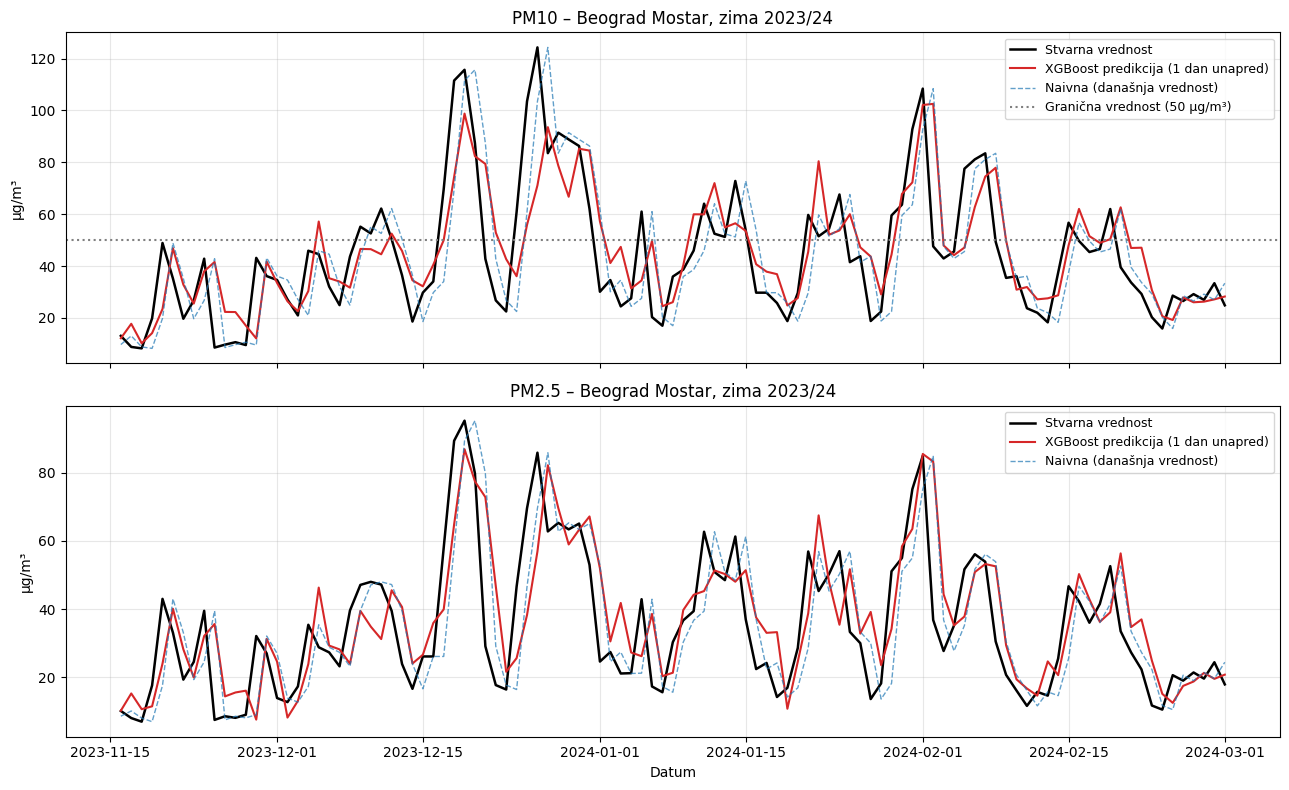

In [90]:
import matplotlib.pyplot as plt

STANICA = 'beograd mostar'
POCETAK, KRAJ = '2023-11-15', '2024-02-29'      # zimski period iz test skupa (grejna sezona)

fig, ose = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

for ax, (zagadjivac, podaci, atributi, cilj, granica) in zip(ose, [
        ('PM10',  podaci_model, atributi_model, 'cilj_h1',   50),
        ('PM2.5', podaci_pm25,  atributi_pm25,  'cilj25_h1', None)]):

    d = podaci[(podaci['Stanica'] == STANICA) & (podaci['Datum'] >= POCETAK) & (podaci['Datum'] <= KRAJ)].dropna(subset=[cilj]).copy()
    d['predikcija'] = (modeli_xgb[1] if zagadjivac == 'PM10' else modeli_xgb25[1]).predict(d[atributi])
    d['datum_cilja'] = d['Datum'] + pd.Timedelta(days=1)       # red za dan t predviđa dan t+1

    ax.plot(d['datum_cilja'], d[cilj], color='black', linewidth=1.8, label='Stvarna vrednost')
    ax.plot(d['datum_cilja'], d['predikcija'], color='tab:red', linewidth=1.5, label='XGBoost predikcija (1 dan unapred)')
    ax.plot(d['datum_cilja'], d[zagadjivac], color='tab:blue', linewidth=1, linestyle='--', alpha=0.7, label='Naivna (današnja vrednost)')
    if granica:
        ax.axhline(granica, color='gray', linestyle=':', label=f'Granična vrednost ({granica} µg/m³)')
    ax.set_title(f'{zagadjivac} – {STANICA.title()}, zima 2023/24')
    ax.set_ylabel('µg/m³')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right', fontsize=9)

ose[-1].set_xlabel('Datum')
plt.tight_layout()
plt.savefig('predikcija_vs_stvarno_zima.png', dpi=150)
plt.show()

### Slike za rad
Ove slike prikazuju podatke i ponašanje modela vizuelno: kako se koncentracije raspoređuju i menjaju kroz godinu, kako meteorološke promenljive koreliraju sa PM česticama, šta ostaje u rezidualima ARIMA modela i koliko XGBoost predikcija prati stvarne vrednosti tokom zime u poređenju sa naivnom prognozom. Crtaju se iz podataka ovog notebook-a (posle ispravke grešaka u Excel fajlovima) i koriste se u radu.

In [91]:
# SLIKE ZA RAD: ponovo crtamo slike iz rada sa ćiriličnim naslovima i oznakama i čuvamo ih u folderu 'slike_za_rad'
import os
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

os.makedirs('slike_za_rad', exist_ok=True)

# 1) Raspodele dnevnih koncentracija
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, pol in zip(axes, ['PM10', 'PM2.5']):
    vrednosti = finalni_skup[finalni_skup['Zagadjivac'] == pol]['Vrednost']
    ax.hist(vrednosti[vrednosti < 200], bins=60, color='steelblue', edgecolor='white')
    ax.set_title(f'Расподела дневних {pol} вредности')
    ax.set_xlabel('µg/m³')
    ax.set_ylabel('Број дана')
plt.tight_layout()
plt.savefig('slike_za_rad/raspodela.png', dpi=200)
plt.close()

# 2) Sezonalnost
finalni_skup['Datum_dt'] = pd.to_datetime(finalni_skup['Datum'])
finalni_skup['Mesec'] = finalni_skup['Datum_dt'].dt.month
mesecni_prosek = finalni_skup.groupby(['Zagadjivac', 'Mesec'])['Vrednost'].mean().unstack(level=0)
fig, ax = plt.subplots(figsize=(9, 4))
mesecni_prosek.plot(ax=ax, marker='o')
ax.set_xlabel('Месец')
ax.set_ylabel('µg/m³')
ax.axvspan(10, 12, alpha=0.1, color='red', label='грејна сезона')
ax.axvspan(1, 3, alpha=0.1, color='red')
ax.set_xticks(range(1, 13))
ax.legend()
plt.tight_layout()
plt.savefig('slike_za_rad/sezonalnost.png', dpi=200)
plt.close()

# 3) Korelaciona matrica
nazivi = ['PM10', 'PM2.5', 'Температура', 'Падавине', 'Брзина ветра', 'Правац ветра', 'Влажност', 'Притисак']
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(korelacije, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(nazivi)))
ax.set_yticks(range(len(nazivi)))
ax.set_xticklabels(nazivi, rotation=45, ha='right')
ax.set_yticklabels(nazivi)
for i in range(len(nazivi)):
    for j in range(len(nazivi)):
        ax.text(j, i, f'{korelacije.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im)
plt.tight_layout()
plt.savefig('slike_za_rad/korelacije.png', dpi=200)
plt.close()

# 4) ACF reziduala
fig, ose = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
plot_acf(rezidui_stari, lags=30, ax=ose[0], title='АЦФ резидуала: ARIMA(1,1,1)')
plot_acf(rezidui_novi, lags=30, ax=ose[1], title=f'АЦФ резидуала: ARIMA({najbolji_p},0,{najbolji_q})')
for ax in ose:
    ax.set_xlabel('Кашњење (дани)')
plt.tight_layout()
plt.savefig('slike_za_rad/acf.png', dpi=200)
plt.close()

# 5) Predikcija i stvarne vrednosti, Beograd Mostar, zima 2023/24 (izabrani XGBoost: početni parametri)
STANICA = 'beograd mostar'
POCETAK, KRAJ = '2023-11-15', '2024-02-29'
fig, ose = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, (zagadjivac, podaci, atributi, cilj, granica) in zip(ose, [
        ('PM10',  podaci_model, atributi_model, 'cilj_h1',   50),
        ('PM2.5', podaci_pm25,  atributi_pm25,  'cilj25_h1', None)]):
    d = podaci[(podaci['Stanica'] == STANICA) & (podaci['Datum'] >= POCETAK) & (podaci['Datum'] <= KRAJ)].dropna(subset=[cilj]).copy()
    d['predikcija'] = (modeli_xgb[1] if zagadjivac == 'PM10' else modeli_xgb25[1]).predict(d[atributi])
    d['datum_cilja'] = d['Datum'] + pd.Timedelta(days=1)
    ax.plot(d['datum_cilja'], d[cilj], color='black', linewidth=1.8, label='Стварна вредност')
    ax.plot(d['datum_cilja'], d['predikcija'], color='tab:red', linewidth=1.5, label='XGBoost предикција (1 дан унапред)')
    ax.plot(d['datum_cilja'], d[zagadjivac], color='tab:blue', linewidth=1, linestyle='--', alpha=0.7, label='Наивна (данашња вредност)')
    if granica:
        ax.axhline(granica, color='gray', linestyle=':', label=f'Гранична вредност ({granica} µg/m³)')
    ax.set_title(f'{zagadjivac} – Београд Мостар, зима 2023/24')
    ax.set_ylabel('µg/m³')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right', fontsize=9)
ose[-1].set_xlabel('Датум')
plt.tight_layout()
plt.savefig('slike_za_rad/predikcija.png', dpi=200)
plt.close()

print('Gotovo. Slike su u folderu slike_za_rad:', os.listdir('slike_za_rad'))

Gotovo. Slike su u folderu slike_za_rad: ['acf.png', 'korelacije.png', 'predikcija.png', 'raspodela.png', 'sezonalnost.png']
